In [1]:
# source .venv-bt/bin/activate
#!pip install pyarrow==25.0.1
#!pip install "vectorbt[rust]==1.1.2"

In [2]:
import os
import gc
import ast
import sys
import json
import traceback
import numpy as np
import pandas as pd
import vectorbt as vbt
from numba import njit
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from importlib.metadata import version
from datetime import datetime, timezone
from vectorbt.portfolio import nb as pnb
from vectorbt.utils.math_ import is_close_nb
from vectorbt.portfolio.enums import Direction, SizeType, OrderStatus, OrderSide

In [3]:
# paleta de colores
PRINCIPAL = "#940028"
BLANCO = "#FFFFFF"
GRIS = "#D9D9D9"
NEGRO = "#000000"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "figure.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "legend.title_fontsize": 11,
    "figure.facecolor": BLANCO,
    "axes.facecolor": BLANCO,
    "text.color": NEGRO,
    "axes.labelcolor": NEGRO,
    "xtick.color": NEGRO,
    "ytick.color": NEGRO,
    "lines.linewidth": 1.6,
    "savefig.dpi": 300,
    "savefig.facecolor": BLANCO,
})

In [4]:
TOTAL_GRID = [126, 189, 252, 315, 378]
SKIP_GRID = [5, 10, 21, 42, 63]
H_GRID = [5, 10, 21, 42, 63]

BT_LONG_PCT = 1.0
BT_SHORT_PCT = 1.0
BT_INITIAL_NAV = 1.0
BT_FEES = 0.000605

INPUT = Path("outputs")
FACTOR_COLUMNS = ["Mkt-RF", "SMB", "HML", "RF"]
COEFFICIENT_COLUMNS = ["alpha", "beta_mkt", "beta_smb", "beta_hml"]

EXPECTED_RUNS = len(TOTAL_GRID) * len(SKIP_GRID) * len(H_GRID)
assert EXPECTED_RUNS == 125

RUN_ROOT = INPUT / "bt-runs-all"
BATCHES = {
    "residual": RUN_ROOT / "residual",
    "classic": RUN_ROOT / "classic",
}
SIGNAL_DESCRIPTIONS = {
    "residual": "momentum residual",
    "classic": "momentum clásico",
}

batch_metrics = {}
wf_results = {}

SIGNAL_KIND = "residual"
BATCH = BATCHES[SIGNAL_KIND]

In [5]:
def now():
    return datetime.now(timezone.utc).isoformat()

def atomic_json(path, data):
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", encoding="utf-8") as f:
        json.dump(
            data,
            f,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        )
        f.flush()
        os.fsync(f.fileno())
    temporary.replace(path)

def append_event(path, data):
    with path.open("a", encoding="utf-8") as f:
        f.write(
            json.dumps(
                data,
                ensure_ascii=False,
                allow_nan=False,
            ) + "\n"
        )
        f.flush()
        os.fsync(f.fileno())

def bt_dates(index):
    dates = pd.DatetimeIndex(pd.to_datetime(index))
    if (
        dates.hasnans
        or dates.tz is not None
        or not dates.equals(dates.normalize())
    ):
        raise ValueError("Fechas inválidas, intradía o con timezone")
    return dates

def bt_column(frame, column):
    values = pd.to_numeric(
        frame[column], errors="raise"
    ).astype(float)
    values.index = bt_dates(frame.index)
    values = values.replace([np.inf, -np.inf], np.nan)
    if values.groupby(level=0).nunique().gt(1).any():
        raise ValueError(f"Duplicados contradictorios: {column}")
    return (
        values.groupby(level=0, sort=True)
        .first()
        .rename(column)
    )

def prepare_total_return(prices, problem_dates):
    total_return = (
        pd.to_numeric(prices["Total Return"], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .groupby(level=0, sort=True)
        .first()
        .rename("Total Return")
    )
    close = (
        pd.to_numeric(prices["Close Price"], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .groupby(level=0, sort=True)
        .first()
    )
    price_return = close.pct_change(fill_method=None).mul(100)
    imputed = (
        total_return.isna()
        & total_return.index.isin(problem_dates)
        & price_return.notna()
    )
    total_return.loc[imputed] = price_return.loc[imputed]
    return total_return

def bt_price_marks(prices, calendar, problem_dates):
    calendar = bt_dates(calendar)
    if not calendar.is_unique or not calendar.is_monotonic_increasing:
        raise ValueError("Calendario duplicado o desordenado")
    problem_dates = bt_dates(problem_dates)
    tr = bt_column(prices, "Total Return")
    close = bt_column(prices, "Close Price")
    opening = bt_column(prices, "Open Price")
    dates = (
        tr.index.union(close.index)
        .union(opening.index)
        .union(calendar)
        .sort_values()
    )
    tr = tr.reindex(dates)
    close = close.reindex(dates).where(lambda x: x.gt(0))
    opening = opening.reindex(dates).where(lambda x: x.gt(0))
    reconstructed = close.pct_change(fill_method=None).mul(100)
    repair = (
        tr.isna()
        & dates.isin(problem_dates)
        & reconstructed.notna()
    )
    tr.loc[repair] = reconstructed.loc[repair]
    if tr.le(-100).any():
        raise ValueError("TR <= -100% requiere política adicional")
    ratio = opening.div(close).ffill()
    started = close.notna().cummax()
    increments = (
        1 + tr.fillna(0).div(100)
    ).where(started, 1.0)
    synthetic_close = 100 * increments.cumprod()
    mark = (
        synthetic_close * ratio
    ).where(close.notna() & started)
    valid_marks = mark.dropna()
    if (
        not np.isfinite(valid_marks).all()
        or valid_marks.le(0).any()
    ):
        raise ValueError("Índice sintético inválido")
    return pd.DataFrame({
        "mark": mark,
        "proxy": mark.notna() & opening.isna(),
        "zero_tr": tr.isna(),
    }).reindex(calendar)

def load_common_once():
    fama_french = pd.read_parquet(
        INPUT / "factors" / "fama_french_3_daily.parquet"
    )
    snapshots = pd.read_parquet(
        INPUT / "constituents" / "spx_constituents.parquet"
    )[["Date", "RIC"]].copy()
    snapshots["Date"] = bt_dates(snapshots["Date"])
    if (
        snapshots.empty
        or snapshots["RIC"].isna().any()
        or not snapshots["RIC"].map(
            lambda x: isinstance(x, str) and bool(x.strip())
        ).all()
    ):
        raise ValueError("Snapshots o RIC inválidos")
    ff_dates = bt_dates(fama_french.index)
    if (
        not ff_dates.is_unique
        or not ff_dates.is_monotonic_increasing
    ):
        raise ValueError(
            "Fechas de Fama–French duplicadas o desordenadas"
        )
    fama_french.index = ff_dates
    fama_french[FACTOR_COLUMNS] = (
        fama_french[FACTOR_COLUMNS]
        .apply(pd.to_numeric, errors="raise")
    )
    calendar = ff_dates[
        (ff_dates >= snapshots["Date"].min())
        & (ff_dates <= snapshots["Date"].max())
    ]
    if calendar.empty or snapshots["Date"].min() > calendar[0]:
        raise ValueError("Calendario vacío o falta snapshot inicial")
    membership = (
        pd.crosstab(snapshots["Date"], snapshots["RIC"])
        .gt(0)
        .sort_index()
        .reindex(calendar, method="ffill")
    )
    if membership.isna().any().any():
        raise ValueError("Pertenencia desconocida")
    membership = membership.astype(bool)
    rics = sorted(membership.columns)
    membership = membership.reindex(columns=rics)
    names = [f"{ric.replace('/', '_')}.parquet" for ric in rics]
    if (
        len(set(names)) != len(names)
        or any("\\" in n or Path(n).name != n for n in names)
    ):
        raise ValueError("Nombres de archivo inválidos o duplicados")
    raw = {}
    return_counts = pd.Series(0, index=calendar, dtype=int)
    for ric, name in zip(rics, names):
        path = INPUT / "equity" / name
        if not path.exists():
            continue
        frame = pd.read_parquet(
            path,
            columns=["Total Return", "Close Price", "Open Price"],
        )
        raw[ric] = frame
        tr = (
            pd.to_numeric(frame["Total Return"], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .groupby(level=0, sort=True)
            .first()
        )
        valid_dates = (
            tr.index[tr.notna()]
            .intersection(calendar)
            .unique()
        )
        member_dates = valid_dates[
            membership.loc[valid_dates, ric].to_numpy()
        ]
        return_counts.loc[member_dates] += 1
    problem_dates = calendar[
        membership.sum(axis=1).gt(0)
        & return_counts.eq(0)
    ]
    fresh = pd.DataFrame(np.nan, index=calendar, columns=rics)
    quality = []
    signal_inputs = {}
    classic_inputs = {}
    for ric, name in zip(rics, names):
        missing_price = ric not in raw
        marks = (
            bt_price_marks(raw[ric], calendar, problem_dates)
            if not missing_price else
            pd.DataFrame(
                {
                    "mark": np.nan,
                    "proxy": False,
                    "zero_tr": True,
                },
                index=calendar,
            )
        )
        fresh[ric] = marks["mark"]
        coefficient_path = INPUT / "regressions" / name
        missing_coefficients = not coefficient_path.exists()
        quality.append(dict(
            ric=ric,
            missing_price_file=missing_price,
            missing_coefficient_file=missing_coefficients,
            missing_marks=int(marks["mark"].isna().sum()),
            proxy_marks=int(marks["proxy"].sum()),
            zero_tr_dates=int(marks["zero_tr"].sum()),
        ))
        if not missing_price:
            prices = raw[ric].sort_index()
            data = (
                fama_french
                .loc[prices.index.min():prices.index.max()]
                .join(
                    prepare_total_return(prices, problem_dates),
                    how="left",
                    validate="one_to_one",
                )
            )

            # El clásico no requiere coeficientes de regresión.
            classic_inputs[ric] = data

            if SIGNAL_KIND == "residual" and not missing_coefficients:
                coefficients = pd.read_parquet(
                    coefficient_path
                ).sort_index()
                coefficients.index = bt_dates(coefficients.index)

                if not coefficients.index.is_unique:
                    raise ValueError(f"Coeficientes duplicados: {ric}")

                signal_inputs[ric] = (
                    data,
                    coefficients[COEFFICIENT_COLUMNS],
                )
    del raw
    return dict(
        calendar=calendar,
        membership=membership,
        close=fresh.ffill().fillna(1.0),
        allowed=np.isfinite(fresh.to_numpy()),
        quality=pd.DataFrame(quality),
        signal_inputs=signal_inputs,
        classic_inputs=classic_inputs,
        problem_dates=problem_dates,
    )

def rolling_sum(values, window):
    cumulative = np.concatenate((
        np.zeros_like(values[:1]),
        np.cumsum(values, axis=0),
    ))
    return cumulative[window:] - cumulative[:-window]

def calculate_signals(data, coefficients, total_window, skip_window):
    if (
        type(total_window) is not int
        or type(skip_window) is not int
        or skip_window < 0
        or total_window - skip_window <= 1
    ):
        raise ValueError("TOTAL/SKIP inválidos")
    TOTAL_WINDOW = total_window
    SIGNAL_WINDOW = total_window - skip_window
    if len(data) <= TOTAL_WINDOW:
        return pd.DataFrame()
    factors = data[FACTOR_COLUMNS].to_numpy(dtype=float)
    z = np.column_stack((
        data["Total Return"].to_numpy(dtype=float) - factors[:, 3],
        factors[:, :3],
    ))
    complete = np.isfinite(z).all(axis=1)
    z[~complete] = 0.0
    eligibility = rolling_sum(
        complete.astype(np.int16),
        TOTAL_WINDOW,
    )
    sums = rolling_sum(z, SIGNAL_WINDOW)
    cross_products = rolling_sum(
        z[:, :, None] * z[:, None, :],
        SIGNAL_WINDOW,
    )
    formation = np.arange(TOTAL_WINDOW, len(data))
    window = formation - TOTAL_WINDOW
    coefficient_date = formation
    beta = (
        coefficients[COEFFICIENT_COLUMNS]
        .reindex(data.index[coefficient_date])
        .to_numpy(dtype=float)
    )
    weights = np.column_stack((
        np.ones(len(beta)),
        -beta[:, 1:],
    ))
    q_sum = np.einsum(
        "ij,ij->i",
        weights,
        sums[window],
    )
    q_sum_squares = np.einsum(
        "ij,ijk,ik->i",
        weights,
        cross_products[window],
        weights,
    )
    residual_sum = q_sum
    centered_sum_squares = (
        q_sum_squares - q_sum**2 / SIGNAL_WINDOW
    )
    residual_std = np.sqrt(
        np.maximum(centered_sum_squares, 0.0)
        / (SIGNAL_WINDOW - 1)
    )
    valid = (
        (eligibility[window] == TOTAL_WINDOW)
        & np.isfinite(beta[:, 1:]).all(axis=1)
        & np.isfinite(residual_sum)
        & np.isfinite(residual_std)
        & (residual_std > 0)
    )
    return pd.DataFrame({
        "coefficient_date": data.index[coefficient_date[valid]],
        "residual_momentum": (
            residual_sum[valid] / residual_std[valid]
        ),
    }, index=data.index[formation[valid]])

def calculate_classic_signals(data, total_window, skip_window):
    if (
        type(total_window) is not int
        or type(skip_window) is not int
        or skip_window < 0
        or total_window - skip_window <= 1
    ):
        raise ValueError("TOTAL/SKIP inválidos")
    if len(data) <= total_window:
        return pd.DataFrame(columns=["classic_momentum"])
    returns = data["Total Return"].to_numpy(dtype=float) / 100
    complete = np.isfinite(returns) & (returns > -1)
    log_gross = np.zeros(len(returns), dtype=float)
    log_gross[complete] = np.log1p(returns[complete])
    eligibility = rolling_sum(
        complete.astype(np.int16),
        total_window,
    )
    log_sums = rolling_sum(
        log_gross,
        total_window - skip_window,
    )
    formation = np.arange(total_window, len(data))
    window = formation - total_window
    valid = eligibility[window] == total_window
    momentum = np.expm1(log_sums[window])
    return pd.DataFrame(
        {"classic_momentum": momentum[valid] * 100},
        index=data.index[formation[valid]],
    )

def signal_matrix(common, total_window, skip_window):
    if SIGNAL_KIND not in ("residual", "classic"):
        raise ValueError("SIGNAL_KIND inválido")
    classic = SIGNAL_KIND == "classic"
    inputs = (
        common["classic_inputs"]
        if classic else common["signal_inputs"]
    )
    column = (
        "classic_momentum"
        if classic else "residual_momentum"
    )
    signals = pd.DataFrame(
        np.nan,
        index=common["calendar"],
        columns=common["membership"].columns,
    )
    for ric, item in inputs.items():
        if classic:
            result = calculate_classic_signals(
                item,
                total_window,
                skip_window,
            )
        else:
            data, coefficients = item
            result = calculate_signals(
                data,
                coefficients,
                total_window,
                skip_window,
            )
        if not result.empty:
            signals[ric] = result[column].reindex(
                common["calendar"]
            )
    return signals

def bt_prepare_weights(
    calendar,
    membership,
    signals,
    h,
    long_pct=BT_LONG_PCT,
    short_pct=BT_SHORT_PCT,
):
    if (
        not isinstance(h, int)
        or h < 1
        or len(calendar) == 0
        or not calendar.is_unique
        or not calendar.is_monotonic_increasing
    ):
        raise ValueError("Horizonte o calendario inválido")
    if (
        not np.isfinite(long_pct)
        or not np.isfinite(short_pct)
        or not 0 <= long_pct <= 1
        or not 0 <= short_pct <= 1
        or long_pct == short_pct == 0
    ):
        raise ValueError(
            "Cada lado debe estar entre 0 y 1; al menos uno debe ser positivo"
        )
    if (
        not signals.index.equals(calendar)
        or not membership.index.equals(calendar)
        or not signals.columns.equals(membership.columns)
        or not signals.columns.is_unique
        or len(signals.columns) == 0
        or membership.isna().any().any()
    ):
        raise ValueError(
            "Señal y membership deben estar alineados y completos"
        )
    weights = pd.DataFrame(
        0.0,
        index=calendar,
        columns=signals.columns,
    )
    censored = []
    for t in range(len(calendar)):
        candidates = signals.iloc[t].where(
            membership.iloc[t]
        ).dropna()
        if not np.isfinite(candidates.to_numpy()).all():
            raise ValueError("Señal no finita")
        ranked = (
            candidates.rename("signal")
            .rename_axis("ric")
            .reset_index()
            .sort_values(["signal", "ric"])
        )
        if len(ranked) < 10:
            continue
        groups = np.array_split(ranked["ric"].to_numpy(), 10)
        entry_i = t + 1
        if entry_i + h >= len(calendar):
            censored.append(dict(
                formation_date=calendar[t],
                reason="holding_incompleto_al_final",
                candidates=len(ranked),
                long_count=len(groups[-1]),
                short_count=len(groups[0]),
            ))
            continue
        weights.loc[calendar[entry_i], groups[0]] = (
            -short_pct / (h * len(groups[0]))
        )
        weights.loc[calendar[entry_i], groups[-1]] = (
            long_pct / (h * len(groups[-1]))
        )
    active = weights.ne(0).any(axis=1)
    np.testing.assert_allclose(
        weights.clip(lower=0).sum(axis=1)[active],
        long_pct / h,
    )
    np.testing.assert_allclose(
        weights.clip(upper=0).sum(axis=1)[active],
        -short_pct / h,
    )
    assert not weights.iloc[0].any()
    assert not weights.iloc[
        max(0, len(calendar) - h):
    ].any().any()
    return weights, pd.DataFrame(
        censored,
        columns=[
            "formation_date",
            "reason",
            "candidates",
            "long_count",
            "short_count",
        ],
    )

@njit
def bt_pre_segment_nb(
    c,
    weights,
    allowed,
    cohort_units,
    planned,
    order_values,
    size_types,
    directions,
    pretrade_nav,
    h,
):
    # Actualizar todos los marks antes de calcular el NAV común.
    for col in range(c.from_col, c.to_col):
        c.last_val_price[col] = c.close[c.i, col]
    value = pnb.get_group_value_ctx_nb(c)
    if not np.isfinite(value) or value <= 0.0:
        raise ValueError("NAV pretrade no positivo o no finito")
    pretrade_nav[c.i] = value
    for col in range(c.from_col, c.to_col):
        exit_units = 0.0
        if c.i >= h:
            exit_units = -cohort_units[c.i - h, col]
        entry_units = 0.0
        if allowed[c.i, col]:
            entry_units = (
                weights[c.i, col] * value / c.close[c.i, col]
            )
            if is_close_nb(entry_units, 0.0):
                entry_units = 0.0
        cohort_units[c.i, col] = entry_units
        net_units = exit_units + entry_units
        if is_close_nb(net_units, 0.0):
            net_units = 0.0
        planned[col] = net_units
    pnb.sort_call_seq_nb(
        c,
        planned,
        size_types,
        directions,
        order_values,
        ctx_select=False,
    )
    return (planned,)

@njit
def bt_order_nb(c, planned, fees):
    size = planned[c.col]
    if size == 0.0:
        return pnb.order_nothing_nb()
    return pnb.order_nb(
        size=size,
        price=c.close[c.i, c.col],
        size_type=SizeType.Amount,
        direction=Direction.Both,
        fees=fees,
        fixed_fees=0.0,
        slippage=0.0,
        lock_cash=False,
        allow_partial=False,
        raise_reject=True,
        reject_prob=0.0,
        min_size=0.0,
        max_size=np.inf,
        size_granularity=np.nan,
    )

@njit
def bt_post_order_nb(c, planned):
    if c.order_result.status == OrderStatus.Rejected:
        raise ValueError("Orden rechazada")
    if (
        planned[c.col] != 0.0
        and c.order_result.status != OrderStatus.Filled
    ):
        raise ValueError(
            "Orden no cero no ejecutada; revisar tolerancias"
        )

def bt_single_group(values, calendar):
    arr = np.asarray(values, dtype=float)
    if arr.size != len(calendar):
        raise AssertionError("Se esperaba un único grupo compartido")
    return arr.reshape(len(calendar))

def bt_simulate(common, weights, h, stop_i):
    full_calendar = common["calendar"]
    if (
        type(h) is not int
        or h < 1
        or not 0 <= stop_i < len(full_calendar)
    ):
        raise ValueError("Horizonte/corte inválido")
    if (
        not weights.index.equals(full_calendar)
        or not weights.columns.equals(common["close"].columns)
    ):
        raise ValueError(
            "Preparar weights contra todo el calendario original"
        )
    calendar = full_calendar[:stop_i + 1]
    close = common["close"].iloc[:stop_i + 1]
    allowed = common["allowed"][:stop_i + 1]
    w = weights.iloc[:stop_i + 1].to_numpy()
    shape = close.shape
    units = np.zeros(shape, dtype=np.float64)
    pretrade_nav = np.full(shape[0], np.nan)
    pf = vbt.Portfolio.from_order_func(
        close,
        bt_order_nb,
        BT_FEES,
        pre_segment_func_nb=bt_pre_segment_nb,
        pre_segment_args=(
            w,
            allowed,
            units,
            np.zeros(shape[1]),
            np.zeros(shape[1]),
            np.full(shape[1], SizeType.Amount, dtype=np.int64),
            np.full(shape[1], Direction.Both, dtype=np.int64),
            pretrade_nav,
            h,
        ),
        post_order_func_nb=bt_post_order_nb,
        row_wise=True,
        cash_sharing=True,
        group_by=True,
        engine="rust",
        update_value=False,
        init_cash=BT_INITIAL_NAV,
        call_seq="default",
        freq="1D",
        ffill_val_price=True,
    )
    daily = pd.DataFrame({
        "nav": bt_single_group(pf.value(), calendar),
        "cash": bt_single_group(pf.cash(), calendar),
        "return_net": bt_single_group(pf.returns(), calendar),
        "pretrade_nav": pretrade_nav,
    }, index=calendar).rename_axis("date")
    entered = np.any(units != 0.0, axis=1)
    active = np.cumsum(entered.astype(np.int64))
    active[h:] -= np.cumsum(
        entered.astype(np.int64)
    )[:-h]
    daily["cohort_entered"] = entered
    daily["active_cohort_slots_post"] = active
    orders = pd.DataFrame.from_records(
        pf.order_records.copy()
    )
    orders["date"] = calendar.take(
        orders["idx"].to_numpy(dtype=int)
    )
    orders["RIC"] = close.columns.take(
        orders["col"].to_numpy(dtype=int)
    )
    orders["signed_units"] = np.where(
        orders["side"].eq(OrderSide.Buy),
        orders["size"],
        -orders["size"],
    )
    rows, cols = np.nonzero(units)
    cohorts = pd.DataFrame({
        "RIC": close.columns.take(cols),
        "formation_date": full_calendar.take(rows - 1),
        "entry_i": rows,
        "expiry_i": rows + h,
        "entry_date": full_calendar.take(rows),
        "expiry_date": full_calendar.take(rows + h),
        "units": units[rows, cols],
        "entry_nav": pretrade_nav[rows],
        "entry_mark": close.to_numpy()[rows, cols],
        "entry_weight": w[rows, cols],
        "units_per_entry_nav": (
            units[rows, cols] / pretrade_nav[rows]
        ),
        "units_per_initial_nav": (
            units[rows, cols] / BT_INITIAL_NAV
        ),
    })
    return dict(
        pf=pf,
        daily=daily,
        orders=orders,
        cohorts=cohorts,
        units=units,
        weights=w,
        close=close,
        allowed=allowed,
        h=h,
    )

def reconstruct_state(
    cohorts,
    daily,
    orders,
    marks,
    date,
    phase="after_open",
    new_nav=None,
):
    date = pd.Timestamp(date)
    if (
        phase not in ("before_open", "after_open")
        or date not in daily.index
    ):
        raise ValueError(
            "Fecha fuera del tramo simulado o phase inválido"
        )
    i = daily.index.get_loc(date)
    if phase == "before_open":
        active = (
            cohorts["entry_date"].lt(date)
            & cohorts["expiry_date"].ge(date)
        )
        cash = (
            BT_INITIAL_NAV
            if i == 0 else float(daily["cash"].iloc[i - 1])
        )
        nav = float(daily.loc[date, "pretrade_nav"])
        trades = orders.loc[orders["date"].lt(date)]
    else:
        active = (
            cohorts["entry_date"].le(date)
            & cohorts["expiry_date"].gt(date)
        )
        cash = float(daily.loc[date, "cash"])
        nav = float(daily.loc[date, "nav"])
        trades = orders.loc[orders["date"].le(date)]
    if not np.isfinite(nav) or nav <= 0:
        raise ValueError("NAV de referencia inválido")
    if new_nav is not None and (
        not np.isfinite(new_nav) or new_nav <= 0
    ):
        raise ValueError("Capital de destino inválido")
    scale = 1.0 if new_nav is None else float(new_nav) / nav
    current_marks = marks.loc[date]
    state = cohorts.loc[active].copy()
    state["mark"] = state["RIC"].map(current_marks)
    state["units_per_reference_nav"] = state["units"] / nav
    state["target_units"] = state["units"] * scale
    # Posición contable exacta según órdenes ejecutadas.
    positions = (
        trades.groupby("RIC")["signed_units"]
        .sum()
        .reindex(marks.columns, fill_value=0.0)
        .rename("units")
        .rename_axis("RIC")
        .reset_index()
    )
    positions["mark"] = positions["RIC"].map(current_marks)
    positions["units_per_reference_nav"] = (
        positions["units"] / nav
    )
    positions["target_units"] = positions["units"] * scale
    info = dict(
        date=date.isoformat(),
        phase=phase,
        reference_nav=nav,
        cash=cash,
        cash_per_reference_nav=cash / nav,
        scale=scale,
        target_cash=cash * scale,
        active_cohort_slots=int(state["entry_i"].nunique()),
        unit_type="synthetic_total_return_units",
    )
    return state, positions, info

def state_at(run_id, date, phase="after_open", new_nav=None):
    folder = BATCH / "runs" / run_id
    return reconstruct_state(
        pd.read_parquet(folder / "cohorts.parquet"),
        pd.read_parquet(folder / "daily.parquet"),
        pd.read_parquet(folder / "orders.parquet"),
        pd.read_parquet(BATCH / "common" / "marks.parquet"),
        date,
        phase,
        new_nav,
    )

def export_run(result, quality, censored, folder):
    result["daily"].to_parquet(folder / "daily.parquet")
    result["orders"].to_parquet(
        folder / "orders.parquet",
        index=False,
    )
    result["cohorts"].to_parquet(
        folder / "cohorts.parquet",
        index=False,
    )
    quality.to_parquet(
        folder / "quality.parquet",
        index=False,
    )
    censored.to_parquet(
        folder / "censored.parquet",
        index=False,
    )
    terminal = result["daily"].index[-1]
    for phase in ("before_open", "after_open"):
        cohorts, positions, info = reconstruct_state(
            result["cohorts"],
            result["daily"],
            result["orders"],
            result["close"],
            terminal,
            phase,
        )
        cohorts.to_parquet(
            folder / f"state-{phase}-cohorts.parquet",
            index=False,
        )
        positions.to_parquet(
            folder / f"state-{phase}-positions.parquet",
            index=False,
        )
        atomic_json(
            folder / f"state-{phase}.json",
            info,
        )

def common_metrics(completions, common):
    if any(
        result["warm_return_start"] is None
        for result in completions
    ):
        raise ValueError(
            "Alguna corrida nunca reunió H cohortes: "
            "no hay intervalo común calentado válido"
        )
    start = max(
        pd.Timestamp(result["warm_return_start"])
        for result in completions
    )
    end = common["calendar"][
        len(common["calendar"]) - max(H_GRID) - 1
    ]
    if start > end:
        raise ValueError("Intervalo común calentado vacío")
    index = common["calendar"][
        (common["calendar"] >= start)
        & (common["calendar"] <= end)
    ]
    rows = []
    for result in completions:
        daily = pd.read_parquet(
            BATCH / "runs" / result["run_id"] / "daily.parquet"
        ).loc[index]
        returns = daily["return_net"].to_numpy()
        assert np.isfinite(returns).all()
        assert (returns > -1).all()
        wealth = np.r_[
            1.0,
            np.cumprod(1.0 + returns),
        ]
        volatility = (
            float(np.std(returns, ddof=1))
            if len(returns) > 1 else 0.0
        )
        rows.append(dict(
            run_id=result["run_id"],
            total=result["total"],
            skip=result["skip"],
            h=result["h"],
            start=start,
            end=end,
            observations=len(returns),
            total_return=wealth[-1] - 1,
            annual_return=(
                wealth[-1] ** (252 / len(returns)) - 1
            ),
            annual_volatility=volatility * np.sqrt(252),
            sharpe_zero_rf=(
                float(
                    np.mean(returns)
                    / volatility
                    * np.sqrt(252)
                )
                if volatility > 0 else np.nan
            ),
            max_drawdown=float(np.min(
                wealth / np.maximum.accumulate(wealth) - 1
            )),
            min_active_cohort_slots=int(
                daily["active_cohort_slots_post"].min()
            ),
            days_with_fewer_than_h=int(
                daily["active_cohort_slots_post"]
                .lt(result["h"])
                .sum()
            ),
        ))
    metrics = pd.DataFrame(rows)
    metrics.to_parquet(
        BATCH / "metrics-common.parquet",
        index=False,
    )
    atomic_json(
        BATCH / "metrics-policy.json",
        dict(
            start=start.isoformat(),
            end=end.isoformat(),
            annualization=252,
            sharpe_rf=0,
            first_return="día siguiente a completar H cohortes",
            terminal="mínimo N-H-1; sin liquidación final",
        ),
    )
    return metrics

def run_batch():
    BATCH.mkdir(parents=True, exist_ok=False)
    manifest = dict(
        status="running",
        created_at=now(),
        updated_at=now(),
        expected_runs=EXPECTED_RUNS,
        completed_runs=0,
        total_grid=TOTAL_GRID,
        skip_grid=SKIP_GRID,
        h_grid=H_GRID,
        initial_nav=BT_INITIAL_NAV,
        long_pct=BT_LONG_PCT,
        short_pct=BT_SHORT_PCT,
        versions={},
        python=sys.version,
        fees=BT_FEES,
        slippage=0.0,
        signal_kind=SIGNAL_KIND,
        signal=SIGNAL_DESCRIPTIONS[SIGNAL_KIND],
        terminal_policy=(
            "weights sobre calendario completo N; "
            "simular hasta N-H-1 inclusive"
        ),
        unit_type="synthetic_total_return_units",
        completions_ledger="ledger.jsonl",
    )
    atomic_json(BATCH / "manifest.json", manifest)
    completions = []
    context = dict(phase="environment")
    try:
        manifest["versions"] = {
            package: version(package)
            for package in (
                "vectorbt",
                "numpy",
                "pandas",
                "numba",
                "pyarrow",
            )
        }
        atomic_json(BATCH / "manifest.json", manifest)
        context = dict(phase="load_common")
        common = load_common_once()
        if len(common["calendar"]) <= max(H_GRID) + 1:
            raise ValueError("Calendario demasiado corto")
        (BATCH / "common").mkdir()
        (BATCH / "signals").mkdir()
        (BATCH / "runs").mkdir()
        common["close"].rename_axis("date").to_parquet(
            BATCH / "common" / "marks.parquet"
        )
        pd.DataFrame(
            common["allowed"],
            index=common["calendar"],
            columns=common["close"].columns,
        ).rename_axis("date").to_parquet(
            BATCH / "common" / "allowed.parquet"
        )
        common["membership"].rename_axis("date").to_parquet(
            BATCH / "common" / "membership.parquet"
        )
        common["quality"].to_parquet(
            BATCH / "common" / "quality.parquet",
            index=False,
        )
        pd.DataFrame({
            "date": common["problem_dates"],
        }).to_parquet(
            BATCH / "common" / "problem-dates.parquet",
            index=False,
        )
        for total in TOTAL_GRID:
            for skip in SKIP_GRID:
                context = dict(
                    phase="signals",
                    total=total,
                    skip=skip,
                )
                signals = signal_matrix(common, total, skip)
                signals.rename_axis("formation_date").to_parquet(
                    BATCH / "signals"
                    / f"T{total:03d}-S{skip:02d}.parquet"
                )
                for BT_H in H_GRID:
                    run_id = (
                        f"T{total:03d}-S{skip:02d}-H{BT_H:02d}"
                    )
                    context = dict(
                        phase="backtest",
                        run_id=run_id,
                        total=total,
                        skip=skip,
                        h=BT_H,
                    )
                    append_event(
                        BATCH / "ledger.jsonl",
                        dict(
                            event="running",
                            at=now(),
                            **context,
                        ),
                    )
                    print(
                        f"[{len(completions) + 1}/{EXPECTED_RUNS}] "
                        f"{run_id}",
                        flush=True,
                    )
                    folder = BATCH / "runs" / run_id
                    folder.mkdir()
                    calendar = common["calendar"]
                    weights, censored = bt_prepare_weights(
                        calendar,
                        common["membership"],
                        signals,
                        h=BT_H,
                    )
                    stop_i = len(calendar) - BT_H - 1
                    result = bt_simulate(
                        common,
                        weights,
                        h=BT_H,
                        stop_i=stop_i,
                    )
                    quality = common["quality"].copy()
                    quality["signal_dates"] = (
                        signals.notna()
                        .sum()
                        .reindex(quality["ric"])
                        .to_numpy()
                    )
                    quality["selected_without_entry_mark"] = (
                        weights.iloc[:stop_i + 1]
                        .ne(0)
                        .to_numpy()
                        & ~common["allowed"][:stop_i + 1]
                    ).sum(axis=0)
                    export_run(
                        result,
                        quality,
                        censored,
                        folder,
                    )
                    warm = np.flatnonzero(
                        result["daily"][
                            "active_cohort_slots_post"
                        ].to_numpy() == BT_H
                    )
                    warm_return_i = (
                        int(warm[0]) + 1
                        if len(warm)
                        else len(result["daily"])
                    )
                    warm_return = (
                        calendar[warm_return_i].isoformat()
                        if warm_return_i < len(result["daily"])
                        else None
                    )
                    entries = result["cohorts"]["entry_i"]
                    last_actual = (
                        calendar[int(entries.max())].isoformat()
                        if len(entries) else None
                    )
                    metadata = dict(
                        run_id=run_id,
                        total=total,
                        skip=skip,
                        h=BT_H,
                        full_calendar_n=len(calendar),
                        terminal_i=stop_i,
                        terminal_date=calendar[stop_i].isoformat(),
                        last_entry_admitted_i=stop_i,
                        last_actual_entry_date=last_actual,
                        terminal_active_cohort_slots=int(
                            result["daily"][
                                "active_cohort_slots_post"
                            ].iloc[-1]
                        ),
                        warm_return_start=warm_return,
                        orders=len(result["orders"]),
                    )
                    atomic_json(
                        folder / "run.json",
                        dict(status="complete", **metadata),
                    )
                    completions.append(metadata)
                    append_event(
                        BATCH / "ledger.jsonl",
                        dict(
                            event="complete",
                            at=now(),
                            **metadata,
                        ),
                    )
                    manifest.update(
                        completed_runs=len(completions),
                        updated_at=now(),
                    )
                    atomic_json(
                        BATCH / "manifest.json",
                        manifest,
                    )
                    del result, weights, censored, quality
                    gc.collect()
                del signals
        context = dict(phase="metrics")
        metrics = common_metrics(completions, common)
        manifest.update(
            status="complete",
            updated_at=now(),
            completed_runs=len(completions),
        )
        atomic_json(BATCH / "manifest.json", manifest)
        del common
        gc.collect()
        return metrics
    except BaseException as error:
        failure = dict(
            at=now(),
            error_type=type(error).__name__,
            error=str(error),
            traceback=traceback.format_exc(),
            **context,
        )
        append_event(BATCH / "failures.jsonl", failure)
        manifest.update(
            status="failed",
            updated_at=now(),
            completed_runs=len(completions),
            failure=failure,
        )
        atomic_json(BATCH / "manifest.json", manifest)
        raise

In [6]:
# Ejecucion completa del lote residual
metrics_common = run_batch()
batch_metrics[SIGNAL_KIND] = metrics_common.copy(deep=True)

display(
    metrics_common.sort_values(["total", "skip", "h"])
)

[1/125] T126-S05-H05
[2/125] T126-S05-H10
[3/125] T126-S05-H21
[4/125] T126-S05-H42
[5/125] T126-S05-H63
[6/125] T126-S10-H05
[7/125] T126-S10-H10
[8/125] T126-S10-H21
[9/125] T126-S10-H42
[10/125] T126-S10-H63
[11/125] T126-S21-H05
[12/125] T126-S21-H10
[13/125] T126-S21-H21
[14/125] T126-S21-H42
[15/125] T126-S21-H63
[16/125] T126-S42-H05
[17/125] T126-S42-H10
[18/125] T126-S42-H21
[19/125] T126-S42-H42
[20/125] T126-S42-H63
[21/125] T126-S63-H05
[22/125] T126-S63-H10
[23/125] T126-S63-H21
[24/125] T126-S63-H42
[25/125] T126-S63-H63
[26/125] T189-S05-H05
[27/125] T189-S05-H10
[28/125] T189-S05-H21
[29/125] T189-S05-H42
[30/125] T189-S05-H63
[31/125] T189-S10-H05
[32/125] T189-S10-H10
[33/125] T189-S10-H21
[34/125] T189-S10-H42
[35/125] T189-S10-H63
[36/125] T189-S21-H05
[37/125] T189-S21-H10
[38/125] T189-S21-H21
[39/125] T189-S21-H42
[40/125] T189-S21-H63
[41/125] T189-S42-H05
[42/125] T189-S42-H10
[43/125] T189-S42-H21
[44/125] T189-S42-H42
[45/125] T189-S42-H63
[46/125] T189-S63-H

,run_id,total,skip,h,start,end,observations,total_return,annual_return,annual_volatility,sharpe_zero_rf,max_drawdown,min_active_cohort_slots,days_with_fewer_than_h
0,T126-S05-H05,126,5,5,2003-04-09,2026-03-30,5780,-0.603764,-0.039558,0.167720,-0.155939,-0.806428,5,0
1,T126-S05-H10,126,5,10,2003-04-09,2026-03-30,5780,-0.470183,-0.027315,0.164586,-0.085378,-0.764641,10,0
2,T126-S05-H21,126,5,21,2003-04-09,2026-03-30,5780,-0.244021,-0.012122,0.161241,0.005498,-0.672548,21,0
3,T126-S05-H42,126,5,42,2003-04-09,2026-03-30,5780,0.014174,0.000614,0.154680,0.081746,-0.582801,42,0
4,T126-S05-H63,126,5,63,2003-04-09,2026-03-30,5780,0.383899,0.014266,0.148764,0.169994,-0.472457,63,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,T378-S63-H05,378,63,5,2003-04-09,2026-03-30,5780,0.011413,0.000495,0.160051,0.083559,-0.682381,5,0
121,T378-S63-H10,378,63,10,2003-04-09,2026-03-30,5780,0.221478,0.008761,0.158642,0.134707,-0.659330,10,0
122,T378-S63-H21,378,63,21,2003-04-09,2026-03-30,5780,0.252797,0.009875,0.155947,0.141322,-0.648538,21,0
123,T378-S63-H42,378,63,42,2003-04-09,2026-03-30,5780,0.219934,0.008705,0.151800,0.133229,-0.637505,42,0


In [7]:
run_id = "T252-S21-H21"
daily = pd.read_parquet(
    BATCH / "runs" / run_id / "daily.parquet"
)
# Ejemplo: consultar la última fecha disponible.
# Luego podremos sustituirla por la primera fecha OOS de cada fold.
reference_date = daily.index[-1]
cohorts, positions, state_info = state_at(
    run_id,
    reference_date,
    phase="before_open",
    new_nav=1.0,
)
display(pd.Series(state_info))
display(cohorts)
display(
    positions.loc[positions["target_units"].ne(0)]
)

date                               2026-05-29T00:00:00
phase                                      before_open
reference_nav                                 0.737498
cash                                          0.693028
cash_per_reference_nav                          0.9397
scale                                         1.355935
target_cash                                     0.9397
active_cohort_slots                                 21
unit_type                 synthetic_total_return_units
dtype: object

,RIC,formation_date,entry_i,expiry_i,entry_date,expiry_date,units,entry_nav,entry_mark,entry_weight,units_per_entry_nav,units_per_initial_nav,mark,units_per_reference_nav,target_units
567533,ACN.N,2026-04-28,6619,6640,2026-04-29,2026-05-29,-3.791300e-07,0.673580,1692.044335,-0.000952,-5.628582e-07,-3.791300e-07,1714.636972,-5.140756e-07,-5.140756e-07
567534,ADBE.OQ,2026-04-28,6619,6640,2026-04-29,2026-05-29,-4.476517e-07,0.673580,1433.044306,-0.000952,-6.645858e-07,-4.476517e-07,1463.601912,-6.069866e-07,-6.069866e-07
567535,ADP.OQ,2026-04-28,6619,6640,2026-04-29,2026-05-29,-7.597435e-07,0.673580,844.370164,-0.000952,-1.127919e-06,-7.597435e-07,893.665384,-1.030163e-06,-1.030163e-06
567536,AJG.N,2026-04-28,6619,6640,2026-04-29,2026-05-29,-2.291812e-07,0.673580,2799.115284,-0.000952,-3.402436e-07,-2.291812e-07,2654.478549,-3.107549e-07,-3.107549e-07
567537,ALB.N,2026-04-28,6619,6640,2026-04-29,2026-05-29,2.192226e-07,0.673580,2985.990539,0.000972,3.254589e-07,2.192226e-07,2773.958276,2.972516e-07,2.972516e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
569565,WDAY.OQ,2026-05-27,6639,6660,2026-05-28,2026-06-29,-2.707205e-06,0.741321,260.792771,-0.000952,-3.651869e-06,-2.707205e-06,273.670158,-3.670794e-06,-3.670794e-06
569566,WDC.OQ,2026-05-27,6639,6660,2026-05-28,2026-06-29,3.376667e-08,0.741321,21335.483042,0.000972,4.554935e-08,3.376667e-08,21393.869409,4.578540e-08,4.578540e-08
569567,WELL.N,2026-05-27,6639,6660,2026-05-28,2026-06-29,1.137825e-07,0.741321,6331.622800,0.000972,1.534863e-07,1.137825e-07,6214.721285,1.542817e-07,1.542817e-07
569568,ZBRA.OQ,2026-05-27,6639,6660,2026-05-28,2026-06-29,-7.294463e-07,0.741321,967.884228,-0.000952,-9.839823e-07,-7.294463e-07,945.153468,-9.890818e-07,-9.890818e-07


,RIC,units,mark,units_per_reference_nav,target_units
0,A.N,-6.776264e-21,290.978089,-9.188173e-21,-9.188173e-21
2,AABA.OQ^J19,1.355253e-20,65.813765,1.837635e-20,1.837635e-20
3,AAL.OQ,-1.694066e-21,63.524914,-2.297043e-21,-2.297043e-21
4,AAP.N,2.117582e-22,507.729298,2.871304e-22,2.871304e-22
5,AAPL.OQ,4.301339e-22,40507.622141,5.832336e-22,5.832336e-22
...,...,...,...,...,...
1113,XYL.N,4.235165e-22,550.610210,5.742608e-22,5.742608e-22
1116,YUM.N,1.058791e-22,3218.494072,1.435652e-22,1.435652e-22
1119,ZBRA.OQ,-4.999725e-06,945.153468,-6.779302e-06,-6.779302e-06
1121,ZION.OQ,-4.235165e-21,174.816459,-5.742608e-21,-5.742608e-21


In [8]:
# Walkforward
wf_grid = pd.DataFrame([
    {
        "run_id": f"T{total:03d}-S{skip:02d}-H{h:02d}",
        "TOTAL": total,
        "SKIP": skip,
        "H": h,
    }
    for total in TOTAL_GRID
    for skip in SKIP_GRID
    for h in H_GRID
])
index = pd.read_parquet(
    BATCH / "common" / "marks.parquet",
    columns=[],
).index
wf_calendar = index[
    (index >= "2004-01-01")
    & (index < "2026-01-01")
]
wf_returns = np.empty(
    (len(wf_grid), len(wf_calendar)),
    dtype=float,
)
for j, run_id in enumerate(wf_grid["run_id"]):
    daily = pd.read_parquet(
        BATCH / "runs" / run_id / "daily.parquet",
        columns=["return_net"],
    )
    daily = daily.loc[
        (daily.index >= "2004-01-01")
        & (daily.index < "2026-01-01")
    ]
    if not daily.index.equals(wf_calendar):
        raise ValueError(f"Calendario distinto en {run_id}")
    values = daily["return_net"].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f"Retornos no finitos en {run_id}")
    wf_returns[j] = values
fold_rows = []
for number, year in enumerate(range(2004, 2024, 2), start=1):
    is_start = pd.Timestamp(f"{year}-01-01")
    oos_start = pd.Timestamp(f"{year + 2}-01-01")
    oos_end = pd.Timestamp(f"{year + 4}-01-01")
    is_dates = wf_calendar[
        (wf_calendar >= is_start)
        & (wf_calendar < oos_start)
    ]
    oos_dates = wf_calendar[
        (wf_calendar >= oos_start)
        & (wf_calendar < oos_end)
    ]
    if len(is_dates) < 2 or len(oos_dates) == 0:
        raise ValueError(f"Calendario insuficiente en fold {number}")
    fold_rows.append({
        "fold": number,
        "is_start": is_start,
        "is_end_exclusive": oos_start,
        "oos_start": oos_start,
        "oos_end_exclusive": oos_end,
        "is_first_date": is_dates[0],
        "is_last_date": is_dates[-1],
        "oos_first_date": oos_dates[0],
        "oos_last_date": oos_dates[-1],
        "n_is": len(is_dates),
        "n_oos": len(oos_dates),
    })
wf_folds = pd.DataFrame(fold_rows)
display(wf_folds)

,fold,is_start,is_end_exclusive,oos_start,oos_end_exclusive,is_first_date,is_last_date,oos_first_date,oos_last_date,n_is,n_oos
0,1,2004-01-01,2006-01-01,2006-01-01,2008-01-01,2004-01-02,2005-12-30,2006-01-03,2007-12-31,504,502
1,2,2006-01-01,2008-01-01,2008-01-01,2010-01-01,2006-01-03,2007-12-31,2008-01-02,2009-12-31,502,505
2,3,2008-01-01,2010-01-01,2010-01-01,2012-01-01,2008-01-02,2009-12-31,2010-01-04,2011-12-30,505,504
3,4,2010-01-01,2012-01-01,2012-01-01,2014-01-01,2010-01-04,2011-12-30,2012-01-03,2013-12-31,504,502
4,5,2012-01-01,2014-01-01,2014-01-01,2016-01-01,2012-01-03,2013-12-31,2014-01-02,2015-12-31,502,504
5,6,2014-01-01,2016-01-01,2016-01-01,2018-01-01,2014-01-02,2015-12-31,2016-01-04,2017-12-29,504,503
6,7,2016-01-01,2018-01-01,2018-01-01,2020-01-01,2016-01-04,2017-12-29,2018-01-02,2019-12-31,503,503
7,8,2018-01-01,2020-01-01,2020-01-01,2022-01-01,2018-01-02,2019-12-31,2020-01-02,2021-12-31,503,505
8,9,2020-01-01,2022-01-01,2022-01-01,2024-01-01,2020-01-02,2021-12-31,2022-01-03,2023-12-29,505,501
9,10,2022-01-01,2024-01-01,2024-01-01,2026-01-01,2022-01-03,2023-12-29,2024-01-02,2025-12-31,501,502


In [9]:
score_tables = []
winner_rows = []
for fold in wf_folds.itertuples(index=False):
    mask = (
        (wf_calendar >= fold.is_start)
        & (wf_calendar < fold.is_end_exclusive)
    )
    sample = wf_returns[:, mask]
    mean_daily = sample.mean(axis=1)
    std_daily = sample.std(axis=1, ddof=1)
    std_daily[np.ptp(sample, axis=1) == 0] = 0.0
    valid = (
        np.isfinite(mean_daily)
        & np.isfinite(std_daily)
        & (std_daily > 0)
    )
    sharpe = np.full(len(wf_grid), np.nan)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        sharpe[valid] = (
            mean_daily[valid]
            / std_daily[valid]
            * np.sqrt(252)
        )
    sharpe[~np.isfinite(sharpe)] = np.nan
    scores = wf_grid.copy()
    scores.insert(0, "fold", fold.fold)
    scores["n_obs"] = sample.shape[1]
    scores["mean_daily"] = mean_daily
    scores["std_daily"] = std_daily
    scores["sharpe_is"] = sharpe
    candidates = scores.loc[
        np.isfinite(scores["sharpe_is"])
    ]
    if candidates.empty:
        raise ValueError(
            f"Fold {fold.fold}: ningún candidato tiene Sharpe IS finito"
        )
    winner = candidates.sort_values(
        ["sharpe_is", "TOTAL", "SKIP", "H"],
        ascending=[False, True, True, True],
        kind="stable",
    ).iloc[0]
    score_tables.append(scores)
    winner_rows.append(winner.to_dict())
wf_is_scores = pd.concat(
    score_tables,
    ignore_index=True,
)
wf_selections = (
    pd.DataFrame(winner_rows)
    .merge(
        wf_folds,
        on="fold",
        validate="one_to_one",
    )
    .sort_values("fold")
    .reset_index(drop=True)
)
(BATCH / "walk-forward-2y-2y").mkdir(exist_ok=True)
wf_folds.to_parquet(
    BATCH / "walk-forward-2y-2y" / "folds.parquet",
    index=False,
)
wf_is_scores.to_parquet(
    BATCH / "walk-forward-2y-2y" / "is_scores.parquet",
    index=False,
)
wf_selections.to_parquet(
    BATCH / "walk-forward-2y-2y" / "selections.parquet",
    index=False,
)
display(
    wf_selections[[
        "fold",
        "run_id",
        "sharpe_is",
        "is_start",
        "is_end_exclusive",
        "oos_start",
        "oos_end_exclusive",
    ]]
)

,fold,run_id,sharpe_is,is_start,is_end_exclusive,oos_start,oos_end_exclusive
0,1,T252-S63-H21,2.107582,2004-01-01,2006-01-01,2006-01-01,2008-01-01
1,2,T126-S63-H21,1.699113,2006-01-01,2008-01-01,2008-01-01,2010-01-01
2,3,T126-S63-H05,-0.048645,2008-01-01,2010-01-01,2010-01-01,2012-01-01
3,4,T378-S42-H63,0.810520,2010-01-01,2012-01-01,2012-01-01,2014-01-01
4,5,T252-S63-H10,0.284387,2012-01-01,2014-01-01,2014-01-01,2016-01-01
5,6,T378-S63-H63,1.951426,2014-01-01,2016-01-01,2016-01-01,2018-01-01
6,7,T126-S63-H05,0.426544,2016-01-01,2018-01-01,2018-01-01,2020-01-01
7,8,T126-S63-H21,0.219828,2018-01-01,2020-01-01,2020-01-01,2022-01-01
8,9,T315-S63-H63,0.928510,2020-01-01,2022-01-01,2022-01-01,2024-01-01
9,10,T126-S63-H10,0.447869,2022-01-01,2024-01-01,2024-01-01,2026-01-01


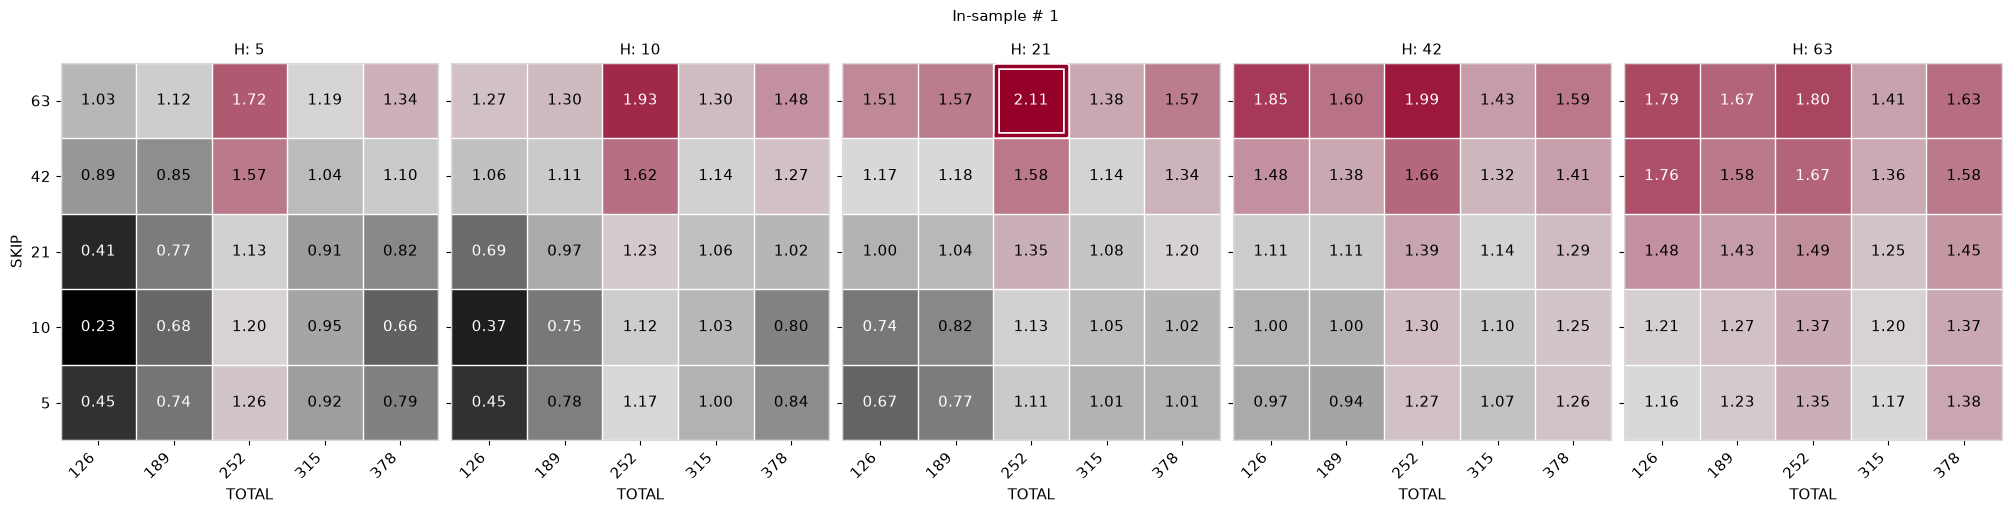

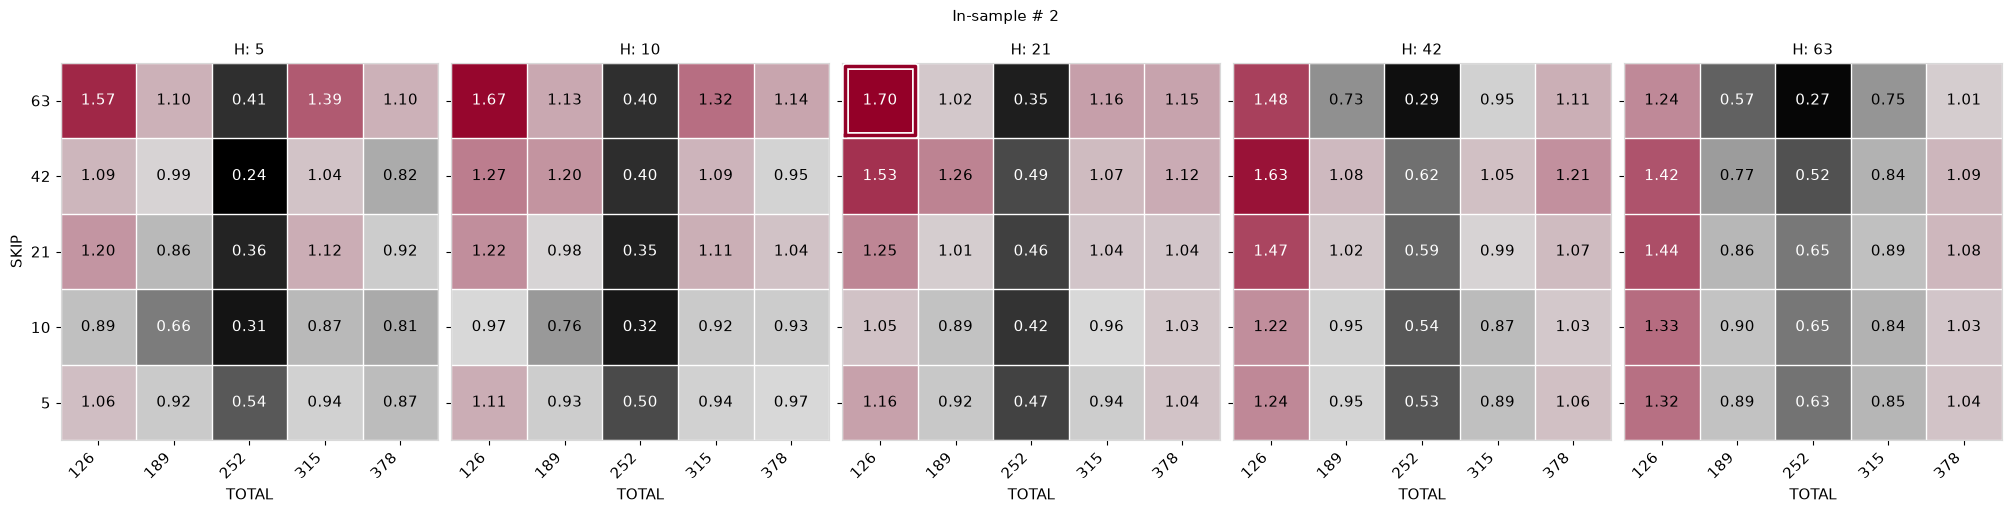

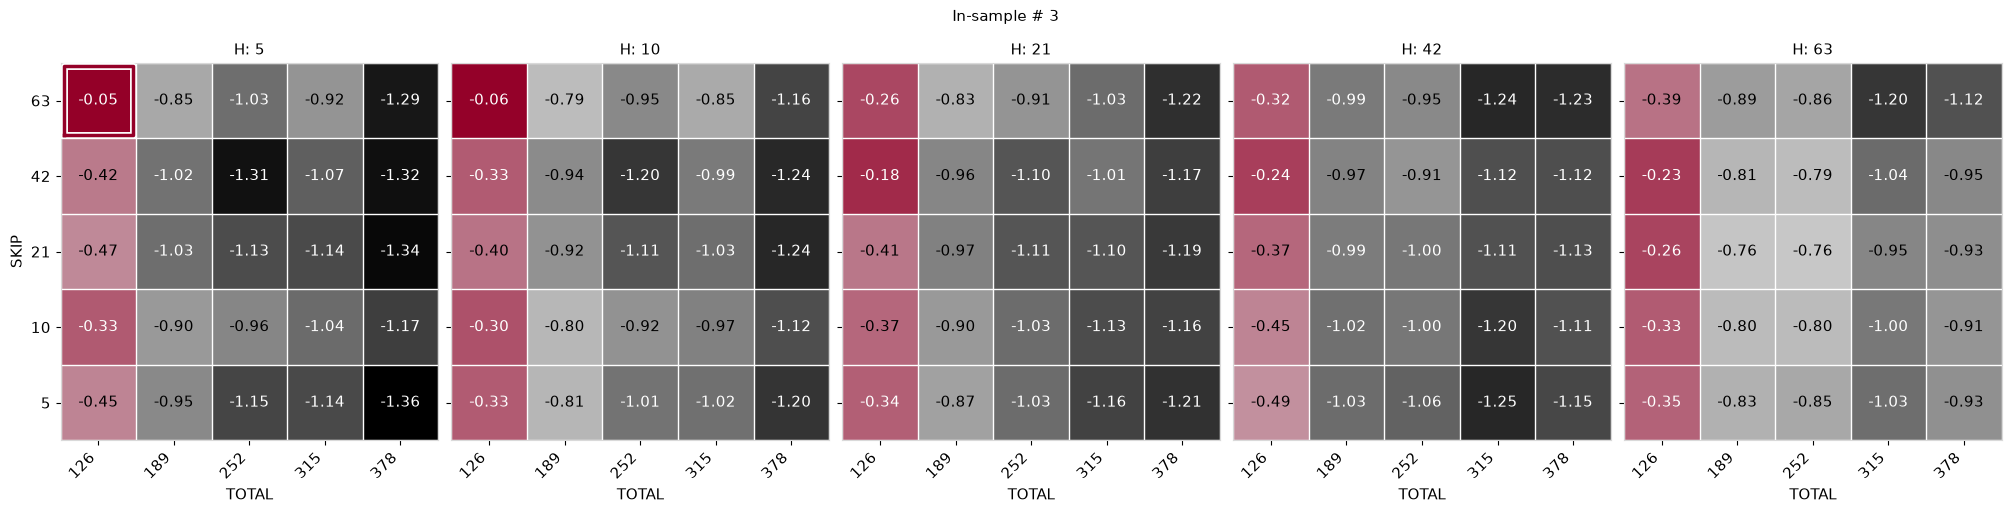

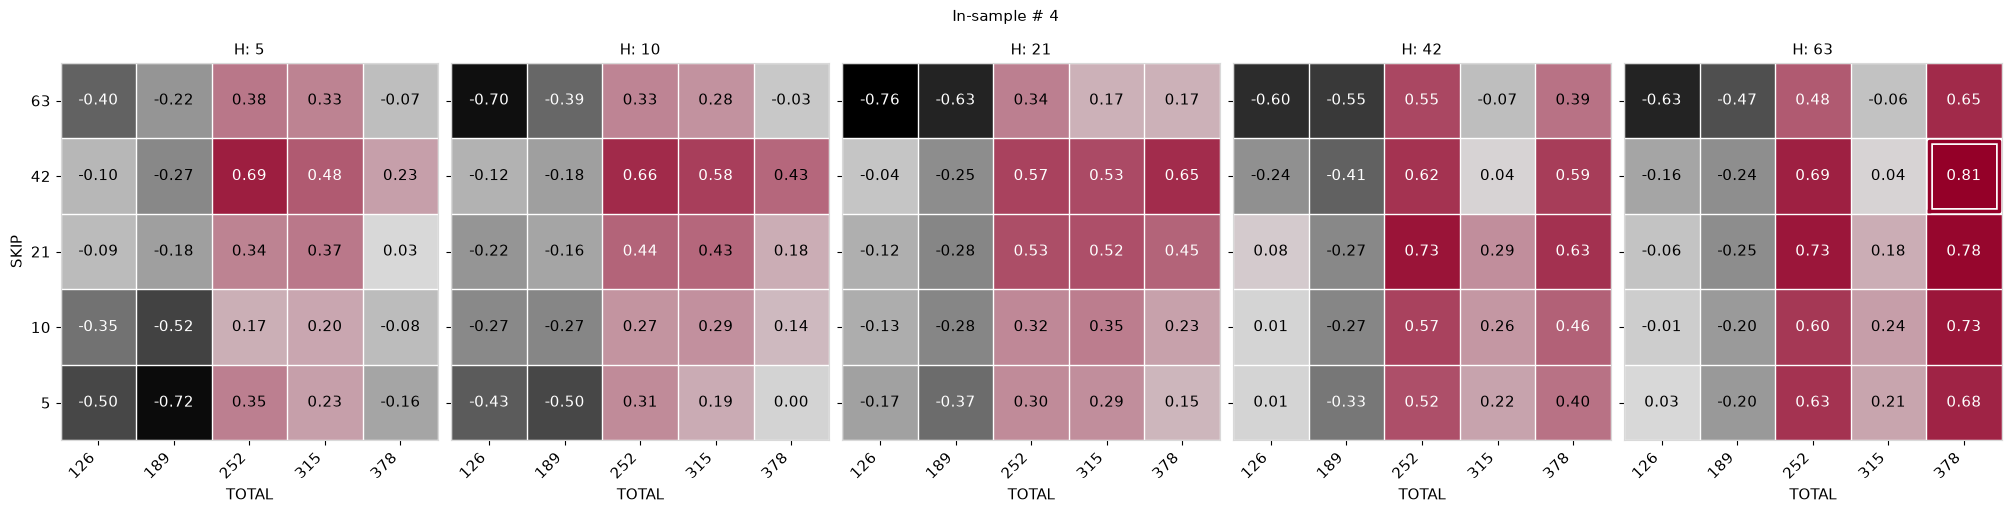

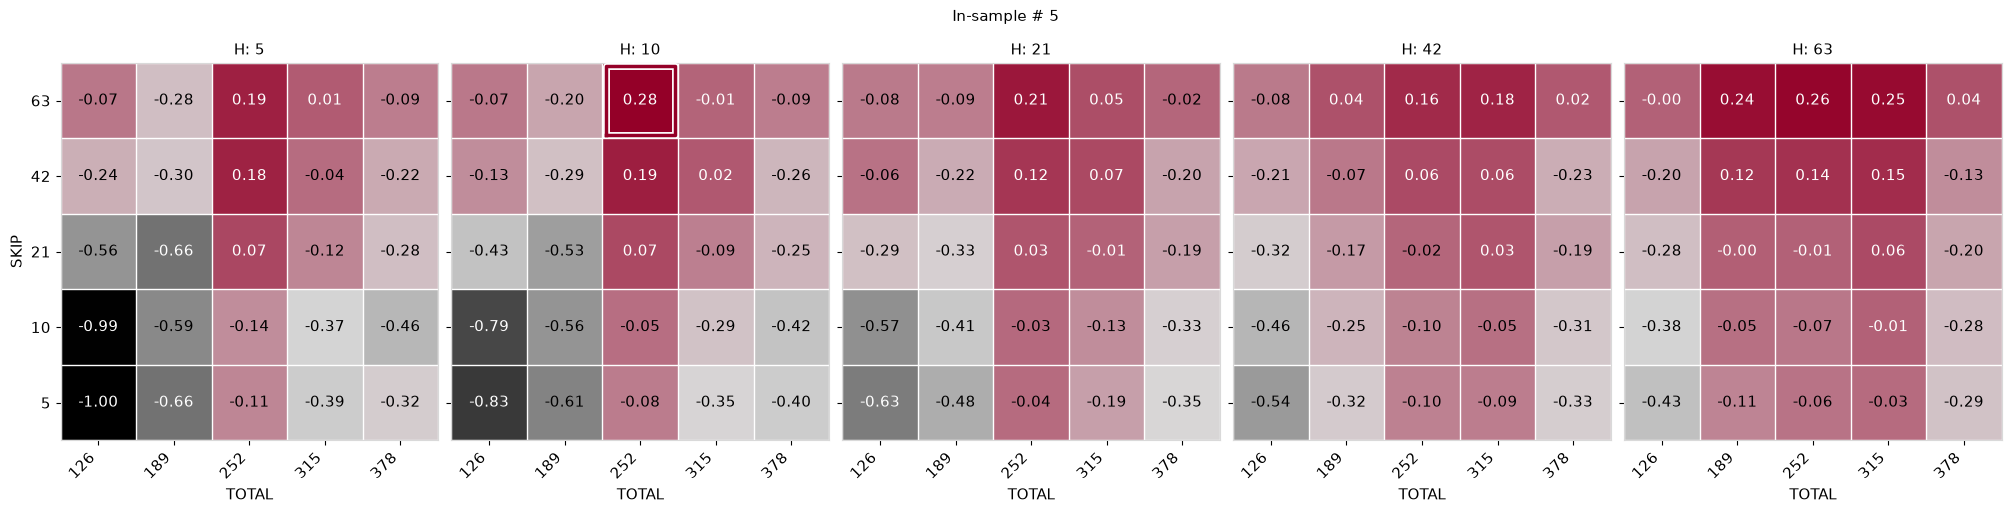

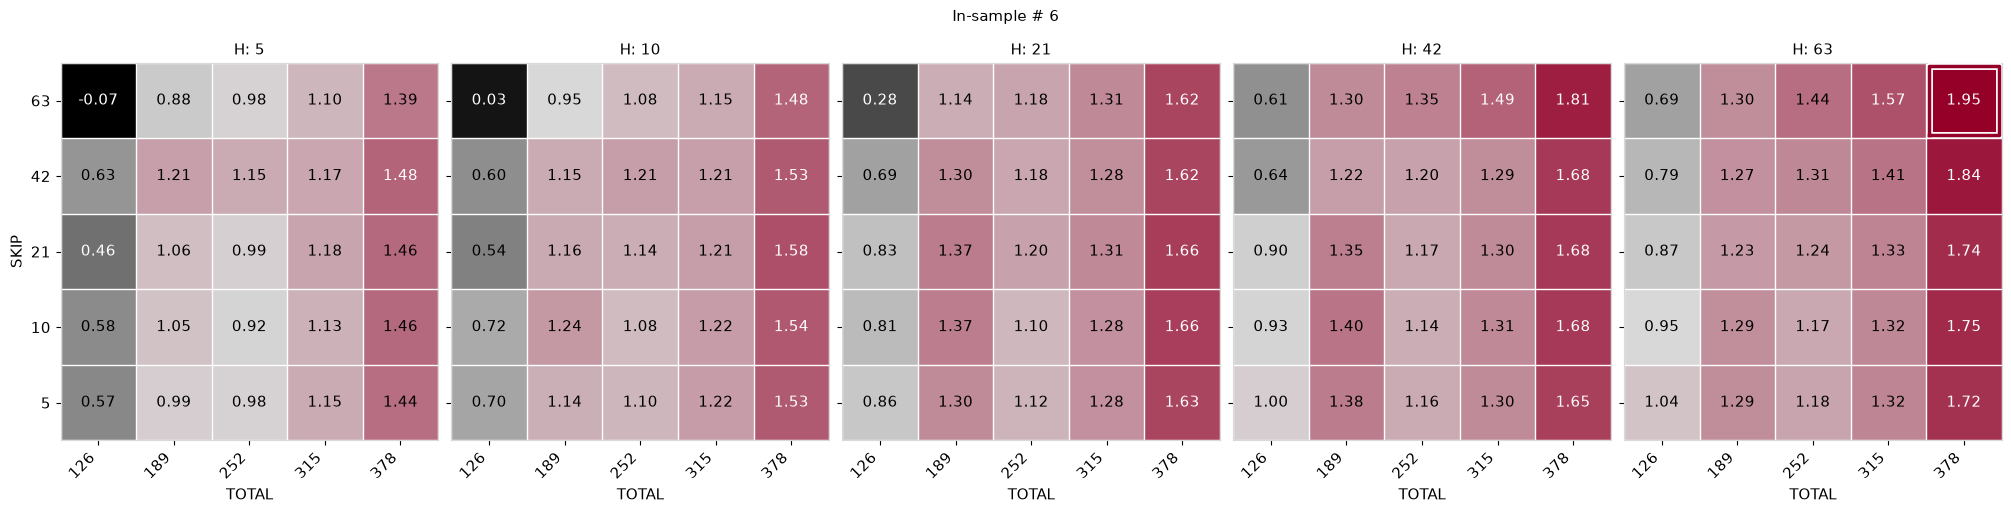

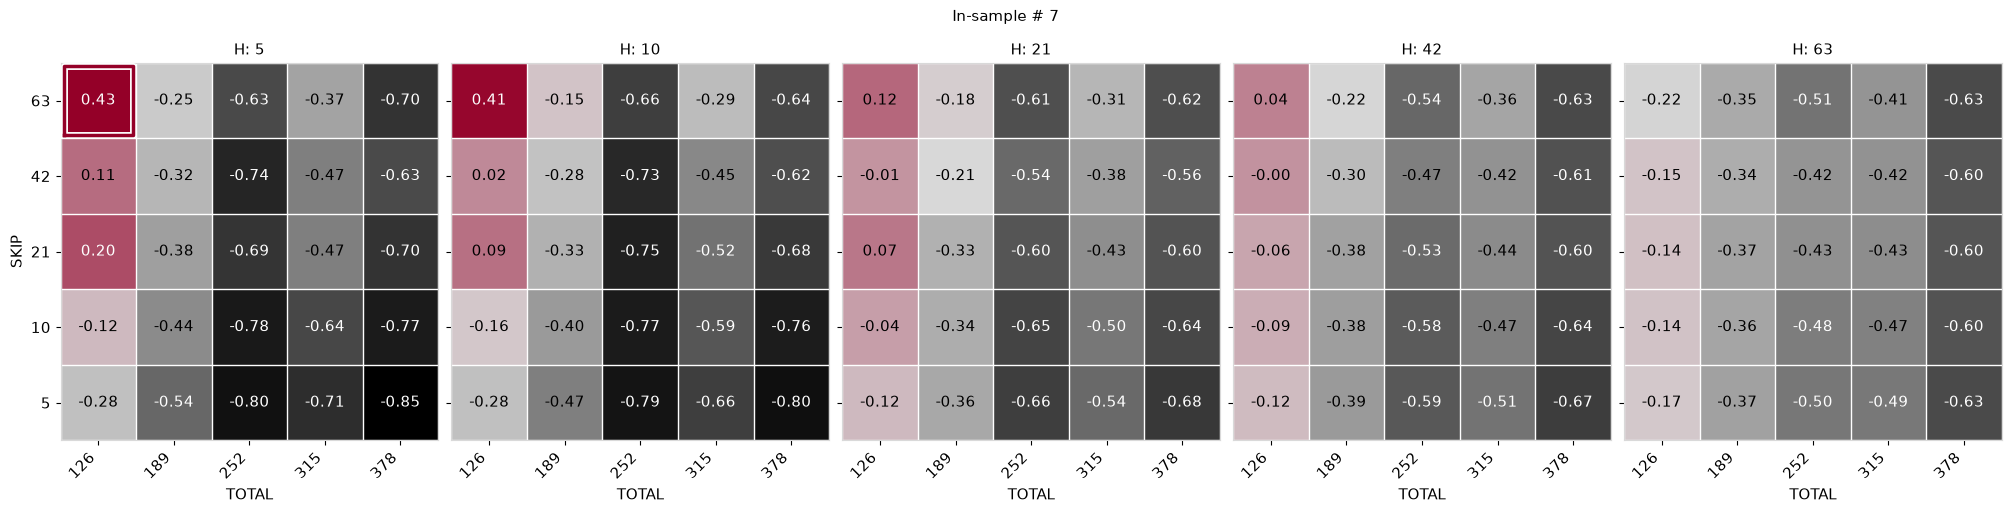

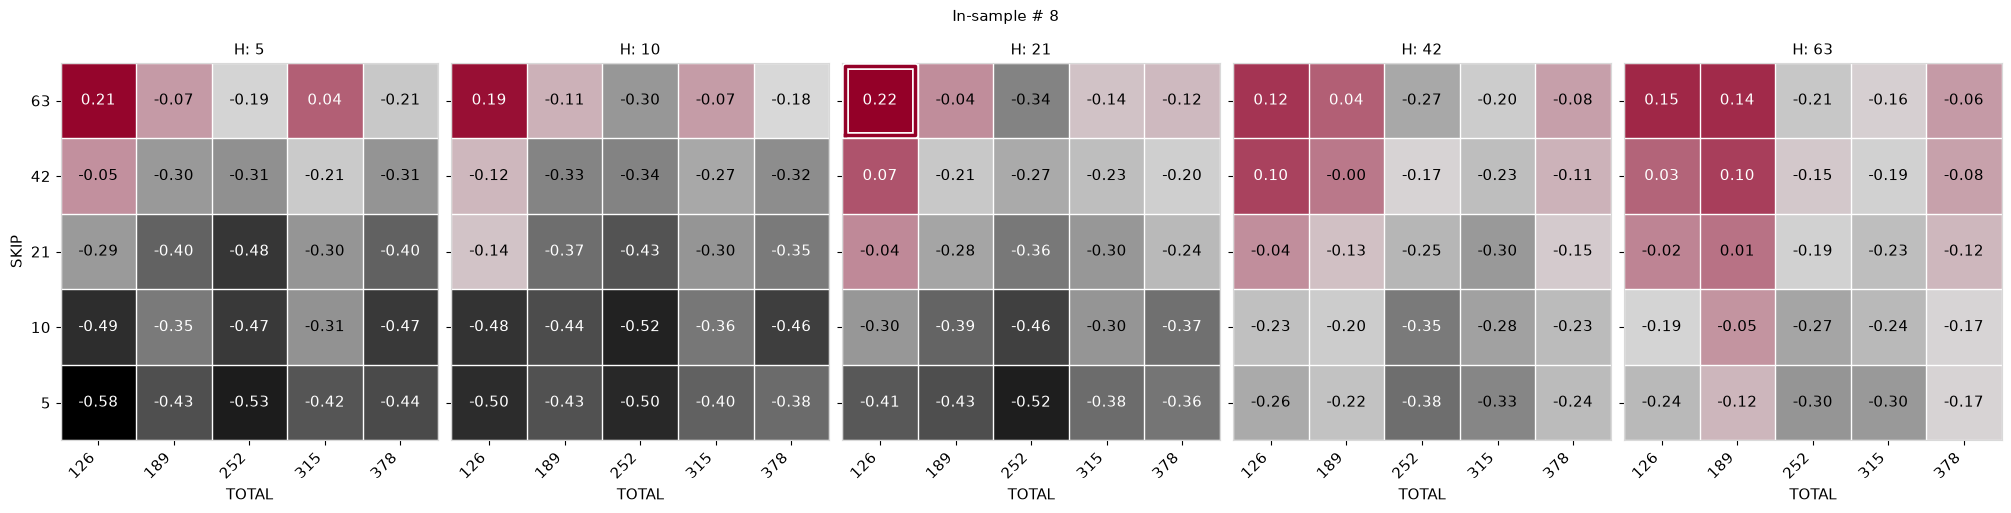

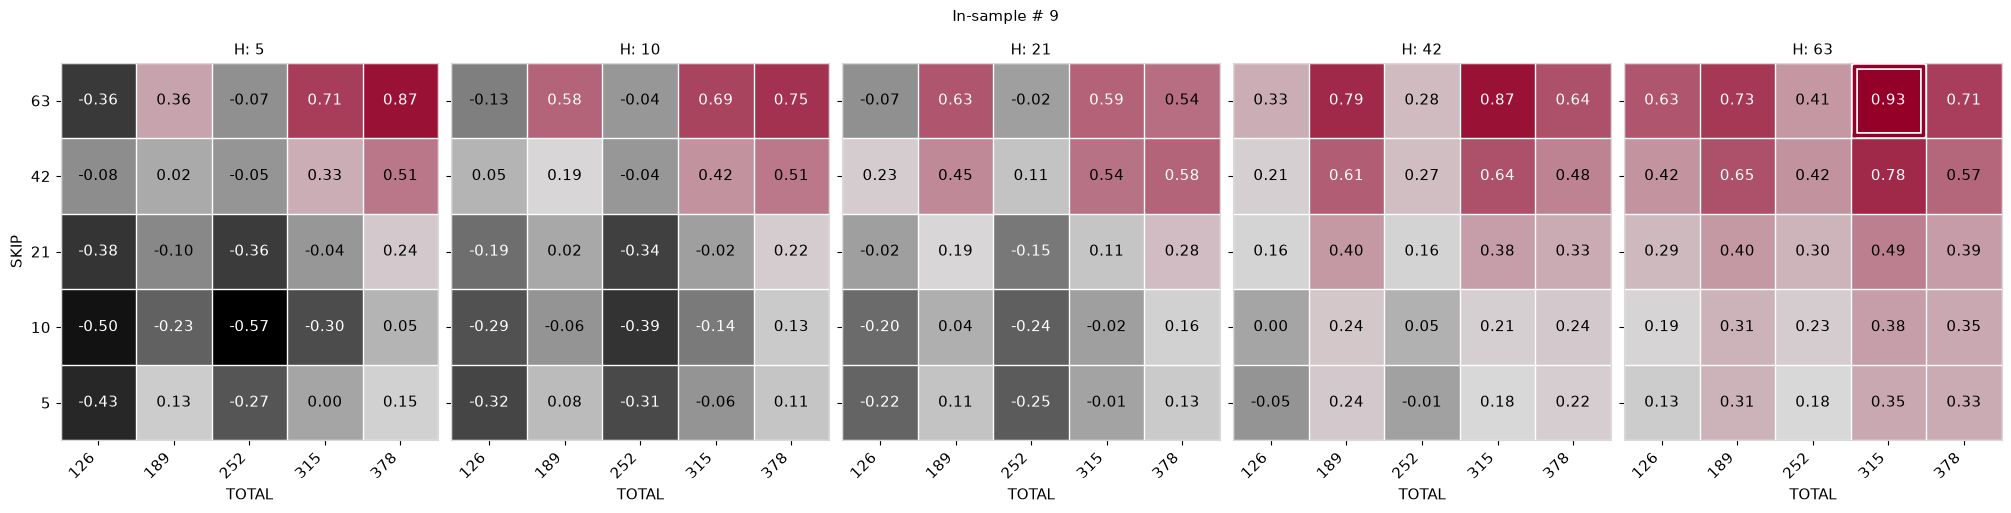

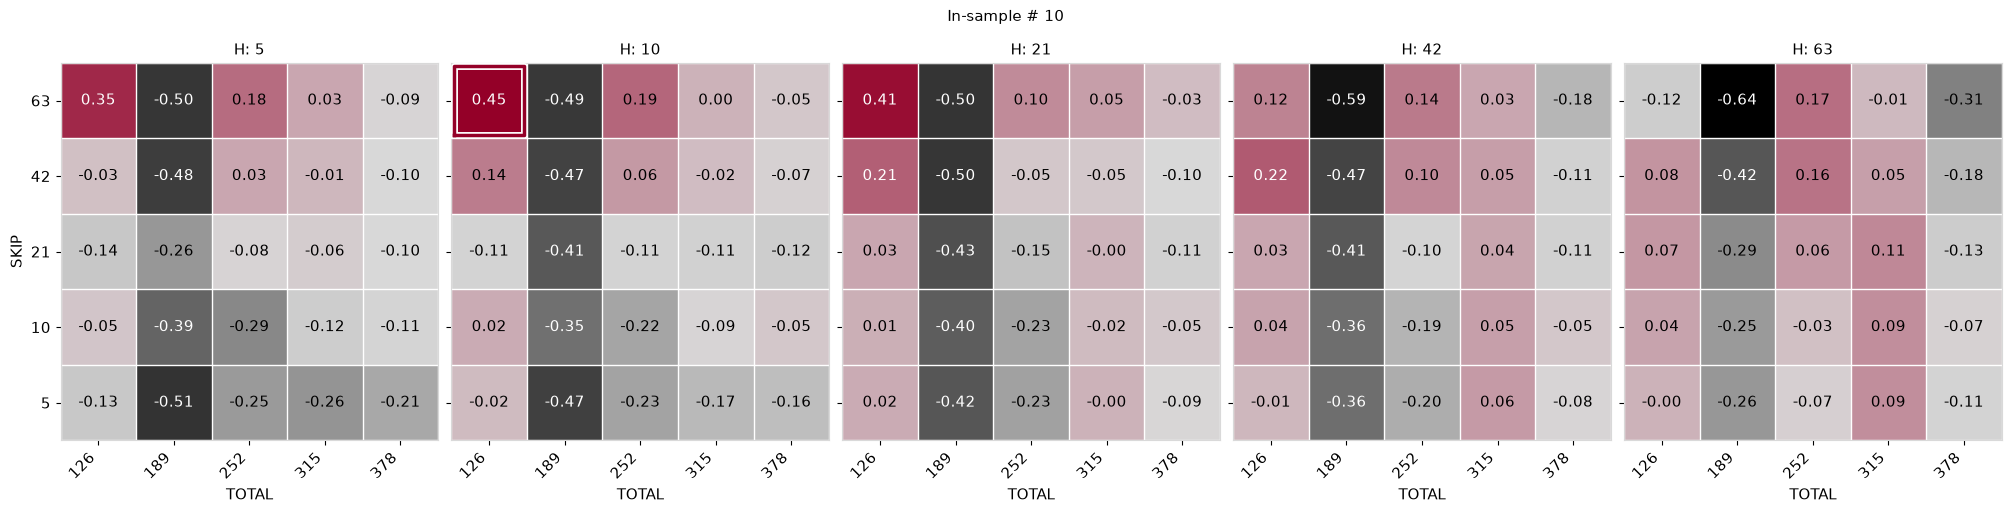

In [10]:
color_map = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "sharpe_paleta",
    [NEGRO, GRIS, PRINCIPAL],
)
color_map.set_bad(BLANCO)

for winner in wf_selections.itertuples(index=False):
    scores = wf_is_scores.loc[
        wf_is_scores["fold"] == winner.fold
    ]

    finite_scores = scores.loc[
        np.isfinite(scores["sharpe_is"]),
        "sharpe_is",
    ]

    color_min = float(finite_scores.min())
    color_max = float(finite_scores.max())

    if color_min == color_max:
        color_min -= 0.01
        color_max += 0.01

    fig, axes = plt.subplots(
        1,
        len(H_GRID),
        figsize=(20, 5),
        facecolor=BLANCO,
        constrained_layout=True,
        sharey=True,
    )

    for ax, h in zip(np.atleast_1d(axes), H_GRID):
        matrix = (
            scores.loc[scores["H"].eq(h)]
            .pivot(
                index="SKIP",
                columns="TOTAL",
                values="sharpe_is",
            )
            .reindex(index=SKIP_GRID, columns=TOTAL_GRID)
        )

        values = matrix.to_numpy(dtype=float)

        ax.imshow(
            np.ma.masked_invalid(values),
            cmap=color_map,
            vmin=color_min,
            vmax=color_max,
            origin="lower",
            aspect="equal",
            interpolation="nearest",
        )

        ax.set_facecolor(BLANCO)
        ax.set_title(f"H: {h}", color=NEGRO)
        ax.set_xlabel("TOTAL", color=NEGRO)

        ax.set_xticks(np.arange(len(TOTAL_GRID)))
        ax.set_xticklabels(TOTAL_GRID, rotation=45, ha="right")

        ax.set_yticks(np.arange(len(SKIP_GRID)))
        ax.set_yticklabels(SKIP_GRID)
        ax.tick_params(colors=NEGRO)

        ax.set_xticks(
            np.arange(len(TOTAL_GRID) + 1) - 0.5,
            minor=True,
        )
        ax.set_yticks(
            np.arange(len(SKIP_GRID) + 1) - 0.5,
            minor=True,
        )

        ax.grid(which="minor", color=BLANCO, linewidth=1)
        ax.tick_params(which="minor", bottom=False, left=False)

        for spine in ax.spines.values():
            spine.set_color(GRIS)

        # Valores con contraste adaptado al fondo.
        for y in range(len(SKIP_GRID)):
            for x in range(len(TOTAL_GRID)):
                value = values[y, x]

                if np.isfinite(value):
                    normalized = (
                        (value - color_min) / (color_max - color_min)
                    )
                    red, green, blue, _ = color_map(normalized)
                    brightness = (
                        0.299 * red + 0.587 * green + 0.114 * blue
                    )
                    text_color = NEGRO if brightness > 0.5 else BLANCO
                    label = f"{value:.2f}"
                else:
                    text_color = NEGRO
                    label = "—"

                ax.text(
                    x,
                    y,
                    label,
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=11,
                    zorder=6,
                )

        # Contorno de la combinación seleccionada.
        if h == int(winner.H):
            x = TOTAL_GRID.index(int(winner.TOTAL))
            y = SKIP_GRID.index(int(winner.SKIP))

            border_x = [
                x - 0.46, x + 0.46, x + 0.46,
                x - 0.46, x - 0.46,
            ]
            border_y = [
                y - 0.46, y - 0.46, y + 0.46,
                y + 0.46, y - 0.46,
            ]

            ax.plot(
                border_x,
                border_y,
                color=BLANCO,
                linewidth=5,
                zorder=4,
            )
            ax.plot(
                border_x,
                border_y,
                color=PRINCIPAL,
                linewidth=2.5,
                zorder=5,
            )

    np.atleast_1d(axes)[0].set_ylabel("SKIP", color=NEGRO)

    fig.suptitle(
        f"In-sample # {int(winner.fold)}",
        color=NEGRO,
    )

    fig.savefig(
        BATCH / "walk-forward-2y-2y"
        / f"in-sample-{int(winner.fold):02d}-heatmaps.png",
        dpi=300,
        facecolor=BLANCO,
    )

    plt.show()
    plt.close(fig)

In [11]:
display(
    wf_selections[[
        "fold",
        "TOTAL",
        "SKIP",
        "H",
        "sharpe_is",
        "mean_daily",
        "std_daily",
        "n_obs",
        "is_start",
        "is_end_exclusive",
        "oos_start",
        "oos_end_exclusive",
    ]].sort_values("fold").round({
        "sharpe_is": 4,
        "mean_daily": 6,
        "std_daily": 6,
    })
)

,fold,TOTAL,SKIP,H,sharpe_is,mean_daily,std_daily,n_obs,is_start,is_end_exclusive,oos_start,oos_end_exclusive
0,1,252,63,21,2.1076,0.000799,0.006020,504,2004-01-01,2006-01-01,2006-01-01,2008-01-01
1,2,126,63,21,1.6991,0.000641,0.005984,502,2006-01-01,2008-01-01,2008-01-01,2010-01-01
2,3,126,63,5,-0.0486,-0.000049,0.015971,505,2008-01-01,2010-01-01,2010-01-01,2012-01-01
3,4,378,42,63,0.8105,0.000244,0.004781,504,2010-01-01,2012-01-01,2012-01-01,2014-01-01
4,5,252,63,10,0.2844,0.000128,0.007168,502,2012-01-01,2014-01-01,2014-01-01,2016-01-01
5,6,378,63,63,1.9514,0.000916,0.007448,504,2014-01-01,2016-01-01,2016-01-01,2018-01-01
6,7,126,63,5,0.4265,0.000199,0.007396,503,2016-01-01,2018-01-01,2018-01-01,2020-01-01
7,8,126,63,21,0.2198,0.000094,0.006814,503,2018-01-01,2020-01-01,2020-01-01,2022-01-01
8,9,315,63,63,0.9285,0.000513,0.008768,505,2020-01-01,2022-01-01,2022-01-01,2024-01-01
9,10,126,63,10,0.4479,0.000236,0.008371,501,2022-01-01,2024-01-01,2024-01-01,2026-01-01


In [12]:
WF_FEES = BT_FEES

@njit
def wf_scale_nb(nav, reference_nav, target, current, marks, fees):
    if not np.isfinite(reference_nav) or reference_nav <= 0.0:
        raise ValueError("NAV de referencia inválido")
    if fees == 0.0:
        return nav / reference_nav
    gross_target = 0.0
    liquidation_fee = 0.0
    for col in range(len(target)):
        gross_target += abs(target[col]) * marks[col]
        liquidation_fee += fees * abs(current[col]) * marks[col]
    if reference_nav <= fees * gross_target:
        raise ValueError("Apalancamiento excesivo para la transición")
    if liquidation_fee >= nav:
        raise ValueError("Capital insuficiente para la transición")
    # escala * NAV_referencia + comisión_del_rebalanceo = NAV_actual
    lo = 0.0
    hi = nav / reference_nav
    for _ in range(60):
        scale = (lo + hi) / 2.0
        cost = 0.0
        for col in range(len(target)):
            cost += (
                fees
                * abs(scale * target[col] - current[col])
                * marks[col]
            )
        if scale * reference_nav + cost > nav:
            hi = scale
        else:
            lo = scale
    return lo

@njit
def wf_pre_segment_nb(
    c,
    weights,
    allowed,
    horizons,
    transition_at,
    targets,
    reference_navs,
    seed_expiries,
    expiries,
    planned,
    order_values,
    size_types,
    directions,
    pretrade_nav,
    scales,
    fees,
):
    for col in range(c.from_col, c.to_col):
        c.last_val_price[col] = c.close[c.i, col]
    nav = pnb.get_group_value_ctx_nb(c)
    if not np.isfinite(nav) or nav <= 0.0:
        raise ValueError("NAV pretrade no positivo o no finito")
    pretrade_nav[c.i] = nav
    ring = expiries.shape[0]
    transition = transition_at[c.i]
    if transition >= 0:
        scale = wf_scale_nb(
            nav,
            reference_navs[transition],
            targets[transition],
            c.last_position,
            c.close[c.i],
            fees,
        )
        scales[transition] = scale
        # Reemplazar los vencimientos anteriores.
        for slot in range(ring):
            for col in range(c.from_col, c.to_col):
                expiries[slot, col] = (
                    seed_expiries[transition, slot, col] * scale
                )
        # El objetivo ya incluye la operación de este open.
        for col in range(c.from_col, c.to_col):
            size = (
                scale * targets[transition, col]
                - c.last_position[col]
            )
            planned[col] = (
                0.0 if is_close_nb(size, 0.0) else size
            )
    else:
        slot = c.i % ring
        next_slot = (c.i + horizons[c.i]) % ring
        for col in range(c.from_col, c.to_col):
            exit_units = -expiries[slot, col]
            expiries[slot, col] = 0.0
            entry_units = 0.0
            if allowed[c.i, col]:
                entry_units = (
                    weights[c.i, col]
                    * nav
                    / c.close[c.i, col]
                )
                if is_close_nb(entry_units, 0.0):
                    entry_units = 0.0
            expiries[next_slot, col] += entry_units
            size = exit_units + entry_units
            planned[col] = (
                0.0 if is_close_nb(size, 0.0) else size
            )
    pnb.sort_call_seq_nb(
        c,
        planned,
        size_types,
        directions,
        order_values,
        ctx_select=False,
    )
    return (planned,)

@njit
def wf_order_nb(c, planned, fees):
    size = planned[c.col]
    if size == 0.0:
        return pnb.order_nothing_nb()
    return pnb.order_nb(
        size=size,
        price=c.close[c.i, c.col],
        size_type=SizeType.Amount,
        direction=Direction.Both,
        fees=fees,
        fixed_fees=0.0,
        slippage=0.0,
        lock_cash=False,
        allow_partial=False,
        raise_reject=True,
        reject_prob=0.0,
        min_size=0.0,
        max_size=np.inf,
        size_granularity=np.nan,
    )

wf_marks = pd.read_parquet(
    BATCH / "common" / "marks.parquet"
)
wf_allowed_frame = pd.read_parquet(
    BATCH / "common" / "allowed.parquet"
)
wf_membership = pd.read_parquet(
    BATCH / "common" / "membership.parquet"
)
wf_full_calendar = wf_marks.index
wf_rics = wf_marks.columns
for frame in (wf_allowed_frame, wf_membership):
    if (
        not frame.index.equals(wf_full_calendar)
        or not frame.columns.equals(wf_rics)
    ):
        raise ValueError("Datos comunes no alineados")
wf_selected = (
    wf_selections.copy()
    .sort_values("oos_start")
    .reset_index(drop=True)
)
for column in ("TOTAL", "SKIP", "H"):
    wf_selected[column] = wf_selected[column].astype(int)
# El inicio depende del primer bloque seleccionado.
# El límite de evaluación sigue siendo fin de 2025.
wf_oos_start = pd.Timestamp(wf_selected["oos_start"].min())
wf_oos_end = min(
    pd.Timestamp(wf_selected["oos_end_exclusive"].max()),
    pd.Timestamp("2026-01-01"),
)
wf_oos_rows = np.flatnonzero(
    (wf_full_calendar >= wf_oos_start)
    & (wf_full_calendar < wf_oos_end)
)
wf_oos_calendar = wf_full_calendar.take(wf_oos_rows)
wf_close = wf_marks.iloc[wf_oos_rows]
wf_allowed = (
    wf_allowed_frame.iloc[wf_oos_rows]
    .to_numpy(dtype=bool)
)
for column in ("TOTAL", "SKIP", "H"):
    wf_selected[column] = wf_selected[column].astype(int)
wf_owner = np.full(
    len(wf_oos_calendar),
    -1,
    dtype=np.int64,
)
wf_boundary_rows = []
for j, winner in enumerate(wf_selected.itertuples(index=False)):
    rows = np.flatnonzero(
        (wf_oos_calendar >= winner.oos_start)
        & (wf_oos_calendar < winner.oos_end_exclusive)
    )
    if len(rows) == 0 or (wf_owner[rows] >= 0).any():
        raise ValueError("Bloque OOS vacío o solapado")
    wf_owner[rows] = j
    wf_boundary_rows.append(int(rows[0]))
if (wf_owner < 0).any():
    raise ValueError("Hay sesiones OOS sin configuración")
wf_boundary_rows = np.asarray(
    wf_boundary_rows,
    dtype=np.int64,
)
wf_applied = wf_selected.iloc[wf_owner][[
    "fold", "run_id", "TOTAL", "SKIP", "H",
]].copy()
wf_applied.index = wf_oos_calendar
wf_applied = wf_applied.rename_axis("date")
wf_horizons = wf_applied["H"].to_numpy(dtype=np.int64)
# Solo la adopción inicial y los cambios de configuración.
wf_transition_folds = np.flatnonzero(
    wf_selected["run_id"]
    .ne(wf_selected["run_id"].shift())
    .to_numpy()
)
wf_transition_rows = wf_boundary_rows[wf_transition_folds]
wf_transition_at = np.full(
    len(wf_oos_calendar),
    -1,
    dtype=np.int64,
)
wf_transition_at[wf_transition_rows] = np.arange(
    len(wf_transition_rows)
)
wf_ring = int(wf_horizons.max()) + 1
wf_weights = np.zeros(wf_close.shape, dtype=np.float64)
wf_targets = np.zeros((
    len(wf_transition_rows),
    len(wf_rics),
))
wf_reference_navs = np.zeros(len(wf_transition_rows))
wf_seed_expiries = np.zeros((
    len(wf_transition_rows),
    wf_ring,
    len(wf_rics),
))
for (total, skip), chosen in (
    wf_selected.drop_duplicates("run_id")
    .groupby(["TOTAL", "SKIP"], sort=False)
):
    signals = pd.read_parquet(
        BATCH / "signals"
        / f"T{int(total):03d}-S{int(skip):02d}.parquet"
    )
    for winner in chosen.itertuples(index=False):
        # Preparar sobre el calendario completo evita censurar
        # entradas por cortar la evaluación en diciembre de 2025.
        weights, _ = bt_prepare_weights(
            wf_full_calendar,
            wf_membership,
            signals,
            h=int(winner.H),
        )
        selected = (
            wf_applied["run_id"]
            .eq(winner.run_id)
            .to_numpy()
        )
        wf_weights[selected] = weights.iloc[
            wf_oos_rows[selected]
        ].to_numpy()
    del signals, weights
for run_id in wf_selected["run_id"].unique():
    folder = BATCH / "runs" / run_id
    reference_daily = pd.read_parquet(
        folder / "daily.parquet",
        columns=["nav"],
    )
    reference_orders = pd.read_parquet(
        folder / "orders.parquet",
        columns=["date", "RIC", "signed_units"],
    )
    reference_cohorts = pd.read_parquet(
        folder / "cohorts.parquet",
        columns=["RIC", "entry_date", "expiry_date", "units"],
    )
    for k in range(len(wf_transition_rows)):
        winner = wf_selected.iloc[wf_transition_folds[k]]
        if winner.run_id != run_id:
            continue
        day = int(wf_transition_rows[k])
        date = wf_oos_calendar[day]
        # NAV AFTER_OPEN: contempla también los fees históricos
        # si el lote de referencia fue ejecutado con costos.
        wf_reference_navs[k] = float(
            reference_daily.loc[date, "nav"]
        )
        wf_targets[k] = (
            reference_orders.loc[
                reference_orders["date"].le(date)
            ]
            .groupby("RIC")["signed_units"]
            .sum()
            .reindex(wf_rics, fill_value=0.0)
            .to_numpy()
        )
        active = reference_cohorts.loc[
            reference_cohorts["entry_date"].le(date)
            & reference_cohorts["expiry_date"].gt(date)
        ]
        cols = wf_rics.get_indexer(active["RIC"])
        remaining = (
            wf_full_calendar.get_indexer(active["expiry_date"])
            - wf_oos_rows[day]
        )
        if (
            (cols < 0).any()
            or (remaining < 1).any()
            or (remaining > int(winner.H)).any()
        ):
            raise ValueError("Cohortes heredadas no alineadas")
        np.add.at(
            wf_seed_expiries[k],
            ((day + remaining) % wf_ring, cols),
            active["units"].to_numpy(),
        )
    del reference_daily, reference_orders, reference_cohorts
wf_pretrade_nav = np.full(len(wf_oos_calendar), np.nan)
wf_scales = np.full(len(wf_transition_rows), np.nan)
wf_pf = vbt.Portfolio.from_order_func(
    wf_close,
    wf_order_nb,
    WF_FEES,
    pre_segment_func_nb=wf_pre_segment_nb,
    pre_segment_args=(
        wf_weights,
        wf_allowed,
        wf_horizons,
        wf_transition_at,
        wf_targets,
        wf_reference_navs,
        wf_seed_expiries,
        np.zeros((wf_ring, len(wf_rics))),
        np.zeros(len(wf_rics)),
        np.zeros(len(wf_rics)),
        np.full(
            len(wf_rics),
            SizeType.Amount,
            dtype=np.int64,
        ),
        np.full(
            len(wf_rics),
            Direction.Both,
            dtype=np.int64,
        ),
        wf_pretrade_nav,
        wf_scales,
        WF_FEES,
    ),
    post_order_func_nb=bt_post_order_nb,
    row_wise=True,
    cash_sharing=True,
    group_by=True,
    engine="rust",
    update_value=False,
    init_cash=BT_INITIAL_NAV,
    call_seq="default",
    freq="1D",
    ffill_val_price=True,
)
wf_daily = pd.DataFrame({
    "nav": bt_single_group(wf_pf.value(), wf_oos_calendar),
    "cash": bt_single_group(wf_pf.cash(), wf_oos_calendar),
    "return_net": bt_single_group(wf_pf.returns(), wf_oos_calendar),
    "pretrade_nav": wf_pretrade_nav,
    "transition": wf_transition_at >= 0,
}, index=wf_oos_calendar).rename_axis("date")
for column in ("fold", "run_id", "TOTAL", "SKIP", "H"):
    wf_daily[column] = wf_applied[column].to_numpy()
wf_orders = pd.DataFrame.from_records(
    wf_pf.order_records.copy()
)
wf_orders["date"] = wf_oos_calendar.take(
    wf_orders["idx"].to_numpy(dtype=int)
)
wf_orders["RIC"] = wf_rics.take(
    wf_orders["col"].to_numpy(dtype=int)
)
wf_orders["signed_units"] = np.where(
    wf_orders["side"].eq(OrderSide.Buy),
    wf_orders["size"],
    -wf_orders["size"],
)
wf_transitions = wf_selected.iloc[wf_transition_folds][[
    "fold", "run_id", "TOTAL", "SKIP", "H",
]].reset_index(drop=True)
wf_transitions["date"] = wf_oos_calendar.take(
    wf_transition_rows
)
wf_transitions["reference_nav_after_open"] = wf_reference_navs
wf_transitions["scale"] = wf_scales
wf_transitions["selector_pretrade_nav"] = wf_pretrade_nav[
    wf_transition_rows
]
wf_transitions["selector_nav_after_open"] = (
    wf_daily["nav"].iloc[wf_transition_rows].to_numpy()
)
wf_transitions["fees_paid"] = (
    wf_transitions["date"]
    .map(wf_orders.groupby("date")["fees"].sum())
    .fillna(0.0)
)
# No sobrescribir la matriz wf_returns del análisis IS.
wf_oos_returns = wf_daily["return_net"].to_numpy()
wf_wealth = np.r_[
    1.0,
    wf_daily["nav"].to_numpy() / BT_INITIAL_NAV,
]
wf_std = float(wf_oos_returns.std(ddof=1))
wf_metrics = pd.DataFrame([{
    "start": wf_oos_calendar[0],
    "end": wf_oos_calendar[-1],
    "observations": len(wf_oos_calendar),
    "fees": WF_FEES,
    "total_paid_fees": float(wf_orders["fees"].sum()),
    "configuration_changes": len(wf_transitions) - 1,
    "total_return": wf_wealth[-1] - 1,
    "annual_return": (
        wf_wealth[-1] ** (252 / len(wf_oos_calendar)) - 1
    ),
    "annual_volatility": wf_std * np.sqrt(252),
    "sharpe_zero_rf": (
        wf_oos_returns.mean() / wf_std * np.sqrt(252)
        if wf_std > 0 else np.nan
    ),
    "max_drawdown": np.min(
        wf_wealth / np.maximum.accumulate(wf_wealth) - 1
    ),
}])
display(wf_metrics)
display(wf_transitions)

,start,end,observations,fees,total_paid_fees,configuration_changes,total_return,annual_return,annual_volatility,sharpe_zero_rf,max_drawdown
0,2006-01-03,2025-12-31,5031,0.000605,0.313568,9,-0.199438,-0.01108,0.144325,-0.004884,-0.459215


,fold,run_id,TOTAL,SKIP,H,date,reference_nav_after_open,scale,selector_pretrade_nav,selector_nav_after_open,fees_paid
0,1,T252-S63-H21,252,63,21,2006-01-03,1.414020,0.706347,1.000000,0.998789,0.001211
1,2,T126-S63-H21,126,63,21,2008-01-02,1.762621,0.597733,1.054651,1.053576,0.001075
2,3,T126-S63-H05,126,63,5,2010-01-04,1.530758,0.573903,0.879204,0.878507,0.000697
3,4,T378-S42-H63,378,42,63,2012-01-03,0.765635,1.041070,0.798288,0.797080,0.001208
4,5,T252-S63-H10,252,63,10,2014-01-02,0.881326,0.878239,0.774891,0.774015,0.000876
5,6,T378-S63-H63,378,63,63,2016-01-04,1.080715,0.929912,1.006229,1.004970,0.001259
6,7,T126-S63-H05,126,63,5,2018-01-02,1.472463,0.535879,0.790679,0.789062,0.001617
7,8,T126-S63-H21,126,63,21,2020-01-02,1.396142,0.583586,0.815320,0.814769,0.000551
8,9,T315-S63-H63,315,63,63,2022-01-03,0.794530,0.989801,0.787622,0.786427,0.001195
9,10,T126-S63-H10,126,63,10,2024-01-02,1.653945,0.462779,0.766962,0.765411,0.001551


In [13]:
wf_results[SIGNAL_KIND] = {
    "batch": BATCH,
    "fees": WF_FEES,
    "folds": wf_folds.copy(deep=True),
    "is_scores": wf_is_scores.copy(deep=True),
    "selections": wf_selections.copy(deep=True),
    "daily": wf_daily.copy(deep=True),
    "orders": wf_orders.copy(deep=True),
    "transitions": wf_transitions.copy(deep=True),
    "metrics": wf_metrics.copy(deep=True),
}

wf_folder = BATCH / "walk-forward-2y-2y"

wf_daily.to_parquet(
    wf_folder / "oos_daily.parquet"
)
wf_orders.to_parquet(
    wf_folder / "oos_orders.parquet",
    index=False,
)
wf_transitions.to_parquet(
    wf_folder / "oos_transitions.parquet",
    index=False,
)
wf_metrics.to_parquet(
    wf_folder / "oos_metrics.parquet",
    index=False,
)

In [14]:
SIGNAL_KIND = "classic"
BATCH = BATCHES[SIGNAL_KIND]

# Ejecucion completa del lote de momentum clasico
metrics_common = run_batch()
batch_metrics[SIGNAL_KIND] = metrics_common.copy(deep=True)

display(
    metrics_common.sort_values(["total", "skip", "h"])
)

[1/125] T126-S05-H05
[2/125] T126-S05-H10
[3/125] T126-S05-H21
[4/125] T126-S05-H42
[5/125] T126-S05-H63
[6/125] T126-S10-H05
[7/125] T126-S10-H10
[8/125] T126-S10-H21
[9/125] T126-S10-H42
[10/125] T126-S10-H63
[11/125] T126-S21-H05
[12/125] T126-S21-H10
[13/125] T126-S21-H21
[14/125] T126-S21-H42
[15/125] T126-S21-H63
[16/125] T126-S42-H05
[17/125] T126-S42-H10
[18/125] T126-S42-H21
[19/125] T126-S42-H42
[20/125] T126-S42-H63
[21/125] T126-S63-H05
[22/125] T126-S63-H10
[23/125] T126-S63-H21
[24/125] T126-S63-H42
[25/125] T126-S63-H63
[26/125] T189-S05-H05
[27/125] T189-S05-H10
[28/125] T189-S05-H21
[29/125] T189-S05-H42
[30/125] T189-S05-H63
[31/125] T189-S10-H05
[32/125] T189-S10-H10
[33/125] T189-S10-H21
[34/125] T189-S10-H42
[35/125] T189-S10-H63
[36/125] T189-S21-H05
[37/125] T189-S21-H10
[38/125] T189-S21-H21
[39/125] T189-S21-H42
[40/125] T189-S21-H63
[41/125] T189-S42-H05
[42/125] T189-S42-H10
[43/125] T189-S42-H21
[44/125] T189-S42-H42
[45/125] T189-S42-H63
[46/125] T189-S63-H

,run_id,total,skip,h,start,end,observations,total_return,annual_return,annual_volatility,sharpe_zero_rf,max_drawdown,min_active_cohort_slots,days_with_fewer_than_h
0,T126-S05-H05,126,5,5,2001-10-09,2026-03-30,6157,-0.806254,-0.064967,0.269098,-0.112849,-0.905968,5,0
1,T126-S05-H10,126,5,10,2001-10-09,2026-03-30,6157,-0.724799,-0.051439,0.272924,-0.054930,-0.875359,10,0
2,T126-S05-H21,126,5,21,2001-10-09,2026-03-30,6157,-0.731900,-0.052453,0.277829,-0.053380,-0.872567,21,0
3,T126-S05-H42,126,5,42,2001-10-09,2026-03-30,6157,-0.720475,-0.050833,0.311608,-0.010882,-0.898975,42,0
4,T126-S05-H63,126,5,63,2001-10-09,2026-03-30,6157,-0.477996,-0.026256,0.306679,0.064874,-0.836226,63,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,T378-S63-H05,378,63,5,2001-10-09,2026-03-30,6157,-0.656847,-0.042832,0.255261,-0.042195,-0.867881,5,0
121,T378-S63-H10,378,63,10,2001-10-09,2026-03-30,6157,-0.548181,-0.031994,0.256983,0.003548,-0.833544,10,0
122,T378-S63-H21,378,63,21,2001-10-09,2026-03-30,6157,-0.598281,-0.036639,0.257279,-0.015037,-0.859348,21,0
123,T378-S63-H42,378,63,42,2001-10-09,2026-03-30,6157,-0.687815,-0.046531,0.263934,-0.047739,-0.888454,42,0


In [15]:
# Walkforward
wf_grid = pd.DataFrame([
    {
        "run_id": f"T{total:03d}-S{skip:02d}-H{h:02d}",
        "TOTAL": total,
        "SKIP": skip,
        "H": h,
    }
    for total in TOTAL_GRID
    for skip in SKIP_GRID
    for h in H_GRID
])
index = pd.read_parquet(
    BATCH / "common" / "marks.parquet",
    columns=[],
).index
wf_calendar = index[
    (index >= "2004-01-01")
    & (index < "2026-01-01")
]
wf_returns = np.empty(
    (len(wf_grid), len(wf_calendar)),
    dtype=float,
)
for j, run_id in enumerate(wf_grid["run_id"]):
    daily = pd.read_parquet(
        BATCH / "runs" / run_id / "daily.parquet",
        columns=["return_net"],
    )
    daily = daily.loc[
        (daily.index >= "2004-01-01")
        & (daily.index < "2026-01-01")
    ]
    if not daily.index.equals(wf_calendar):
        raise ValueError(f"Calendario distinto en {run_id}")
    values = daily["return_net"].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f"Retornos no finitos en {run_id}")
    wf_returns[j] = values
fold_rows = []
for number, year in enumerate(range(2004, 2024, 2), start=1):
    is_start = pd.Timestamp(f"{year}-01-01")
    oos_start = pd.Timestamp(f"{year + 2}-01-01")
    oos_end = pd.Timestamp(f"{year + 4}-01-01")
    is_dates = wf_calendar[
        (wf_calendar >= is_start)
        & (wf_calendar < oos_start)
    ]
    oos_dates = wf_calendar[
        (wf_calendar >= oos_start)
        & (wf_calendar < oos_end)
    ]
    if len(is_dates) < 2 or len(oos_dates) == 0:
        raise ValueError(f"Calendario insuficiente en fold {number}")
    fold_rows.append({
        "fold": number,
        "is_start": is_start,
        "is_end_exclusive": oos_start,
        "oos_start": oos_start,
        "oos_end_exclusive": oos_end,
        "is_first_date": is_dates[0],
        "is_last_date": is_dates[-1],
        "oos_first_date": oos_dates[0],
        "oos_last_date": oos_dates[-1],
        "n_is": len(is_dates),
        "n_oos": len(oos_dates),
    })
wf_folds = pd.DataFrame(fold_rows)
display(wf_folds)

,fold,is_start,is_end_exclusive,oos_start,oos_end_exclusive,is_first_date,is_last_date,oos_first_date,oos_last_date,n_is,n_oos
0,1,2004-01-01,2006-01-01,2006-01-01,2008-01-01,2004-01-02,2005-12-30,2006-01-03,2007-12-31,504,502
1,2,2006-01-01,2008-01-01,2008-01-01,2010-01-01,2006-01-03,2007-12-31,2008-01-02,2009-12-31,502,505
2,3,2008-01-01,2010-01-01,2010-01-01,2012-01-01,2008-01-02,2009-12-31,2010-01-04,2011-12-30,505,504
3,4,2010-01-01,2012-01-01,2012-01-01,2014-01-01,2010-01-04,2011-12-30,2012-01-03,2013-12-31,504,502
4,5,2012-01-01,2014-01-01,2014-01-01,2016-01-01,2012-01-03,2013-12-31,2014-01-02,2015-12-31,502,504
5,6,2014-01-01,2016-01-01,2016-01-01,2018-01-01,2014-01-02,2015-12-31,2016-01-04,2017-12-29,504,503
6,7,2016-01-01,2018-01-01,2018-01-01,2020-01-01,2016-01-04,2017-12-29,2018-01-02,2019-12-31,503,503
7,8,2018-01-01,2020-01-01,2020-01-01,2022-01-01,2018-01-02,2019-12-31,2020-01-02,2021-12-31,503,505
8,9,2020-01-01,2022-01-01,2022-01-01,2024-01-01,2020-01-02,2021-12-31,2022-01-03,2023-12-29,505,501
9,10,2022-01-01,2024-01-01,2024-01-01,2026-01-01,2022-01-03,2023-12-29,2024-01-02,2025-12-31,501,502


In [16]:
score_tables = []
winner_rows = []
for fold in wf_folds.itertuples(index=False):
    mask = (
        (wf_calendar >= fold.is_start)
        & (wf_calendar < fold.is_end_exclusive)
    )
    sample = wf_returns[:, mask]
    mean_daily = sample.mean(axis=1)
    std_daily = sample.std(axis=1, ddof=1)
    std_daily[np.ptp(sample, axis=1) == 0] = 0.0
    valid = (
        np.isfinite(mean_daily)
        & np.isfinite(std_daily)
        & (std_daily > 0)
    )
    sharpe = np.full(len(wf_grid), np.nan)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        sharpe[valid] = (
            mean_daily[valid]
            / std_daily[valid]
            * np.sqrt(252)
        )
    sharpe[~np.isfinite(sharpe)] = np.nan
    scores = wf_grid.copy()
    scores.insert(0, "fold", fold.fold)
    scores["n_obs"] = sample.shape[1]
    scores["mean_daily"] = mean_daily
    scores["std_daily"] = std_daily
    scores["sharpe_is"] = sharpe
    candidates = scores.loc[
        np.isfinite(scores["sharpe_is"])
    ]
    if candidates.empty:
        raise ValueError(
            f"Fold {fold.fold}: ningún candidato tiene Sharpe IS finito"
        )
    winner = candidates.sort_values(
        ["sharpe_is", "TOTAL", "SKIP", "H"],
        ascending=[False, True, True, True],
        kind="stable",
    ).iloc[0]
    score_tables.append(scores)
    winner_rows.append(winner.to_dict())
wf_is_scores = pd.concat(
    score_tables,
    ignore_index=True,
)
wf_selections = (
    pd.DataFrame(winner_rows)
    .merge(
        wf_folds,
        on="fold",
        validate="one_to_one",
    )
    .sort_values("fold")
    .reset_index(drop=True)
)
(BATCH / "walk-forward-2y-2y").mkdir(exist_ok=True)
wf_folds.to_parquet(
    BATCH / "walk-forward-2y-2y" / "folds.parquet",
    index=False,
)
wf_is_scores.to_parquet(
    BATCH / "walk-forward-2y-2y" / "is_scores.parquet",
    index=False,
)
wf_selections.to_parquet(
    BATCH / "walk-forward-2y-2y" / "selections.parquet",
    index=False,
)
display(
    wf_selections[[
        "fold",
        "run_id",
        "sharpe_is",
        "is_start",
        "is_end_exclusive",
        "oos_start",
        "oos_end_exclusive",
    ]]
)

,fold,run_id,sharpe_is,is_start,is_end_exclusive,oos_start,oos_end_exclusive
0,1,T126-S42-H63,1.332333,2004-01-01,2006-01-01,2006-01-01,2008-01-01
1,2,T189-S05-H21,1.472381,2006-01-01,2008-01-01,2008-01-01,2010-01-01
2,3,T378-S05-H63,-0.218581,2008-01-01,2010-01-01,2010-01-01,2012-01-01
3,4,T378-S63-H63,0.583670,2010-01-01,2012-01-01,2012-01-01,2014-01-01
4,5,T252-S42-H05,0.542791,2012-01-01,2014-01-01,2014-01-01,2016-01-01
5,6,T378-S63-H63,1.320135,2014-01-01,2016-01-01,2016-01-01,2018-01-01
6,7,T126-S21-H05,-0.023957,2016-01-01,2018-01-01,2018-01-01,2020-01-01
7,8,T189-S63-H63,0.508111,2018-01-01,2020-01-01,2020-01-01,2022-01-01
8,9,T126-S63-H42,0.322826,2020-01-01,2022-01-01,2022-01-01,2024-01-01
9,10,T126-S63-H10,0.460921,2022-01-01,2024-01-01,2024-01-01,2026-01-01


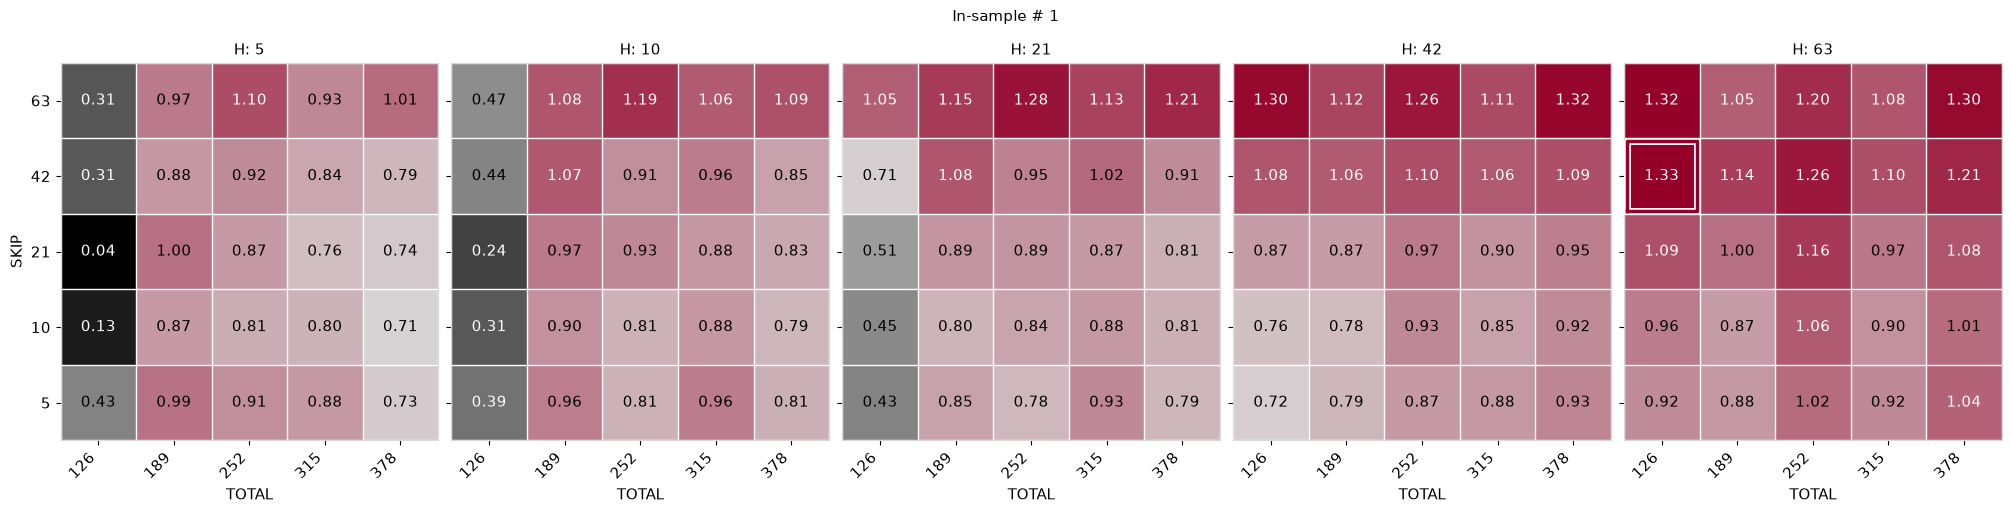

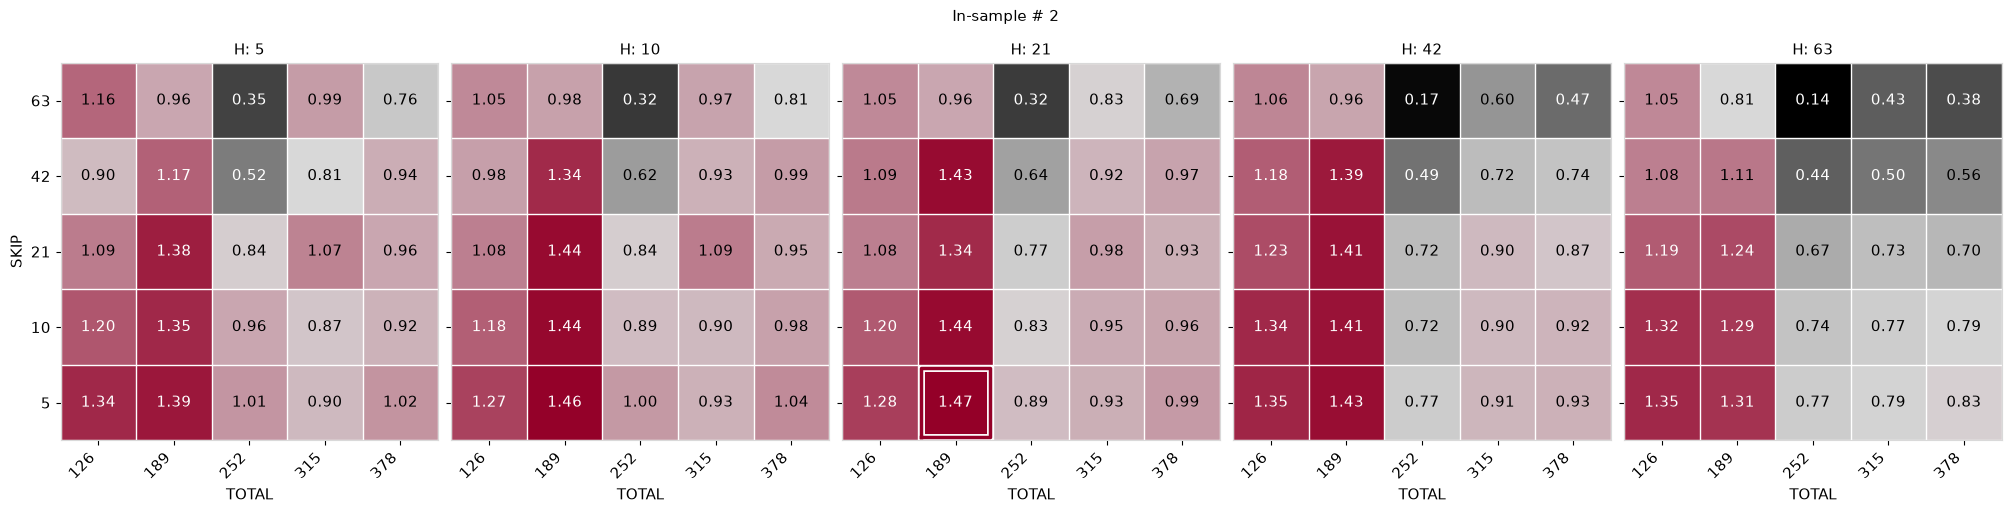

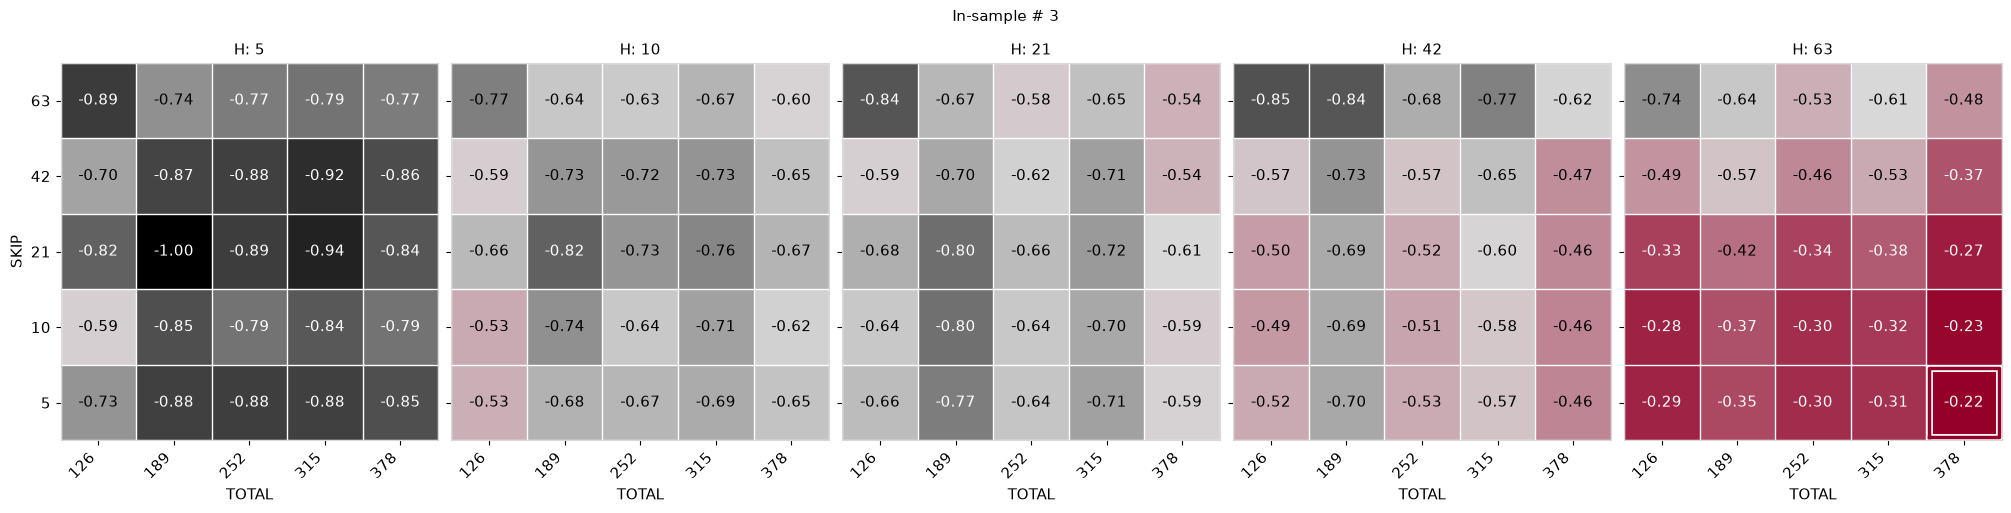

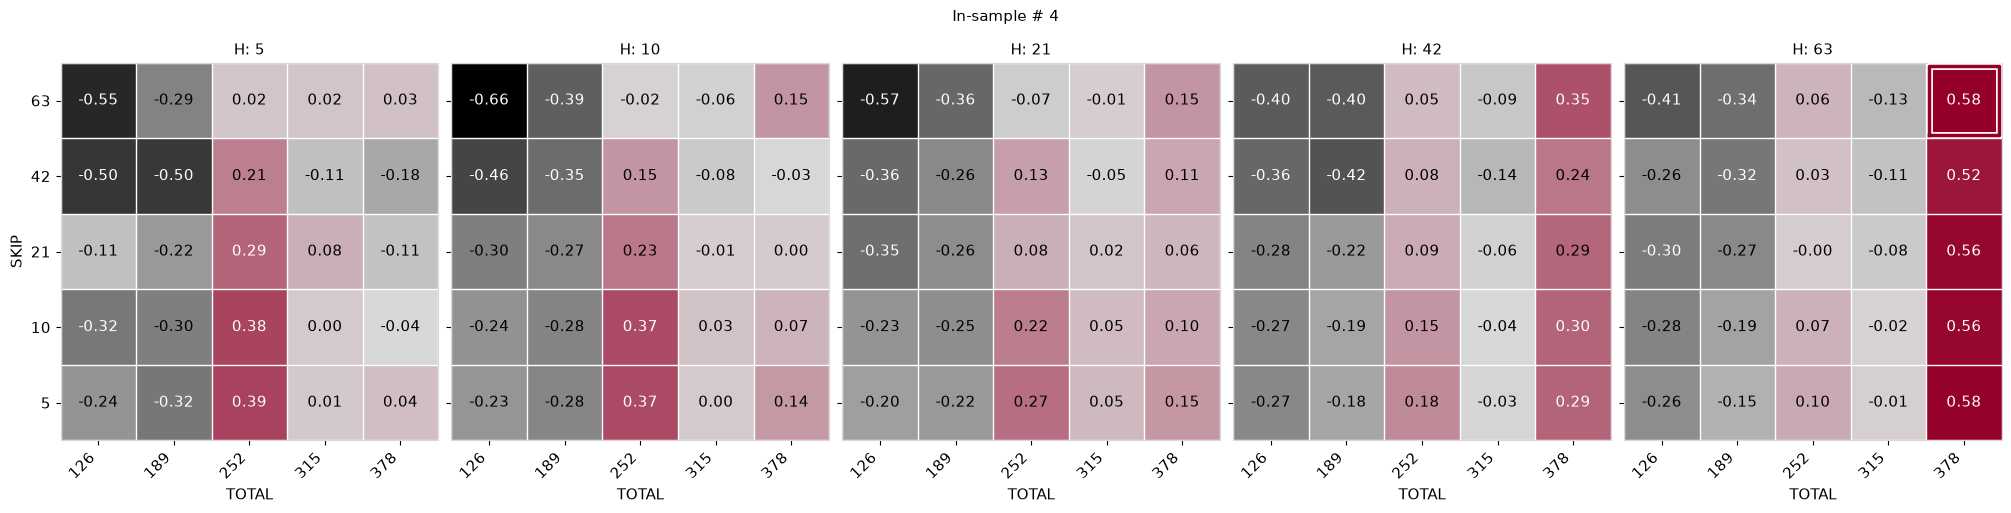

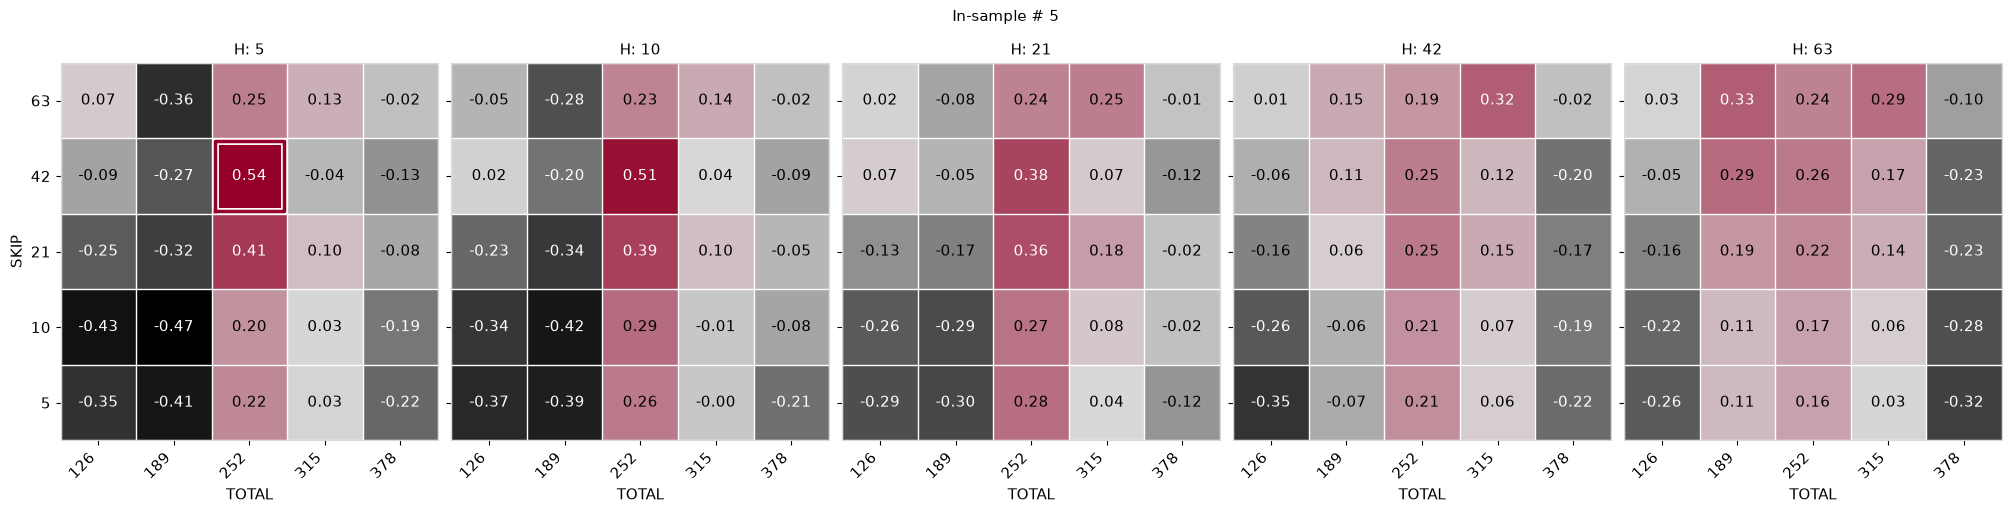

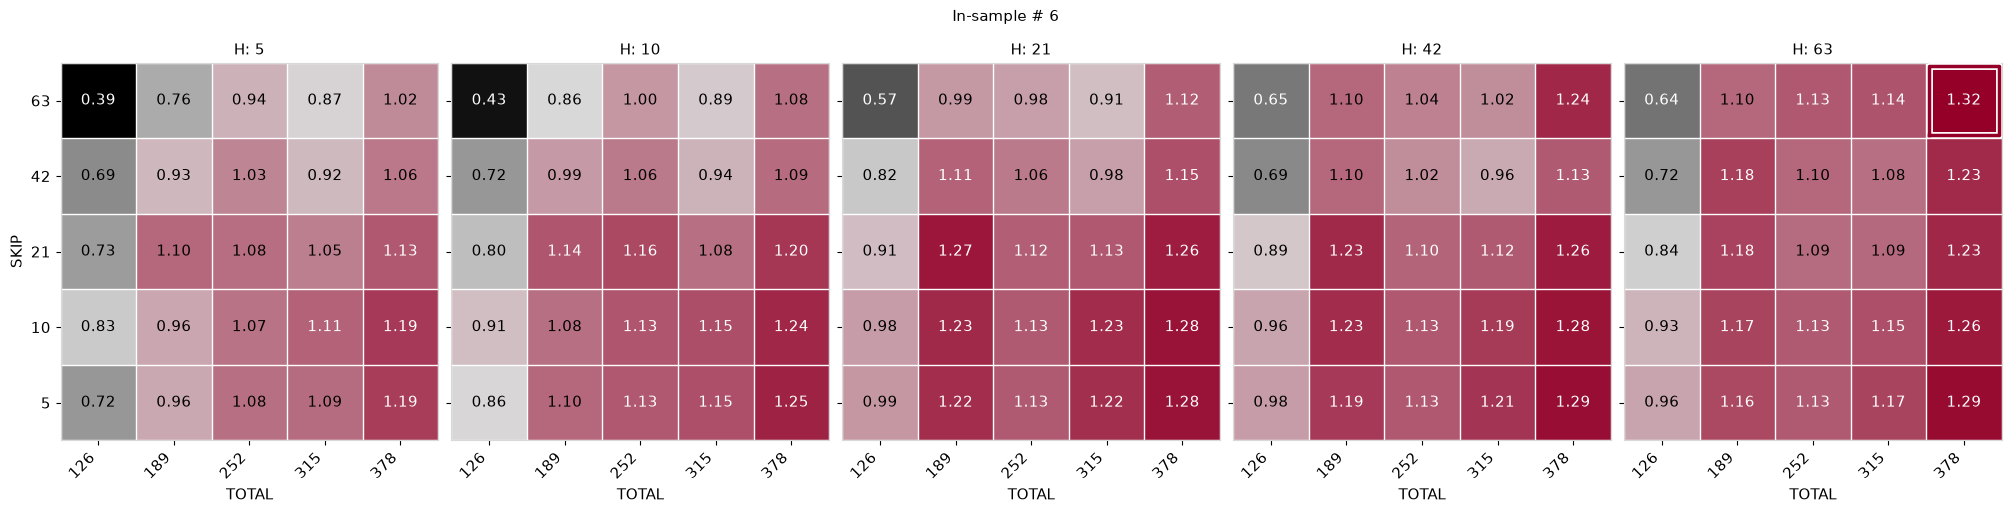

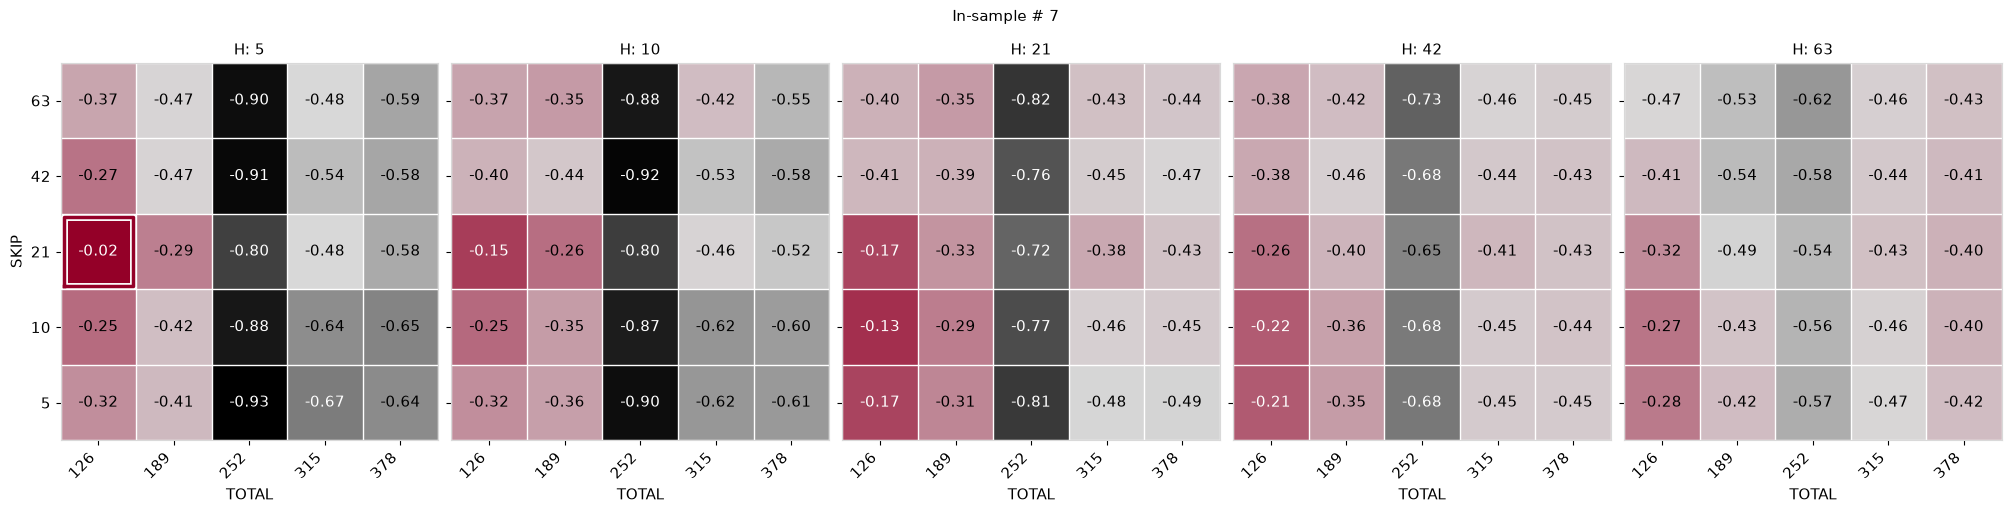

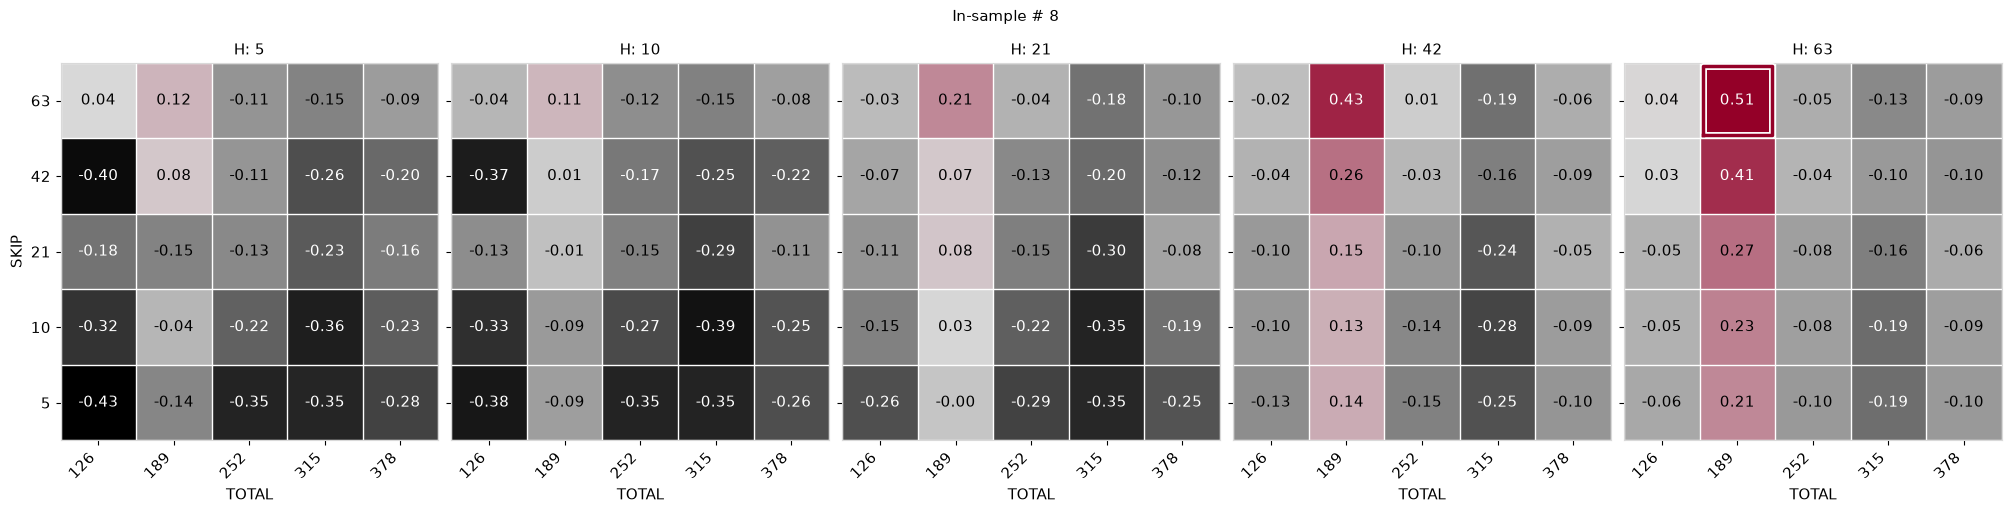

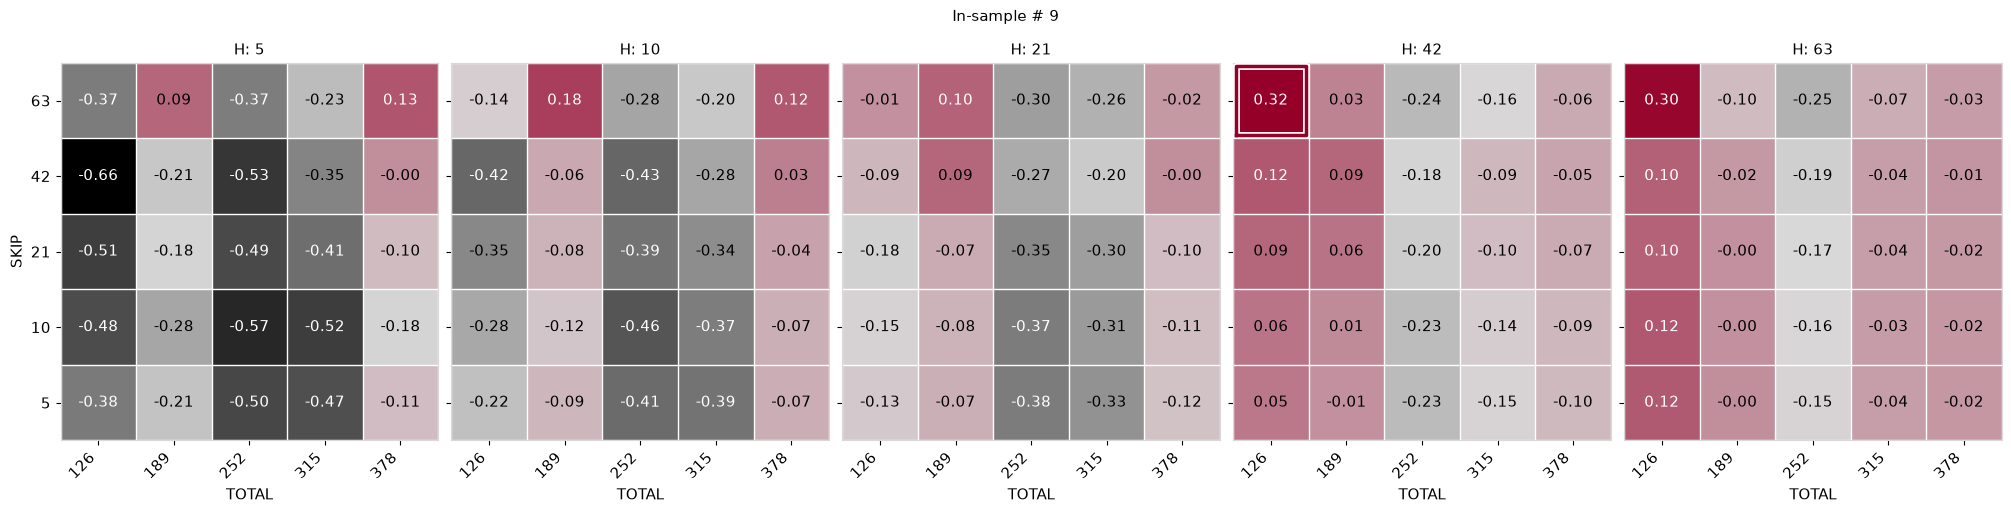

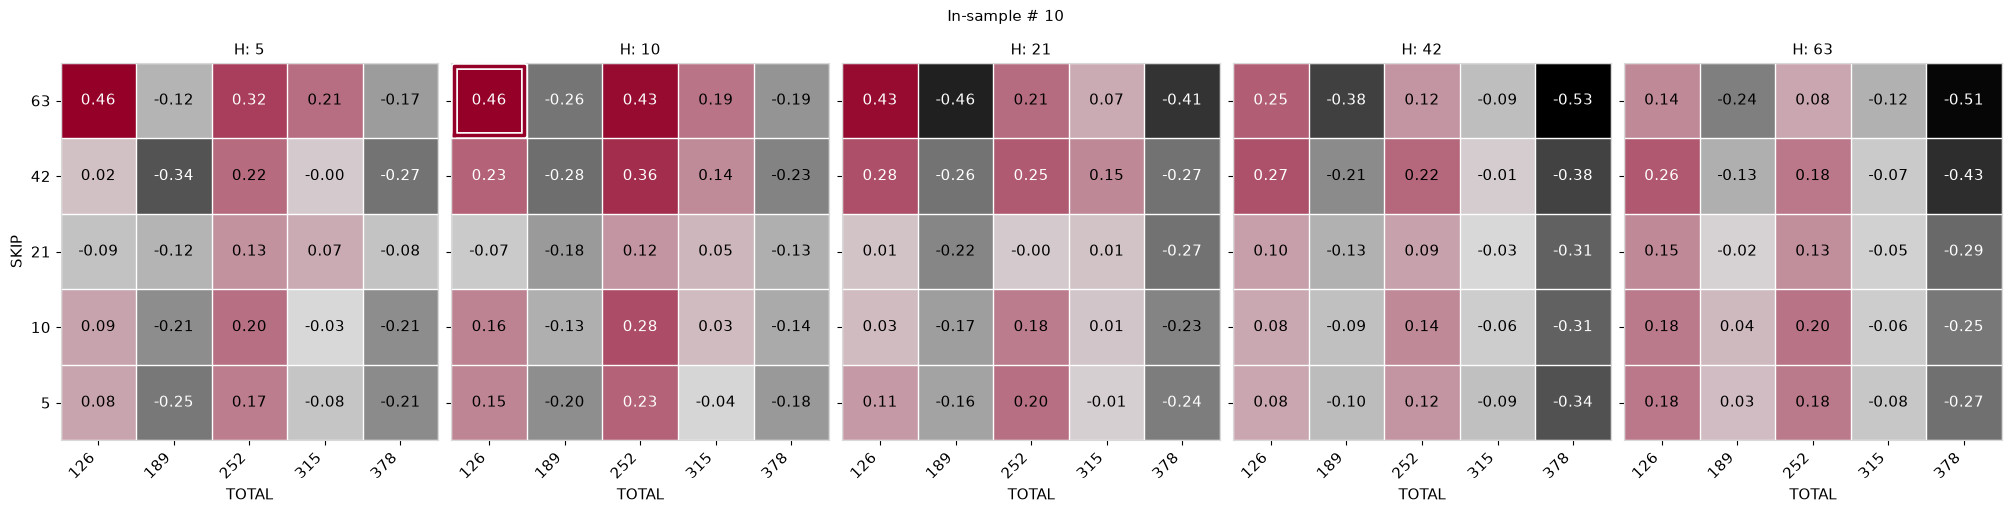

In [17]:
color_map = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "sharpe_paleta",
    [NEGRO, GRIS, PRINCIPAL],
)
color_map.set_bad(BLANCO)

for winner in wf_selections.itertuples(index=False):
    scores = wf_is_scores.loc[
        wf_is_scores["fold"] == winner.fold
    ]

    finite_scores = scores.loc[
        np.isfinite(scores["sharpe_is"]),
        "sharpe_is",
    ]

    color_min = float(finite_scores.min())
    color_max = float(finite_scores.max())

    if color_min == color_max:
        color_min -= 0.01
        color_max += 0.01

    fig, axes = plt.subplots(
        1,
        len(H_GRID),
        figsize=(20, 5),
        facecolor=BLANCO,
        constrained_layout=True,
        sharey=True,
    )

    for ax, h in zip(np.atleast_1d(axes), H_GRID):
        matrix = (
            scores.loc[scores["H"].eq(h)]
            .pivot(
                index="SKIP",
                columns="TOTAL",
                values="sharpe_is",
            )
            .reindex(index=SKIP_GRID, columns=TOTAL_GRID)
        )

        values = matrix.to_numpy(dtype=float)

        ax.imshow(
            np.ma.masked_invalid(values),
            cmap=color_map,
            vmin=color_min,
            vmax=color_max,
            origin="lower",
            aspect="equal",
            interpolation="nearest",
        )

        ax.set_facecolor(BLANCO)
        ax.set_title(f"H: {h}", color=NEGRO)
        ax.set_xlabel("TOTAL", color=NEGRO)

        ax.set_xticks(np.arange(len(TOTAL_GRID)))
        ax.set_xticklabels(TOTAL_GRID, rotation=45, ha="right")

        ax.set_yticks(np.arange(len(SKIP_GRID)))
        ax.set_yticklabels(SKIP_GRID)
        ax.tick_params(colors=NEGRO)

        ax.set_xticks(
            np.arange(len(TOTAL_GRID) + 1) - 0.5,
            minor=True,
        )
        ax.set_yticks(
            np.arange(len(SKIP_GRID) + 1) - 0.5,
            minor=True,
        )

        ax.grid(which="minor", color=BLANCO, linewidth=1)
        ax.tick_params(which="minor", bottom=False, left=False)

        for spine in ax.spines.values():
            spine.set_color(GRIS)

        # Valores con contraste adaptado al fondo.
        for y in range(len(SKIP_GRID)):
            for x in range(len(TOTAL_GRID)):
                value = values[y, x]

                if np.isfinite(value):
                    normalized = (
                        (value - color_min) / (color_max - color_min)
                    )
                    red, green, blue, _ = color_map(normalized)
                    brightness = (
                        0.299 * red + 0.587 * green + 0.114 * blue
                    )
                    text_color = NEGRO if brightness > 0.5 else BLANCO
                    label = f"{value:.2f}"
                else:
                    text_color = NEGRO
                    label = "—"

                ax.text(
                    x,
                    y,
                    label,
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=11,
                    zorder=6,
                )

        # Contorno de la combinación seleccionada.
        if h == int(winner.H):
            x = TOTAL_GRID.index(int(winner.TOTAL))
            y = SKIP_GRID.index(int(winner.SKIP))

            border_x = [
                x - 0.46, x + 0.46, x + 0.46,
                x - 0.46, x - 0.46,
            ]
            border_y = [
                y - 0.46, y - 0.46, y + 0.46,
                y + 0.46, y - 0.46,
            ]

            ax.plot(
                border_x,
                border_y,
                color=BLANCO,
                linewidth=5,
                zorder=4,
            )
            ax.plot(
                border_x,
                border_y,
                color=PRINCIPAL,
                linewidth=2.5,
                zorder=5,
            )

    np.atleast_1d(axes)[0].set_ylabel("SKIP", color=NEGRO)

    fig.suptitle(
        f"In-sample # {int(winner.fold)}",
        color=NEGRO,
    )

    fig.savefig(
        BATCH / "walk-forward-2y-2y"
        / f"in-sample-{int(winner.fold):02d}-heatmaps.png",
        dpi=300,
        facecolor=BLANCO,
    )

    plt.show()
    plt.close(fig)

In [18]:
display(
    wf_selections[[
        "fold",
        "TOTAL",
        "SKIP",
        "H",
        "sharpe_is",
        "mean_daily",
        "std_daily",
        "n_obs",
        "is_start",
        "is_end_exclusive",
        "oos_start",
        "oos_end_exclusive",
    ]].sort_values("fold").round({
        "sharpe_is": 4,
        "mean_daily": 6,
        "std_daily": 6,
    })
)

,fold,TOTAL,SKIP,H,sharpe_is,mean_daily,std_daily,n_obs,is_start,is_end_exclusive,oos_start,oos_end_exclusive
0,1,126,42,63,1.3323,0.000565,0.006730,504,2004-01-01,2006-01-01,2006-01-01,2008-01-01
1,2,189,5,21,1.4724,0.000823,0.008878,502,2006-01-01,2008-01-01,2008-01-01,2010-01-01
2,3,378,5,63,-0.2186,-0.000744,0.054041,505,2008-01-01,2010-01-01,2010-01-01,2012-01-01
3,4,378,63,63,0.5837,0.000255,0.006948,504,2010-01-01,2012-01-01,2012-01-01,2014-01-01
4,5,252,42,5,0.5428,0.000291,0.008497,502,2012-01-01,2014-01-01,2014-01-01,2016-01-01
5,6,378,63,63,1.3201,0.000735,0.008838,504,2014-01-01,2016-01-01,2016-01-01,2018-01-01
6,7,126,21,5,-0.0240,-0.000017,0.011564,503,2016-01-01,2018-01-01,2018-01-01,2020-01-01
7,8,189,63,63,0.5081,0.000274,0.008562,503,2018-01-01,2020-01-01,2020-01-01,2022-01-01
8,9,126,63,42,0.3228,0.000289,0.014202,505,2020-01-01,2022-01-01,2022-01-01,2024-01-01
9,10,126,63,10,0.4609,0.000324,0.011162,501,2022-01-01,2024-01-01,2024-01-01,2026-01-01


In [19]:
WF_FEES = BT_FEES

wf_marks = pd.read_parquet(
    BATCH / "common" / "marks.parquet"
)
wf_allowed_frame = pd.read_parquet(
    BATCH / "common" / "allowed.parquet"
)
wf_membership = pd.read_parquet(
    BATCH / "common" / "membership.parquet"
)
wf_full_calendar = wf_marks.index
wf_rics = wf_marks.columns
for frame in (wf_allowed_frame, wf_membership):
    if (
        not frame.index.equals(wf_full_calendar)
        or not frame.columns.equals(wf_rics)
    ):
        raise ValueError("Datos comunes no alineados")
wf_selected = (
    wf_selections.copy()
    .sort_values("oos_start")
    .reset_index(drop=True)
)
for column in ("TOTAL", "SKIP", "H"):
    wf_selected[column] = wf_selected[column].astype(int)
# El inicio depende del primer bloque seleccionado.
# El límite de evaluación sigue siendo fin de 2025.
wf_oos_start = pd.Timestamp(wf_selected["oos_start"].min())
wf_oos_end = min(
    pd.Timestamp(wf_selected["oos_end_exclusive"].max()),
    pd.Timestamp("2026-01-01"),
)
wf_oos_rows = np.flatnonzero(
    (wf_full_calendar >= wf_oos_start)
    & (wf_full_calendar < wf_oos_end)
)
wf_oos_calendar = wf_full_calendar.take(wf_oos_rows)
wf_close = wf_marks.iloc[wf_oos_rows]
wf_allowed = (
    wf_allowed_frame.iloc[wf_oos_rows]
    .to_numpy(dtype=bool)
)
for column in ("TOTAL", "SKIP", "H"):
    wf_selected[column] = wf_selected[column].astype(int)
wf_owner = np.full(
    len(wf_oos_calendar),
    -1,
    dtype=np.int64,
)
wf_boundary_rows = []
for j, winner in enumerate(wf_selected.itertuples(index=False)):
    rows = np.flatnonzero(
        (wf_oos_calendar >= winner.oos_start)
        & (wf_oos_calendar < winner.oos_end_exclusive)
    )
    if len(rows) == 0 or (wf_owner[rows] >= 0).any():
        raise ValueError("Bloque OOS vacío o solapado")
    wf_owner[rows] = j
    wf_boundary_rows.append(int(rows[0]))
if (wf_owner < 0).any():
    raise ValueError("Hay sesiones OOS sin configuración")
wf_boundary_rows = np.asarray(
    wf_boundary_rows,
    dtype=np.int64,
)
wf_applied = wf_selected.iloc[wf_owner][[
    "fold", "run_id", "TOTAL", "SKIP", "H",
]].copy()
wf_applied.index = wf_oos_calendar
wf_applied = wf_applied.rename_axis("date")
wf_horizons = wf_applied["H"].to_numpy(dtype=np.int64)
# Solo la adopción inicial y los cambios de configuración.
wf_transition_folds = np.flatnonzero(
    wf_selected["run_id"]
    .ne(wf_selected["run_id"].shift())
    .to_numpy()
)
wf_transition_rows = wf_boundary_rows[wf_transition_folds]
wf_transition_at = np.full(
    len(wf_oos_calendar),
    -1,
    dtype=np.int64,
)
wf_transition_at[wf_transition_rows] = np.arange(
    len(wf_transition_rows)
)
wf_ring = int(wf_horizons.max()) + 1
wf_weights = np.zeros(wf_close.shape, dtype=np.float64)
wf_targets = np.zeros((
    len(wf_transition_rows),
    len(wf_rics),
))
wf_reference_navs = np.zeros(len(wf_transition_rows))
wf_seed_expiries = np.zeros((
    len(wf_transition_rows),
    wf_ring,
    len(wf_rics),
))
for (total, skip), chosen in (
    wf_selected.drop_duplicates("run_id")
    .groupby(["TOTAL", "SKIP"], sort=False)
):
    signals = pd.read_parquet(
        BATCH / "signals"
        / f"T{int(total):03d}-S{int(skip):02d}.parquet"
    )
    for winner in chosen.itertuples(index=False):
        # Preparar sobre el calendario completo evita censurar
        # entradas por cortar la evaluación en diciembre de 2025.
        weights, _ = bt_prepare_weights(
            wf_full_calendar,
            wf_membership,
            signals,
            h=int(winner.H),
        )
        selected = (
            wf_applied["run_id"]
            .eq(winner.run_id)
            .to_numpy()
        )
        wf_weights[selected] = weights.iloc[
            wf_oos_rows[selected]
        ].to_numpy()
    del signals, weights
for run_id in wf_selected["run_id"].unique():
    folder = BATCH / "runs" / run_id
    reference_daily = pd.read_parquet(
        folder / "daily.parquet",
        columns=["nav"],
    )
    reference_orders = pd.read_parquet(
        folder / "orders.parquet",
        columns=["date", "RIC", "signed_units"],
    )
    reference_cohorts = pd.read_parquet(
        folder / "cohorts.parquet",
        columns=["RIC", "entry_date", "expiry_date", "units"],
    )
    for k in range(len(wf_transition_rows)):
        winner = wf_selected.iloc[wf_transition_folds[k]]
        if winner.run_id != run_id:
            continue
        day = int(wf_transition_rows[k])
        date = wf_oos_calendar[day]
        # NAV AFTER_OPEN: contempla también los fees históricos
        # si el lote de referencia fue ejecutado con costos.
        wf_reference_navs[k] = float(
            reference_daily.loc[date, "nav"]
        )
        wf_targets[k] = (
            reference_orders.loc[
                reference_orders["date"].le(date)
            ]
            .groupby("RIC")["signed_units"]
            .sum()
            .reindex(wf_rics, fill_value=0.0)
            .to_numpy()
        )
        active = reference_cohorts.loc[
            reference_cohorts["entry_date"].le(date)
            & reference_cohorts["expiry_date"].gt(date)
        ]
        cols = wf_rics.get_indexer(active["RIC"])
        remaining = (
            wf_full_calendar.get_indexer(active["expiry_date"])
            - wf_oos_rows[day]
        )
        if (
            (cols < 0).any()
            or (remaining < 1).any()
            or (remaining > int(winner.H)).any()
        ):
            raise ValueError("Cohortes heredadas no alineadas")
        np.add.at(
            wf_seed_expiries[k],
            ((day + remaining) % wf_ring, cols),
            active["units"].to_numpy(),
        )
    del reference_daily, reference_orders, reference_cohorts
wf_pretrade_nav = np.full(len(wf_oos_calendar), np.nan)
wf_scales = np.full(len(wf_transition_rows), np.nan)
wf_pf = vbt.Portfolio.from_order_func(
    wf_close,
    wf_order_nb,
    WF_FEES,
    pre_segment_func_nb=wf_pre_segment_nb,
    pre_segment_args=(
        wf_weights,
        wf_allowed,
        wf_horizons,
        wf_transition_at,
        wf_targets,
        wf_reference_navs,
        wf_seed_expiries,
        np.zeros((wf_ring, len(wf_rics))),
        np.zeros(len(wf_rics)),
        np.zeros(len(wf_rics)),
        np.full(
            len(wf_rics),
            SizeType.Amount,
            dtype=np.int64,
        ),
        np.full(
            len(wf_rics),
            Direction.Both,
            dtype=np.int64,
        ),
        wf_pretrade_nav,
        wf_scales,
        WF_FEES,
    ),
    post_order_func_nb=bt_post_order_nb,
    row_wise=True,
    cash_sharing=True,
    group_by=True,
    engine="rust",
    update_value=False,
    init_cash=BT_INITIAL_NAV,
    call_seq="default",
    freq="1D",
    ffill_val_price=True,
)
wf_daily = pd.DataFrame({
    "nav": bt_single_group(wf_pf.value(), wf_oos_calendar),
    "cash": bt_single_group(wf_pf.cash(), wf_oos_calendar),
    "return_net": bt_single_group(wf_pf.returns(), wf_oos_calendar),
    "pretrade_nav": wf_pretrade_nav,
    "transition": wf_transition_at >= 0,
}, index=wf_oos_calendar).rename_axis("date")
for column in ("fold", "run_id", "TOTAL", "SKIP", "H"):
    wf_daily[column] = wf_applied[column].to_numpy()
wf_orders = pd.DataFrame.from_records(
    wf_pf.order_records.copy()
)
wf_orders["date"] = wf_oos_calendar.take(
    wf_orders["idx"].to_numpy(dtype=int)
)
wf_orders["RIC"] = wf_rics.take(
    wf_orders["col"].to_numpy(dtype=int)
)
wf_orders["signed_units"] = np.where(
    wf_orders["side"].eq(OrderSide.Buy),
    wf_orders["size"],
    -wf_orders["size"],
)
wf_transitions = wf_selected.iloc[wf_transition_folds][[
    "fold", "run_id", "TOTAL", "SKIP", "H",
]].reset_index(drop=True)
wf_transitions["date"] = wf_oos_calendar.take(
    wf_transition_rows
)
wf_transitions["reference_nav_after_open"] = wf_reference_navs
wf_transitions["scale"] = wf_scales
wf_transitions["selector_pretrade_nav"] = wf_pretrade_nav[
    wf_transition_rows
]
wf_transitions["selector_nav_after_open"] = (
    wf_daily["nav"].iloc[wf_transition_rows].to_numpy()
)
wf_transitions["fees_paid"] = (
    wf_transitions["date"]
    .map(wf_orders.groupby("date")["fees"].sum())
    .fillna(0.0)
)
# No sobrescribir la matriz wf_returns del análisis IS.
wf_oos_returns = wf_daily["return_net"].to_numpy()
wf_wealth = np.r_[
    1.0,
    wf_daily["nav"].to_numpy() / BT_INITIAL_NAV,
]
wf_std = float(wf_oos_returns.std(ddof=1))
wf_metrics = pd.DataFrame([{
    "start": wf_oos_calendar[0],
    "end": wf_oos_calendar[-1],
    "observations": len(wf_oos_calendar),
    "fees": WF_FEES,
    "total_paid_fees": float(wf_orders["fees"].sum()),
    "configuration_changes": len(wf_transitions) - 1,
    "total_return": wf_wealth[-1] - 1,
    "annual_return": (
        wf_wealth[-1] ** (252 / len(wf_oos_calendar)) - 1
    ),
    "annual_volatility": wf_std * np.sqrt(252),
    "sharpe_zero_rf": (
        wf_oos_returns.mean() / wf_std * np.sqrt(252)
        if wf_std > 0 else np.nan
    ),
    "max_drawdown": np.min(
        wf_wealth / np.maximum.accumulate(wf_wealth) - 1
    ),
}])
display(wf_metrics)
display(wf_transitions)

,start,end,observations,fees,total_paid_fees,configuration_changes,total_return,annual_return,annual_volatility,sharpe_zero_rf,max_drawdown
0,2006-01-03,2025-12-31,5031,0.000605,0.122427,9,-0.642619,-0.050234,0.252347,-0.075914,-0.847258


,fold,run_id,TOTAL,SKIP,H,date,reference_nav_after_open,scale,selector_pretrade_nav,selector_nav_after_open,fees_paid
0,1,T126-S42-H63,126,42,63,2006-01-03,1.252186,0.797636,1.000000,0.998789,0.001211
1,2,T189-S05-H21,189,5,21,2008-01-02,0.825216,1.484255,1.225871,1.224831,0.001040
2,3,T378-S05-H63,378,5,63,2010-01-04,0.277673,1.288336,0.358454,0.357736,0.000718
3,4,T378-S63-H63,378,63,63,2012-01-03,0.385560,1.038728,0.400705,0.400492,0.000213
4,5,T252-S42-H05,252,42,5,2014-01-02,0.429403,0.909106,0.390853,0.390373,0.000480
5,6,T378-S63-H63,378,63,63,2016-01-04,0.522659,1.020799,0.534177,0.533530,0.000647
6,7,T126-S21-H05,126,21,5,2018-01-02,0.462567,0.942217,0.436590,0.435838,0.000752
7,8,T189-S63-H63,189,63,63,2020-01-02,0.446936,0.891514,0.399211,0.398450,0.000761
8,9,T126-S63-H42,126,63,42,2022-01-03,0.596537,0.566450,0.338340,0.337909,0.000432
9,10,T126-S63-H10,126,63,10,2024-01-02,0.427517,0.836843,0.358093,0.357765,0.000328


In [20]:
wf_results[SIGNAL_KIND] = {
    "batch": BATCH,
    "fees": WF_FEES,
    "folds": wf_folds.copy(deep=True),
    "is_scores": wf_is_scores.copy(deep=True),
    "selections": wf_selections.copy(deep=True),
    "daily": wf_daily.copy(deep=True),
    "orders": wf_orders.copy(deep=True),
    "transitions": wf_transitions.copy(deep=True),
    "metrics": wf_metrics.copy(deep=True),
}

wf_folder = BATCH / "walk-forward-2y-2y"

wf_daily.to_parquet(
    wf_folder / "oos_daily.parquet"
)
wf_orders.to_parquet(
    wf_folder / "oos_orders.parquet",
    index=False,
)
wf_transitions.to_parquet(
    wf_folder / "oos_transitions.parquet",
    index=False,
)
wf_metrics.to_parquet(
    wf_folder / "oos_metrics.parquet",
    index=False,
)

In [21]:
comparison_series = {}

for kind in ("residual", "classic"):
    selector_daily = wf_results[kind]["daily"]

    comparison_series[f"{kind}_selector"] = (
        selector_daily["return_net"]
    )

    fixed_daily = pd.read_parquet(
        BATCHES[kind]
        / "runs"
        / "T252-S21-H21"
        / "daily.parquet",
        columns=["return_net"],
    )

    comparison_series[f"{kind}_fijo"] = (
        fixed_daily["return_net"].reindex(selector_daily.index)
    )

comparison_returns = pd.DataFrame(comparison_series)

if not np.isfinite(comparison_returns.to_numpy()).all():
    raise ValueError("Fechas o retornos incompatibles entre estrategias")

# Comparación rebajada al primer open, sin retorno de adopción.
comparison_returns = comparison_returns.iloc[1:].copy()

comparison_rows = []

for strategy in comparison_returns.columns:
    returns = comparison_returns[strategy].to_numpy()
    std = returns.std(ddof=1)
    wealth = np.r_[1.0, np.cumprod(1.0 + returns)]

    comparison_rows.append({
        "strategy": strategy,
        "observations": len(returns),
        "total_return": wealth[-1] - 1,
        "annual_return": wealth[-1] ** (252 / len(returns)) - 1,
        "annual_volatility": std * np.sqrt(252),
        "sharpe_oos": (
            returns.mean() / std * np.sqrt(252)
            if std > 0 else np.nan
        ),
        "max_drawdown": np.min(
            wealth / np.maximum.accumulate(wealth) - 1
        ),
    })

comparison_summary = pd.DataFrame(comparison_rows)

display(comparison_summary.round(4))

comparison_returns.to_parquet(
    RUN_ROOT / "comparison_returns_after_initial_open.parquet"
)
comparison_summary.to_parquet(
    RUN_ROOT / "comparison_summary_after_initial_open.parquet",
    index=False,
)

# Resultados completos de ejecución: incluyen adopción inicial.
execution_summary = pd.concat(
    [
        wf_results[kind]["metrics"].assign(strategy=f"{kind}_selector")
        for kind in ("residual", "classic")
    ],
    ignore_index=True,
)

display(execution_summary.round(4))

execution_summary.to_parquet(
    RUN_ROOT / "selector_execution_summary.parquet",
    index=False,
)

,strategy,observations,total_return,annual_return,annual_volatility,sharpe_oos,max_drawdown
0,residual_selector,5030,-0.1985,-0.0110,0.1443,-0.0045,-0.4592
1,residual_fijo,5030,-0.4956,-0.0337,0.1783,-0.1024,-0.7350
2,classic_selector,5030,-0.6422,-0.0502,0.2524,-0.0757,-0.8473
3,classic_fijo,5030,-0.7422,-0.0657,0.2935,-0.0827,-0.8937


/var/folders/1s/1_hm0m591595f2bd_lb_b6g40000gn/T/ipykernel_85452/2918131427.py:73: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(execution_summary.round(4))


,start,end,observations,fees,total_paid_fees,configuration_changes,total_return,annual_return,annual_volatility,sharpe_zero_rf,max_drawdown,strategy
0,2006-01-03,2025-12-31,5031,0.0006,0.3136,9,-0.1994,-0.0111,0.1443,-0.0049,-0.4592,residual_selector
1,2006-01-03,2025-12-31,5031,0.0006,0.1224,9,-0.6426,-0.0502,0.2523,-0.0759,-0.8473,classic_selector


In [22]:
POSITION_TOL = 1e-10  # Tolerancia sobre valor de posición / NAV
FIXED_RUN = "T252-S21-H21"

def concentration_side(values):
    if len(values) == 0:
        return {
            "n": 0,
            "largest": np.nan,
            "top10": np.nan,
            "hhi": np.nan,
            "effective_n": np.nan,
        }
    shares = np.sort(values / values.sum())
    hhi = np.sum(shares**2)
    return {
        "n": len(shares),
        "largest": shares[-1],
        "top10": shares[-10:].sum(),
        "hhi": hhi,
        "effective_n": 1 / hhi,
    }

def portfolio_diagnostics(daily, orders, marks, is_selector):
    dates = daily.index
    nav = daily["nav"].to_numpy(dtype=float)
    pretrade_nav = daily["pretrade_nav"].to_numpy(dtype=float)
    prices = marks.to_numpy(dtype=float)
    if (
        not np.isfinite(nav).all()
        or not np.isfinite(pretrade_nav).all()
        or (nav <= 0).any()
        or (pretrade_nav <= 0).any()
        or not np.isfinite(prices).all()
    ):
        raise ValueError("NAV o marks inválidos")
    orders = orders.loc[
        orders["date"].le(dates[-1])
    ].copy()
    cols = marks.columns.get_indexer(orders["RIC"])
    if (cols < 0).any():
        raise ValueError("RIC de órdenes ausente de marks")
    # Posiciones heredadas: esenciales para las estrategias fijas.
    prior = orders["date"].lt(dates[0]).to_numpy()
    units = np.zeros(len(marks.columns), dtype=float)
    np.add.at(
        units,
        cols[prior],
        orders.loc[prior, "signed_units"].to_numpy(dtype=float),
    )
    orders = orders.loc[~prior].sort_values("date", kind="stable")
    order_rows = dates.get_indexer(orders["date"])
    order_cols = marks.columns.get_indexer(orders["RIC"])
    if (order_rows < 0).any():
        raise ValueError("Órdenes OOS fuera del calendario")
    signed_units = orders["signed_units"].to_numpy(dtype=float)
    notionals = (
        orders["size"].to_numpy(dtype=float)
        * orders["price"].to_numpy(dtype=float)
    )
    fees = orders["fees"].to_numpy(dtype=float)
    boundaries = np.r_[
        0,
        np.cumsum(
            np.bincount(order_rows, minlength=len(dates))
        ),
    ]
    records = []
    for i, date in enumerate(dates):
        sl = slice(boundaries[i], boundaries[i + 1])
        np.add.at(units, order_cols[sl], signed_units[sl])
        # Posiciones netas por activo, valoradas después de operar.
        weights = units * prices[i] / nav[i]
        weights = np.where(
            np.abs(weights) > POSITION_TOL,
            weights,
            0.0,
        )
        long_values = weights[weights > 0]
        short_values = -weights[weights < 0]
        long_exposure = long_values.sum()
        short_exposure = short_values.sum()
        category = "ordinary"
        if is_selector:
            if i == 0:
                category = "adoption"
            elif bool(daily["transition"].iloc[i]):
                category = "transition"
        record = {
            "date": date,
            "long": long_exposure,
            "short": short_exposure,
            "gross": long_exposure + short_exposure,
            "net": long_exposure - short_exposure,
            "turnover": notionals[sl].sum() / pretrade_nav[i],
            "fees_nav": fees[sl].sum() / pretrade_nav[i],
            "category": category,
        }
        for side, values in (
            ("long", long_values),
            ("short", short_values),
        ):
            record.update({
                f"{side}_{metric}": value
                for metric, value in concentration_side(values).items()
            })
        records.append(record)
    return pd.DataFrame(records).set_index("date")

def summarize_diagnostics(frame):
    result = {
        "start": frame.index[0],
        "end": frame.index[-1],
        "observations": len(frame),
    }
    for metric in ("long", "short", "gross", "net"):
        series = frame[metric]
        result.update({
            f"{metric}_mean": series.mean(),
            f"{metric}_p5": series.quantile(0.05),
            f"{metric}_p95": series.quantile(0.95),
            f"{metric}_max": series.max(),
        })
    for side in ("long", "short"):
        for metric in ("n", "largest", "top10", "hhi", "effective_n"):
            column = f"{side}_{metric}"
            result[f"{column}_mean"] = frame[column].mean()
        for metric in ("largest", "top10"):
            column = f"{side}_{metric}"
            result[f"{column}_p95"] = frame[column].quantile(0.95)
    result["turnover_daily_mean"] = frame["turnover"].mean()
    result["turnover_p95"] = frame["turnover"].quantile(0.95)
    result["turnover_annualized"] = 252 * frame["turnover"].mean()
    result["fees_nav_annualized"] = 252 * frame["fees_nav"].mean()
    for category in ("adoption", "transition", "ordinary"):
        selected = frame["category"].eq(category)
        # Denominador común: contribuciones suman el total anualizado.
        result[f"turnover_{category}_annualized"] = (
            252 * frame.loc[selected, "turnover"].sum() / len(frame)
        )
        result[f"fees_nav_{category}_annualized"] = (
            252 * frame.loc[selected, "fees_nav"].sum() / len(frame)
        )
    return result

diagnostics_daily = {}
summary_rows = []
fold_summary_rows = []
diagnostic_dates = None
for kind in ("residual", "classic"):
    batch = BATCHES[kind]
    wf_folder = batch / "walk-forward-2y-2y"
    selector_daily = pd.read_parquet(
        wf_folder / "oos_daily.parquet"
    )
    dates = selector_daily.index
    if diagnostic_dates is not None and not dates.equals(diagnostic_dates):
        raise ValueError("Calendarios OOS distintos entre estrategias")
    diagnostic_dates = dates
    marks = pd.read_parquet(
        batch / "common" / "marks.parquet"
    ).reindex(dates)
    folds = pd.read_parquet(wf_folder / "folds.parquet")
    for mode in ("selector", "fijo"):
        is_selector = mode == "selector"
        folder = (
            wf_folder
            if is_selector
            else batch / "runs" / FIXED_RUN
        )
        daily = (
            selector_daily
            if is_selector
            else pd.read_parquet(
                folder / "daily.parquet"
            ).reindex(dates)
        )
        orders = pd.read_parquet(
            folder / (
                "oos_orders.parquet"
                if is_selector else "orders.parquet"
            ),
            columns=[
                "date", "RIC", "signed_units",
                "size", "price", "fees",
            ],
        )
        strategy = f"{kind}_{mode}"
        diagnostics = portfolio_diagnostics(
            daily,
            orders,
            marks,
            is_selector,
        )
        diagnostics["fold"] = pd.Series(
            pd.NA,
            index=dates,
            dtype="Int64",
        )
        for fold in folds.itertuples(index=False):
            mask = (
                (dates >= fold.oos_start)
                & (dates < fold.oos_end_exclusive)
            )
            diagnostics.loc[mask, "fold"] = fold.fold
        if diagnostics["fold"].isna().any():
            raise ValueError("Fechas OOS sin fold")
        diagnostics_daily[strategy] = diagnostics
        summary_rows.append({
            "strategy": strategy,
            **summarize_diagnostics(diagnostics),
        })
        for fold_id, block in diagnostics.groupby("fold", sort=True):
            fold_summary_rows.append({
                "strategy": strategy,
                "fold": int(fold_id),
                **summarize_diagnostics(block),
            })
    del marks, orders
diagnostics_summary = pd.DataFrame(summary_rows)
diagnostics_by_fold = pd.DataFrame(fold_summary_rows)
# Tablas compactas para interpretar.
display(diagnostics_summary[[
    "strategy",
    "long_mean",
    "short_mean",
    "gross_mean",
    "net_mean",
    "turnover_daily_mean",
    "turnover_annualized",
    "fees_nav_annualized",
]].round(4))
display(diagnostics_summary[[
    "strategy",
    "long_n_mean",
    "short_n_mean",
    "long_largest_mean",
    "short_largest_mean",
    "long_top10_mean",
    "short_top10_mean",
    "long_effective_n_mean",
    "short_effective_n_mean",
]].round(4))
display(diagnostics_by_fold[[
    "strategy",
    "fold",
    "gross_mean",
    "net_mean",
    "turnover_annualized",
    "long_top10_mean",
    "short_top10_mean",
    "long_effective_n_mean",
    "short_effective_n_mean",
]].round(4))
# Guardar sin modificar los exports de las estrategias.
DIAG_ROOT = RUN_ROOT / "diagnostics"
DIAG_ROOT.mkdir(parents=True, exist_ok=True)
for strategy, diagnostics in diagnostics_daily.items():
    diagnostics.to_parquet(
        DIAG_ROOT / f"{strategy}_daily.parquet"
    )
diagnostics_summary.to_parquet(
    DIAG_ROOT / "summary.parquet",
    index=False,
)
diagnostics_by_fold.to_parquet(
    DIAG_ROOT / "by_fold.parquet",
    index=False,
)

,strategy,long_mean,short_mean,gross_mean,net_mean,turnover_daily_mean,turnover_annualized,fees_nav_annualized
0,residual_selector,1.0032,1.0031,2.0063,0.0001,0.1214,30.5936,0.0185
1,residual_fijo,1.0018,1.0020,2.0039,-0.0002,0.0684,17.2396,0.0104
2,classic_selector,1.0042,1.0048,2.0091,-0.0006,0.0827,20.8509,0.0126
3,classic_fijo,1.0038,1.0048,2.0086,-0.0010,0.0623,15.6902,0.0095


,strategy,long_n_mean,short_n_mean,long_largest_mean,short_largest_mean,long_top10_mean,short_top10_mean,long_effective_n_mean,short_effective_n_mean
0,residual_selector,89.9203,91.5279,0.0224,0.0227,0.2128,0.2111,62.6159,63.7603
1,residual_fijo,79.5164,79.6239,0.0225,0.0229,0.2150,0.2136,58.5476,59.1074
2,classic_selector,103.9692,97.1107,0.0228,0.0234,0.2098,0.2105,66.3102,64.9266
3,classic_fijo,79.6142,74.8656,0.0225,0.0230,0.2121,0.2126,58.5397,57.8930


,strategy,fold,gross_mean,net_mean,turnover_annualized,long_top10_mean,short_top10_mean,long_effective_n_mean,short_effective_n_mean
0,residual_selector,1,1.9935,0.0055,19.5473,0.2169,0.2145,59.0997,59.5971
1,residual_selector,2,2.0001,-0.0034,30.9483,0.2143,0.2131,70.6907,71.6171
2,residual_selector,3,1.9944,-0.0001,63.6373,0.2122,0.2085,56.6151,56.8461
3,residual_selector,4,2.0406,0.0099,8.9996,0.2156,0.2209,62.9025,62.5640
4,residual_selector,5,1.9872,0.0020,26.1126,0.2140,0.2111,54.1908,55.5339
5,residual_selector,6,2.0600,-0.0226,9.2397,0.2189,0.2196,62.4645,65.0385
6,residual_selector,7,1.9868,0.0060,62.2111,0.2081,0.2062,57.3061,57.1662
7,residual_selector,8,2.0041,0.0013,31.1219,0.2064,0.2013,73.4185,76.8220
8,residual_selector,9,1.9975,0.0016,9.9426,0.2130,0.2104,66.9838,69.2451
9,residual_selector,10,1.9988,0.0007,43.9946,0.2091,0.2052,62.4517,63.1295


,strategy,previous_fold,fold,previous_run,selected_run,configuration_changed,steps_TOTAL,steps_SKIP,steps_H,grid_distance,top10_shared,top10_overlap_pct,cumulative_grid_distance
0,classic,1.0,2,T126-S42-H63,T189-S05-H21,True,1.0,3.0,2.0,6.0,0.0,0.0,6.0
1,residual,1.0,2,T252-S63-H21,T126-S63-H21,True,2.0,0.0,0.0,2.0,2.0,20.0,2.0
2,classic,2.0,3,T189-S05-H21,T378-S05-H63,True,3.0,0.0,2.0,5.0,0.0,0.0,11.0
3,residual,2.0,3,T126-S63-H21,T126-S63-H05,True,0.0,0.0,2.0,2.0,8.0,80.0,4.0
4,classic,3.0,4,T378-S05-H63,T378-S63-H63,True,0.0,4.0,0.0,4.0,3.0,30.0,15.0
5,residual,3.0,4,T126-S63-H05,T378-S42-H63,True,4.0,1.0,4.0,9.0,0.0,0.0,13.0
6,classic,4.0,5,T378-S63-H63,T252-S42-H05,True,2.0,1.0,4.0,7.0,1.0,10.0,22.0
7,residual,4.0,5,T378-S42-H63,T252-S63-H10,True,2.0,1.0,3.0,6.0,2.0,20.0,19.0
8,classic,5.0,6,T252-S42-H05,T378-S63-H63,True,2.0,1.0,4.0,7.0,0.0,0.0,29.0
9,residual,5.0,6,T252-S63-H10,T378-S63-H63,True,2.0,0.0,3.0,5.0,0.0,0.0,24.0


,strategy,fold,IS,OOS,selected_run,sharpe_is,sharpe_oos,observations_oos,delta_sharpe_oos_is
0,classic,1,2004–2005,2006–2007,T126-S42-H63,1.3323,1.0502,502,-0.2821
1,residual,1,2004–2005,2006–2007,T252-S63-H21,2.1076,0.3259,502,-1.7816
2,classic,2,2006–2007,2008–2009,T189-S05-H21,1.4724,-0.7710,505,-2.2434
3,residual,2,2006–2007,2008–2009,T126-S63-H21,1.6991,-0.2623,505,-1.9614
4,classic,3,2008–2009,2010–2011,T378-S05-H63,-0.2186,0.5872,504,0.8058
5,residual,3,2008–2009,2010–2011,T126-S63-H05,-0.0486,-0.4242,504,-0.3756
6,classic,4,2010–2011,2012–2013,T378-S63-H63,0.5837,-0.1226,502,-0.7063
7,residual,4,2010–2011,2012–2013,T378-S42-H63,0.8105,-0.1587,502,-0.9692
8,classic,5,2012–2013,2014–2015,T252-S42-H05,0.5428,1.0346,504,0.4918
9,residual,5,2012–2013,2014–2015,T252-S63-H10,0.2844,1.0772,504,0.7928


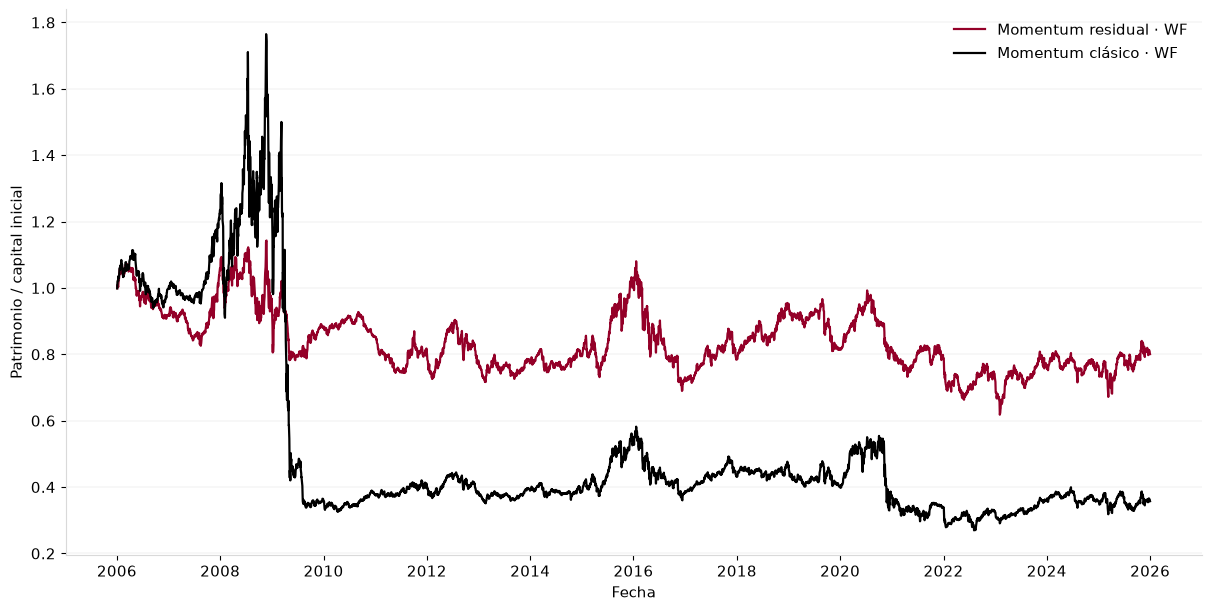

In [23]:
stability_rows = []
sharpe_rows = []
wf_nav_comparison = {}
PARAMETERS = ["TOTAL", "SKIP", "H"]
for kind in ("residual", "classic"):
    folder = BATCHES[kind] / "walk-forward-2y-2y"
    folds = (
        pd.read_parquet(folder / "folds.parquet")
        .sort_values("oos_start")
        .reset_index(drop=True)
    )
    scores = pd.read_parquet(folder / "is_scores.parquet")
    selections = pd.read_parquet(folder / "selections.parquet")
    daily = pd.read_parquet(folder / "oos_daily.parquet")
    if kind == "classic":
        if not daily.index.equals(wf_nav_comparison["residual"].index):
            raise ValueError("Calendarios OOS distintos")
    # NAV completo: no rebasa al valor posterior a la adopción.
    wf_nav_comparison[kind] = daily["nav"] / BT_INITIAL_NAV
    # Niveles realmente utilizados: no presupone SKIP=0 o SKIP=5.
    grid_ranks = {
        parameter: {
            value: rank
            for rank, value in enumerate(
                sorted(scores[parameter].unique())
            )
        }
        for parameter in PARAMETERS
    }
    previous_winner = None
    previous_top10 = None
    for fold in folds.itertuples(index=False):
        ranked = (
            scores.loc[
                scores["fold"].eq(fold.fold)
                & np.isfinite(scores["sharpe_is"])
            ]
            .sort_values(
                ["sharpe_is", *PARAMETERS],
                ascending=[False, True, True, True],
                kind="stable",
            )
        )
        if len(ranked) < 10:
            raise ValueError(
                f"{kind}, fold {fold.fold}: menos de 10 candidatos finitos"
            )
        winner = selections.loc[
            selections["fold"].eq(fold.fold)
        ].iloc[0]
        if winner["run_id"] != ranked.iloc[0]["run_id"]:
            raise ValueError("Selección y ranking IS incompatibles")
        top10 = set(
            map(tuple, ranked.head(10)[PARAMETERS].to_numpy())
        )
        if previous_winner is None:
            steps = {parameter: np.nan for parameter in PARAMETERS}
            distance = np.nan
            overlap = np.nan
            changed = pd.NA
        else:
            steps = {
                parameter: abs(
                    grid_ranks[parameter][winner[parameter]]
                    - grid_ranks[parameter][previous_winner[parameter]]
                )
                for parameter in PARAMETERS
            }
            distance = sum(steps.values())
            overlap = len(top10 & previous_top10)
            changed = distance > 0
        stability_rows.append({
            "strategy": kind,
            "previous_fold": (
                previous_winner["fold"]
                if previous_winner is not None else np.nan
            ),
            "fold": fold.fold,
            "previous_run": (
                previous_winner["run_id"]
                if previous_winner is not None else None
            ),
            "selected_run": winner["run_id"],
            "configuration_changed": changed,
            "steps_TOTAL": steps["TOTAL"],
            "steps_SKIP": steps["SKIP"],
            "steps_H": steps["H"],
            "grid_distance": distance,
            "top10_shared": overlap,
            "top10_overlap_pct": overlap * 10,
        })
        mask = (
            (daily.index >= fold.oos_start)
            & (daily.index < fold.oos_end_exclusive)
        )
        returns = daily.loc[mask, "return_net"].to_numpy(dtype=float)
        if len(returns) < 2 or not np.isfinite(returns).all():
            raise ValueError(f"{kind}, fold {fold.fold}: OOS inválido")
        std = returns.std(ddof=1)
        sharpe_rows.append({
            "strategy": kind,
            "fold": fold.fold,
            "IS": (
                f"{fold.is_start.year}–"
                f"{(fold.is_end_exclusive - pd.Timedelta(days=1)).year}"
            ),
            "OOS": (
                f"{fold.oos_start.year}–"
                f"{(fold.oos_end_exclusive - pd.Timedelta(days=1)).year}"
            ),
            "selected_run": winner["run_id"],
            "sharpe_is": winner["sharpe_is"],
            "sharpe_oos": (
                np.sqrt(252) * returns.mean() / std
                if std > 0 else np.nan
            ),
            "observations_oos": len(returns),
        })
        previous_winner = winner
        previous_top10 = top10

is_stability = pd.DataFrame(stability_rows)
is_stability["cumulative_grid_distance"] = (
    is_stability["grid_distance"]
    .fillna(0)
    .groupby(is_stability["strategy"])
    .cumsum()
)
is_oos_sharpes = (
    pd.DataFrame(sharpe_rows)
    .sort_values(["fold", "strategy"])
    .reset_index(drop=True)
)
is_oos_sharpes["delta_sharpe_oos_is"] = (
    is_oos_sharpes["sharpe_oos"]
    - is_oos_sharpes["sharpe_is"]
)
# El primer fold no tiene una selección anterior para comparar.
display(
    is_stability.loc[is_stability["previous_fold"].notna()]
    .sort_values(["fold", "strategy"])
    .reset_index(drop=True)
    .round(2)
)
display(
    is_oos_sharpes.round({
        "sharpe_is": 4,
        "sharpe_oos": 4,
        "delta_sharpe_oos_is": 4,
    })
)

wf_nav_comparison = pd.DataFrame(wf_nav_comparison)
fig, ax = plt.subplots(
    figsize=(12, 6),
    facecolor=BLANCO,
    constrained_layout=True,
)

for kind, color, label in (
    ("residual", PRINCIPAL, "Momentum residual · WF"),
    ("classic", NEGRO, "Momentum clásico · WF"),
):
    ax.plot(
        wf_nav_comparison.index,
        wf_nav_comparison[kind],
        color=color,
        linewidth=1.6,
        label=label,
    )

ax.set_xlabel("Fecha", color=NEGRO)
ax.set_ylabel("Patrimonio / capital inicial", color=NEGRO)

ax.set_facecolor(BLANCO)
ax.grid(axis="y", color=GRIS, linewidth=0.3)
ax.grid(axis="x", visible=False)
ax.tick_params(axis="both", colors=NEGRO, labelsize=11)

ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GRIS)
ax.spines["bottom"].set_color(GRIS)

ax.legend(frameon=False)

STABILITY_ROOT = RUN_ROOT / "diagnostics-stability-is-oos"
STABILITY_ROOT.mkdir(parents=True, exist_ok=True)
is_stability.to_parquet(
    STABILITY_ROOT / "selection_stability.parquet",
    index=False,
)
is_oos_sharpes.to_parquet(
    STABILITY_ROOT / "sharpe_is_oos.parquet",
    index=False,
)
wf_nav_comparison.to_parquet(
    STABILITY_ROOT / "nav_oos.parquet"
)
fig.savefig(
    STABILITY_ROOT / "nav_oos.png",
    dpi=300,
    facecolor=BLANCO,
)
plt.show()
plt.close(fig)

In [24]:
is_oos_sharpes[is_oos_sharpes["strategy"]=="classic"]

,strategy,fold,IS,OOS,selected_run,sharpe_is,sharpe_oos,observations_oos,delta_sharpe_oos_is
0,classic,1,2004–2005,2006–2007,T126-S42-H63,1.332333,1.050202,502,-0.282131
2,classic,2,2006–2007,2008–2009,T189-S05-H21,1.472381,-0.771042,505,-2.243423
4,classic,3,2008–2009,2010–2011,T378-S05-H63,-0.218581,0.587182,504,0.805763
6,classic,4,2010–2011,2012–2013,T378-S63-H63,0.583670,-0.122633,502,-0.706303
8,classic,5,2012–2013,2014–2015,T252-S42-H05,0.542791,1.034617,504,0.491826
10,classic,6,2014–2015,2016–2017,T378-S63-H63,1.320135,-0.415662,503,-1.735797
12,classic,7,2016–2017,2018–2019,T126-S21-H05,-0.023957,-0.181877,503,-0.157920
14,classic,8,2018–2019,2020–2021,T189-S63-H63,0.508111,-0.099405,505,-0.607516
16,classic,9,2020–2021,2022–2023,T126-S63-H42,0.322826,0.259998,501,-0.062828
18,classic,10,2022–2023,2024–2025,T126-S63-H10,0.460921,0.074008,502,-0.386913


In [25]:
(is_oos_sharpes[is_oos_sharpes["strategy"]=="classic"]["sharpe_oos"].mean()/is_oos_sharpes[is_oos_sharpes["strategy"]=="classic"]["sharpe_is"].mean())-1

np.float64(-0.7753579261932453)

In [26]:
is_oos_sharpes[is_oos_sharpes["strategy"]=="classic"]["sharpe_is"].mean()

np.float64(0.630062976060119)

In [27]:
is_oos_sharpes[is_oos_sharpes["strategy"]=="classic"]["sharpe_oos"].mean()

np.float64(0.14153865357100073)

In [28]:
is_oos_sharpes[is_oos_sharpes["strategy"]=="residual"]

,strategy,fold,IS,OOS,selected_run,sharpe_is,sharpe_oos,observations_oos,delta_sharpe_oos_is
1,residual,1,2004–2005,2006–2007,T252-S63-H21,2.107582,0.325948,502,-1.781635
3,residual,2,2006–2007,2008–2009,T126-S63-H21,1.699113,-0.262286,505,-1.961399
5,residual,3,2008–2009,2010–2011,T126-S63-H05,-0.048645,-0.424218,504,-0.375573
7,residual,4,2010–2011,2012–2013,T378-S42-H63,0.810520,-0.158715,502,-0.969234
9,residual,5,2012–2013,2014–2015,T252-S63-H10,0.284387,1.077216,504,0.792829
11,residual,6,2014–2015,2016–2017,T378-S63-H63,1.951426,-0.607015,503,-2.558442
13,residual,7,2016–2017,2018–2019,T126-S63-H05,0.426544,0.206052,503,-0.220492
15,residual,8,2018–2019,2020–2021,T126-S63-H21,0.219828,-0.073122,505,-0.292950
17,residual,9,2020–2021,2022–2023,T315-S63-H63,0.928510,-0.022548,501,-0.951058
19,residual,10,2022–2023,2024–2025,T126-S63-H10,0.447869,0.216597,502,-0.231272


In [29]:
(is_oos_sharpes[is_oos_sharpes["strategy"]=="residual"]["sharpe_oos"].mean()/is_oos_sharpes[is_oos_sharpes["strategy"]=="residual"]["sharpe_is"].mean())-1

np.float64(-0.9685165695946503)

In [30]:
is_oos_sharpes[is_oos_sharpes["strategy"]=="residual"]["sharpe_is"].mean()

np.float64(0.8827134762268475)

In [31]:
is_oos_sharpes[is_oos_sharpes["strategy"]=="residual"]["sharpe_oos"].mean()

np.float64(0.0277908482966523)

In [32]:
residual_oos_returns = pd.read_parquet(
    BATCHES["residual"]
    / "walk-forward-2y-2y"
    / "oos_daily.parquet",
    columns=["return_net"],
)["return_net"]
classic_oos_returns = pd.read_parquet(
    BATCHES["classic"]
    / "walk-forward-2y-2y"
    / "oos_daily.parquet",
    columns=["return_net"],
)["return_net"]
pd.testing.assert_index_equal(
    residual_oos_returns.index,
    classic_oos_returns.index,
)
display(
    residual_oos_returns.iloc[1:].vbt.returns(
        benchmark_rets=classic_oos_returns.iloc[1:],
        freq="1D",
        year_freq="252D",
    ).stats()
)

Start                        2006-01-04 00:00:00
End                          2025-12-31 00:00:00
Period                        5030 days 00:00:00
Total Return [%]                      -19.846712
Benchmark Return [%]                  -64.218559
Annualized Return [%]                  -1.102226
Annualized Volatility [%]              14.433904
Max Drawdown [%]                       45.921492
Max Drawdown Duration         4301 days 00:00:00
Sharpe Ratio                           -0.004464
Calmar Ratio                           -0.024002
Omega Ratio                              0.99919
Sortino Ratio                          -0.006072
Skew                                   -0.316541
Kurtosis                                6.934195
Tail Ratio                              0.934698
Common Sense Ratio                      0.924396
Value at Risk                          -0.014303
Alpha                                   0.006283
Beta                                     0.36167
Name: return_net, dt

,scenario,strategy,observations,compounded_return,annual_volatility,sharpe
0,OOS completo,residual,5031,-0.1994,0.1443,-0.0049
1,OOS completo,classic,5031,-0.6426,0.2523,-0.0759
2,Sin Gran Recesión,residual,4654,0.0655,0.1290,0.0912
3,Sin Gran Recesión,classic,4654,-0.0352,0.1841,0.0822
4,Sin recesión COVID-19,residual,4988,-0.2469,0.1445,-0.0267
5,Sin recesión COVID-19,classic,4988,-0.6717,0.2526,-0.0943
6,Sin ambas recesiones,residual,4611,0.0023,0.1291,0.0656
7,Sin ambas recesiones,classic,4611,-0.1136,0.1837,0.0566


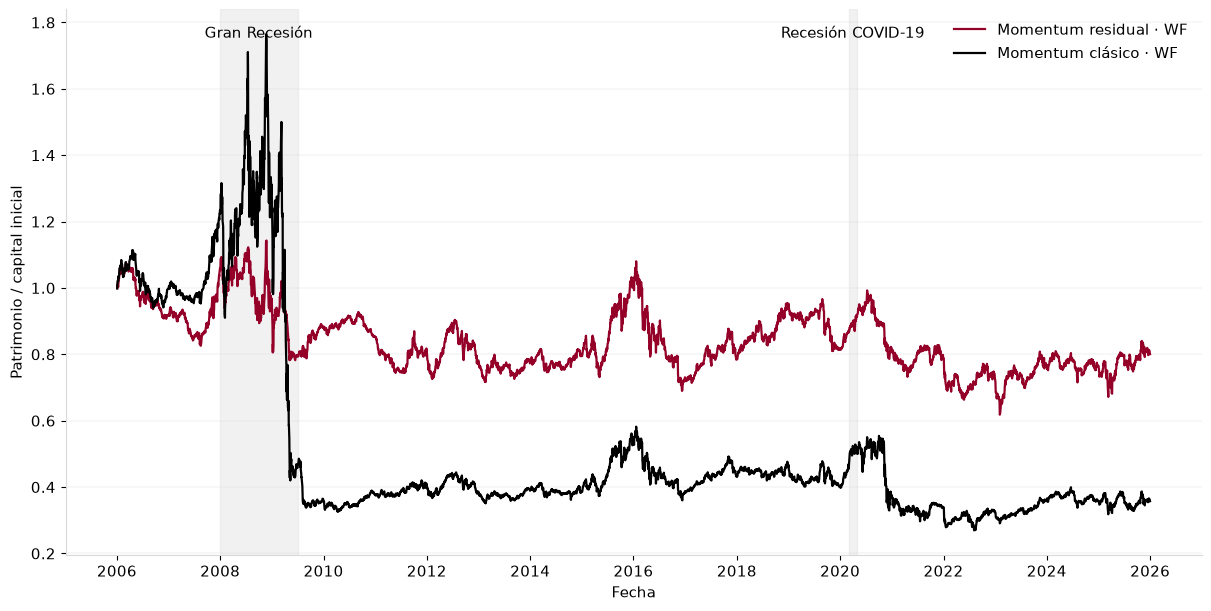

In [33]:
pd.testing.assert_index_equal(
    residual_oos_returns.index,
    classic_oos_returns.index,
)
event_returns = pd.DataFrame({
    "residual": residual_oos_returns,
    "classic": classic_oos_returns,
})
if not np.isfinite(event_returns.to_numpy()).all():
    raise ValueError("Retornos faltantes o no finitos")
event_windows = { # https://www.nber.org/research/data/us-business-cycle-expansions-and-contractions
    "Gran Recesión": (
        pd.Timestamp("2008-01-01"),
        pd.Timestamp("2009-07-01"),  # Junio incluido
    ),
    "Recesión COVID-19": (
        pd.Timestamp("2020-03-01"),
        pd.Timestamp("2020-05-01"),  # Abril incluido
    ),
}
event_masks = {
    name: (
        (event_returns.index >= start)
        & (event_returns.index < end)
    )
    for name, (start, end) in event_windows.items()
}
scenarios = {
    "OOS completo": np.ones(len(event_returns), dtype=bool),
    "Sin Gran Recesión": ~event_masks["Gran Recesión"],
    "Sin recesión COVID-19": ~event_masks["Recesión COVID-19"],
    "Sin ambas recesiones": ~(
        event_masks["Gran Recesión"]
        | event_masks["Recesión COVID-19"]
    ),
}
event_rows = []
for scenario, keep in scenarios.items():
    for strategy in event_returns.columns:
        returns = event_returns.loc[keep, strategy].to_numpy()
        std = returns.std(ddof=1)

        event_rows.append({
            "scenario": scenario,
            "strategy": strategy,
            "observations": len(returns),
            "compounded_return": np.prod(1 + returns) - 1,
            "annual_volatility": std * np.sqrt(252),
            "sharpe": (
                np.sqrt(252) * returns.mean() / std
                if std > 0 else np.nan
            ),
        })
event_summary = pd.DataFrame(event_rows)
display(event_summary.round(4))
event_nav = (1 + event_returns).cumprod()
fig, ax = plt.subplots(
    figsize=(12, 6),
    facecolor=BLANCO,
    constrained_layout=True,
)

for strategy, color, label in (
    ("residual", PRINCIPAL, "Momentum residual · WF"),
    ("classic", NEGRO, "Momentum clásico · WF"),
):
    ax.plot(
        event_nav.index,
        event_nav[strategy],
        color=color,
        linewidth=1.6,
        label=label,
    )

for name, (start, end) in event_windows.items():
    ax.axvspan(
        start,
        end,
        color=GRIS,
        alpha=0.35,
    )
    ax.text(
        start + (end - start) / 2,
        0.97,
        name,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=11,
        color=NEGRO,
    )

ax.set_xlabel("Fecha", color=NEGRO)
ax.set_ylabel("Patrimonio / capital inicial", color=NEGRO)

ax.set_facecolor(BLANCO)
ax.grid(axis="y", color=GRIS, linewidth=0.3)
ax.grid(axis="x", visible=False)
ax.tick_params(axis="both", colors=NEGRO, labelsize=11)

ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GRIS)
ax.spines["bottom"].set_color(GRIS)

ax.legend(frameon=False)

EVENT_ROOT = RUN_ROOT / "diagnostics-events"
EVENT_ROOT.mkdir(parents=True, exist_ok=True)

event_summary.to_parquet(
    EVENT_ROOT / "sensitivity.parquet",
    index=False,
)
fig.savefig(
    EVENT_ROOT / "oos_highlighted_events.png",
    dpi=300,
    facecolor=BLANCO,
)

plt.show()
plt.close(fig)

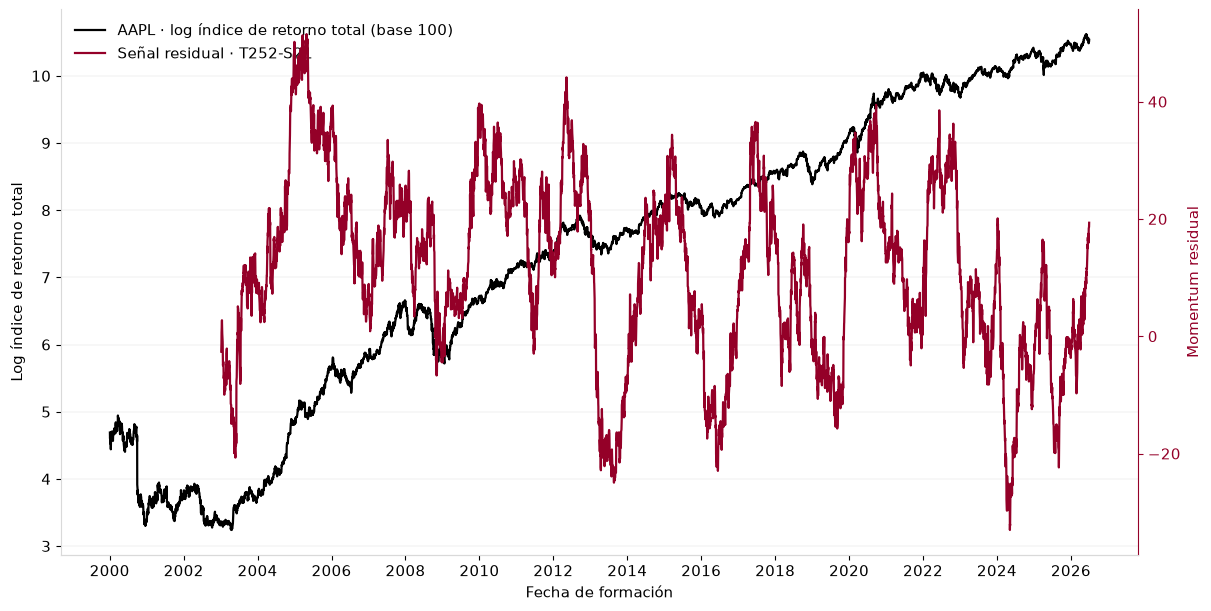

In [34]:
# Precio y señal base: usar la señal causal exportada por el motor residual.
# T252-S21 acumula 231 sesiones; H21 es tenencia, no ventana de señal.
ric = "AAPL.OQ"
base_batch = BATCHES["residual"]
prices = pd.read_parquet(
    INPUT / "equity" / f"{ric.replace('/', '_')}.parquet"
).sort_index()
signals = pd.read_parquet(
    base_batch / "signals" / "T252-S21.parquet",
    columns=[ric],
).sort_index()
problem_dates = pd.read_parquet(
    base_batch / "common" / "problem-dates.parquet"
)["date"]
total_return = prepare_total_return(prices, problem_dates)
total_return = total_return.loc[total_return.first_valid_index():]
log_price = np.log(100) + np.log1p(total_return.div(100)).cumsum()
base_plot = pd.DataFrame({
    "log_total_return": log_price.reindex(signals.index),
    "residual_momentum": signals[ric],
}).rename_axis("formation_date")

fig, ax_price = plt.subplots(
    figsize=(12, 6),
    facecolor=BLANCO,
    constrained_layout=True,
)
ax_signal = ax_price.twinx()

price_line = ax_price.plot(
    base_plot.index,
    base_plot["log_total_return"],
    color=NEGRO,
    linewidth=1.6,
    label="AAPL · log índice de retorno total (base 100)",
)
signal_line = ax_signal.plot(
    base_plot.index,
    base_plot["residual_momentum"],
    color=PRINCIPAL,
    linewidth=1.6,
    label="Señal residual · T252-S21",
)

ax_price.set_xlabel("Fecha de formación", color=NEGRO)
ax_price.set_ylabel("Log índice de retorno total", color=NEGRO)
ax_signal.set_ylabel("Momentum residual", color=PRINCIPAL)

ax_price.xaxis.set_major_locator(mdates.YearLocator(2))
ax_price.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax_price.set_facecolor(BLANCO)
ax_price.grid(axis="y", color=GRIS, linewidth=0.3)
ax_price.grid(axis="x", visible=False)
ax_signal.grid(visible=False)

ax_price.tick_params(axis="both", colors=NEGRO, labelsize=11)
ax_signal.tick_params(axis="y", colors=PRINCIPAL, labelsize=11)

ax_price.spines["top"].set_visible(False)
ax_signal.spines["top"].set_visible(False)
ax_price.spines["right"].set_visible(False)
ax_signal.spines["left"].set_visible(False)

ax_price.spines["left"].set_color(GRIS)
ax_price.spines["bottom"].set_color(GRIS)
ax_signal.spines["bottom"].set_color(GRIS)
ax_signal.spines["right"].set_color(PRINCIPAL)

lines = price_line + signal_line
ax_price.legend(
    lines,
    [line.get_label() for line in lines],
    frameon=False,
    loc="upper left",
)
base_plot.to_parquet(
    base_batch / "aapl-log-price-residual-signal-T252-S21-H21.parquet"
)
fig.savefig(
    base_batch / "aapl-log-price-residual-signal-T252-S21-H21.png",
    dpi=300, facecolor=BLANCO,
)
plt.show()
plt.close(fig)